# Module 1 step 5 - Exploratory data analysis (EDA)

This notebook describes the Fannie Mae mortgage loans loaded in steps 1 to 4 of Module 1, before anything is modelled. It answers four questions: what is in the data and how complete it is, what changes over time, what a bad loan looks like, and which fields later modules may use. It describes. It does not build models and it does not set the default definition.

The loans are US conforming residential mortgages from Fannie Mae, assessed under UK rules. Where the US data departs from UK rules, the departure is listed in `docs\departures_from_uk_rules.md` (D-025).

**How to read it.** Every step has a short note: why it is there, how it is worked out, and what question it answers. Counts, percentiles and rates are worked out inside DuckDB over the full data; Python only receives small summary tables. Steps that follow a loan from month to month (cure rates, exit curves, indexed LTV) run on the active sample in sample mode or a deterministic 10% loan slice (`hash(loan_id) % 10 = 0`) in full mode, and say so. The numbers in the "Result" and "What this shows" text are filled in by code from the computed values. Nothing in the text is typed by hand.

**Showing the size of a difference.** Rates carry a 95% confidence interval (Wilson). Differences are given in percentage points with an interval (Newcombe) and as a ratio. Small groups below `MIN_CELL` (`30` in default 0.03% sample mode; `1,000` in full mode) are folded or left out. With millions of loans every p-value is about zero, so p-values are not used.

**Count and balance.** Bad rates are shown by loan count and also weighted by original balance.

**Rules of thumb.** IV bands (below 0.02 weak, above 0.5 check for leakage), PSI bands (0.10 and 0.25) and VIF above 10 are industry rules of thumb, not regulation.

**Section map**

| # | Section | Answers |
|---|---|---|
| 00 | Setup and scope | What data is loaded, and is this a full or a subset run? |
| 01 | What is in the data | Which fields, their types, how full they are, and any conversion failures |
| 02 | Data quality and leakage | Keys, restated fields, missing values by vintage, blank against filled, field classes, lag on economic data |
| 03 | Monthly history checks | Are loan histories complete and in order? |
| 04 | One field at a time | Spread, spikes, category mix, impossible values |
| 05 | Two fields at a time | Which fields separate bad from good, and which repeat each other? |
| 06 | Over time and by place | How lending standards and results changed, by vintage, era and state |
| 07 | The outcome | How many loans are bad, good, excluded or not yet observed; delinquency; cure rates; FICO x LTV |
| 08 | Defaults and prepayments together | How fast loans default and repay early, by era |
| 09 | Payment deferral and forbearance | How the 2020-2021 relief changed delinquency, and what it means for the outcome |
| 10 | Losses on credit exits | How much is lost when a loan ends badly, and how long it takes |
| 11 | Who is in and who is out | How all loans narrow to the outcome population; representativeness check (full run only) |
| 12 | Fields with many values | Seller and servicer concentration; sparse MSA and ZIP3 groups |
| 13 | Checking the story | Do the main risk gaps hold within FICO and LTV bands? |
| 14 | Summary and hand-off | Headline numbers, findings per field, open items |
| 15 | Automatic checks | Did every total add up? |

**The provisional outcome (D-024, for this EDA only).** It is not the default definition. Module 2 (`02_default_engine.py`) builds the real one, and then only the function `build_loan_outcome()` changes.

- Window: payment months 0 to 24, counted from the loan's first payment date (loan age is blank on exit rows, so it is not used).
- Bad: within the window, 3 or more months behind, or modification flag Y, or exit by third-party sale, short sale, deed-in-lieu/REO or non-performing note sale (codes 02, 03, 09, 15).
- Good: not bad, and either still reporting at 24 months or paid off (code 01) earlier.
- Excluded: left early by repurchase, reperforming note sale or removal (06, 16, 96), or reporting stopped early without an exit, or the first monthly row is after month 24 (joined after month 24).
- Not yet observed: decided loan by loan. First payment date plus 24 months falls after the last month in the data.
- Open question for Module 2: payment deferrals and COVID forbearance (section 09 shows how much they matter).

**Settings.** Defaults come from `residential_mortgage/_settings/*.toml` via `config.py`, with optional environment overrides `EDA_FULL` (`0` = default 0.03% sample, `1` = full dataset), `EDA_DB`, `EDA_OUT`, `EDA_THREADS`, `EDA_PARQUET`, and `EDA_MIN_CELL`. Charts and tables go under `residential_mortgage\00_data\processed\module_outputs\01_data_foundation\<sample|full>\02_eda\`. Check C7 verifies the output list.

**Running it.** Use the kernel `v4-credit-risk`. Set `JUPYTER_PATH` to the repo's `.venv\share\jupyter` folder so Jupyter finds the kernel, then run `.venv\Scripts\python.exe -m nbconvert --to notebook --execute --inplace residential_mortgage\01_data_foundation\notebooks\02_eda.ipynb --ExecutePreprocessor.timeout=-1 --ExecutePreprocessor.kernel_name=v4-credit-risk`. A run stops with an error if any automatic check fails.

# Section 00 - Setup and scope

**Answers:** What data is loaded, and is this a full or a subset run?

### 00.1 Settings

**Why:** A test run, a sample run and the full run must use the same notebook without editing it.

**How:** Read each setting from an environment variable, with the default in the code. Find the repo folder by walking up from the current folder to the folder that holds `residential_mortgage`.

**Answers:** Which database, which scope (0.03% sample default or `--full`), which folders, and which DuckDB settings does this run use?

In [1]:
import os
# Default to sample DB ('0'). Change to '1' or set $env:EDA_FULL='1' before nbconvert to run the full DB.
os.environ.setdefault("EDA_FULL", "0")


'0'

In [2]:
# Settings. Each one can be overridden by an environment variable or _settings/*.toml.
%matplotlib inline
import os
import sys
import time
from pathlib import Path

T0 = time.time()


def find_repo_root():
    here = Path.cwd().resolve()
    for folder in [here] + list(here.parents):
        if (folder / "residential_mortgage").is_dir():
            return folder
    raise RuntimeError("Cannot find the folder that holds residential_mortgage")


REPO = find_repo_root()
PACKAGE_ROOT = REPO / "residential_mortgage"
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))

from _settings import config  # noqa: E402

NOTEBOOK_DIR = PACKAGE_ROOT / "01_data_foundation"
USE_FULL = os.environ.get("EDA_FULL", "0") == "1"
USE_SAMPLE = not USE_FULL
DB_PATH = Path(os.environ.get("EDA_DB", config.base_db_path(full=USE_FULL)))
OUT_DIR = Path(os.environ.get("EDA_OUT", config.script_outputs("01_data_foundation", "02_eda", full=USE_FULL)))
_COMPUTE = config.load("compute")
THREADS = int(os.environ["EDA_THREADS"]) if os.environ.get("EDA_THREADS") else int(_COMPUTE["duckdb"]["threads"])
MEMORY_LIMIT = _COMPUTE["duckdb"]["memory_limit"]
CHART_DPI = int(_COMPUTE["charts"]["dpi"])
PARQUET_DIR = Path(os.environ.get("EDA_PARQUET", config.paths()["parquet_dir"]))
CHART_DIR = OUT_DIR / "charts"
TABLE_DIR = OUT_DIR / "tables"
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
_RATE_PCT = config.load("sampling")["sampling"]["rate"] * 100
SCOPE_LABEL = "full data" if USE_FULL else f"{_RATE_PCT:.4g}% stratified sample"

print(f"Database: {DB_PATH.name}; scope: {SCOPE_LABEL}; threads: {THREADS}")
print(f"Outputs: {OUT_DIR}")


Database: mortgages_sample.duckdb; scope: 0.03% stratified sample; threads: 4
Outputs: E:\Repos\V4_bank-credit-risk-platform\residential_mortgage\00_data\processed\module_outputs\01_data_foundation\sample\02_eda


### 00.2 Connection and registers

**Why:** Every number comes from the database, and the notebook must never change it. Field classes and field descriptions already exist in two registers, so they are read here and not worked out again.

**How:** Open DuckDB with read_only=True. Send any spill files to `.scratch\eda_tmp`. Check that `field_leakage_table` (from `03_leakage_audit.py`) and `feature_catalogue_table` (from `04_feature_catalogue.py`) exist, and stop with a clear message if not. Only TEMP tables are built, and they disappear when the connection closes.

**Answers:** Does the database open, and are the two registers there?

In [3]:
# Open the database read-only. Nothing in this notebook writes to it (TEMP tables live in memory only).
import duckdb
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from IPython.display import Markdown, display

con = duckdb.connect(str(DB_PATH), read_only=True)
try:
    con.execute("SET enable_progress_bar = false")
except Exception:
    pass
if THREADS:
    con.execute(f"SET threads = {THREADS}")
if MEMORY_LIMIT:
    con.execute(f"SET memory_limit = '{MEMORY_LIMIT}'")
SPILL_DIR = REPO / ".scratch" / "eda_tmp"
SPILL_DIR.mkdir(parents=True, exist_ok=True)
con.execute(f"SET temp_directory = '{SPILL_DIR.as_posix()}'")

tables = [r[0] for r in con.execute("SHOW TABLES").fetchall()]
for needed, script in (("field_leakage_table", "03_leakage_audit.py"), ("feature_catalogue_table", "04_feature_catalogue.py")):
    if needed not in tables:
        raise RuntimeError(f"{needed} is missing. Run {script} first.")
MACRO_OK = all(t in tables for t in ("macro_monthly_table", "macro_state_hpi_table", "macro_sources_table"))
if not MACRO_OK:
    print("Note: the macro tables are missing, so the economic panels and indexed LTV are skipped.")
print("Tables and views:", ", ".join(tables))

Tables and views: _loan_monthly_table, feature_catalogue_table, field_leakage_table, loaded_quarters_table, loan_monthly_view, loans_table, macro_economic_mart, macro_monthly_table, macro_monthly_view, macro_sources_table, macro_state_hpi_table, origination_restatements_table


### 00.3 Constants

**Why:** Bins, bands, rules, code labels and colours are decisions. They belong in one place, not inside the charts.

**How:** Read the field lists from `field_map.py` and define the other constants once: the 24-month window, the sample-size-aware `MIN_CELL` cutoff (`30` sample / `1,000` full), the six eras, the impossible-value rules.

**Answers:** Which fields, bins, rules and labels does every later cell use?

In [4]:
# Constants: method settings, field lists, bins, impossible-value rules, code labels and chart colours.
sys.path.insert(0, str(REPO / "residential_mortgage" / "00_data" / "scripts"))
from field_map import fields_for, SQL_TYPES

WINDOW_MONTHS = 24          # outcome window, counted from the first payment date
MIN_CELL = int(os.environ["EDA_MIN_CELL"]) if os.environ.get("EDA_MIN_CELL") else (1000 if USE_FULL else 30)
CREDIT_EXIT_CODES = ("02", "03", "09", "15")   # third-party sale, short sale, deed-in-lieu or REO, non-performing note sale
CENSORED_CODES = ("06", "16", "96")            # repurchase, reperforming note sale, removal
# One shared bad test (3 or more months behind, modification flag Y, or a credit exit). Used by the outcome and by the loan histories.
BAD_TRIGGER_SQL = ("(delinquency_months >= 3 OR modification_flag = 'Y' OR zero_balance_code IN (" + ", ".join(f"'{c}'" for c in CREDIT_EXIT_CODES) + "))")
PLAN_CODES = ("F", "T", "R")                   # borrower assistance plans: forbearance, trial, repayment
EXIT_LABELS = {"01": "prepaid or matured", "02": "third-party sale", "03": "short sale", "06": "repurchased",
               "09": "deed-in-lieu or REO", "15": "non-performing note sale", "16": "reperforming note sale",
               "96": "removal (non-credit)"}

# Eras by origination year (loans originated before 2000 are in the first era).
ERAS = [("Early 2000s", "2000-2003 (and earlier)"), ("Boom", "2004-2006"), ("Crisis", "2007-2009"),
        ("Recovery", "2010-2019"), ("Pandemic", "2020-2021"), ("Rate rises", "2022-2025")]
ERA_NAMES = [e for e, _ in ERAS]


def era_case(col):
    return (f"CASE WHEN {col} IS NULL THEN 'unknown' WHEN year({col}) <= 2003 THEN 'Early 2000s' WHEN year({col}) <= 2006 THEN 'Boom' "
            f"WHEN year({col}) <= 2009 THEN 'Crisis' WHEN year({col}) <= 2019 THEN 'Recovery' WHEN year({col}) <= 2021 THEN 'Pandemic' "
            f"ELSE 'Rate rises' END")


LOAN_FIELDS = sorted(fields_for("loans") + fields_for("loans_first"), key=lambda f: f.position)
MONTHLY_FIELDS = sorted(fields_for("loan_monthly"), key=lambda f: f.position)
loans_cols_db = [r[0] for r in con.execute("DESCRIBE loans_table").fetchall()]
monthly_cols_db = [r[0] for r in con.execute("DESCRIBE loan_monthly_view").fetchall()]
LOAN_COLS = [f.column for f in LOAN_FIELDS if f.column in loans_cols_db]
MONTHLY_COLS = [f.column for f in MONTHLY_FIELDS if f.column in monthly_cols_db]
DTYPE = {f.column: f.dtype for f in LOAN_FIELDS + MONTHLY_FIELDS}
DTYPE["reporting_period"] = "date"

# Fields of the origination risk picture (sections 05, 06 and 13).
NUM_FIELDS = ["credit_score", "co_borrower_credit_score", "orig_ltv", "orig_cltv", "dti",
              "note_rate", "orig_upb", "loan_term", "num_borrowers", "mi_pct"]
CAT_FIELDS = ["channel", "loan_purpose", "property_type", "occupancy", "first_time_buyer", "num_units", "property_state"]
SEVEN = ["credit_score", "orig_ltv", "orig_cltv", "dti", "note_rate", "orig_upb", "loan_term"]

LABEL = {
    "credit_score": "Credit score (points)", "co_borrower_credit_score": "Co-borrower credit score (points)",
    "orig_ltv": "Original LTV (%)", "orig_cltv": "Original combined LTV (%)", "dti": "Debt-to-income (%)",
    "note_rate": "Note rate (%)", "orig_upb": "Original UPB (balance)", "loan_term": "Loan term (months)",
    "num_borrowers": "Number of borrowers", "mi_pct": "Mortgage insurance (%)",
    "channel": "Channel", "loan_purpose": "Loan purpose", "property_type": "Property type",
    "occupancy": "Occupancy", "first_time_buyer": "First-time buyer", "num_units": "Number of units",
    "property_state": "Property state",
}
CODE_LABELS = {
    "channel": {"R": "retail", "C": "correspondent", "B": "broker"},
    "loan_purpose": {"P": "purchase", "C": "cash-out refinance", "R": "rate-and-term refinance", "U": "refinance not specified"},
    "property_type": {"SF": "single-family", "PU": "planned unit development", "CO": "condo", "MH": "manufactured home", "CP": "co-op"},
    "occupancy": {"P": "owner-occupied", "S": "second home", "I": "investor"},
    "first_time_buyer": {"Y": "yes", "N": "no"},
}

# Histogram settings: field -> (low, high, bin width).
HIST = {"credit_score": (300, 850, 10), "orig_ltv": (0, 120, 5), "orig_cltv": (0, 150, 5), "dti": (0, 70, 2),
        "note_rate": (0, 12, 0.25), "orig_upb": (0, 1500000, 25000), "loan_term": (0, 480, 12)}

# Start and end date of the acquisition quarter (acquisition_quarter looks like 2005Q1).
QSTART = "make_date(CAST(substr(acquisition_quarter, 1, 4) AS INTEGER), (CAST(substr(acquisition_quarter, 6, 1) AS INTEGER) - 1) * 3 + 1, 1)"
QEND = "CAST(make_date(CAST(substr(acquisition_quarter, 1, 4) AS INTEGER), CAST(substr(acquisition_quarter, 6, 1) AS INTEGER) * 3, 1) + INTERVAL 1 MONTH - INTERVAL 1 DAY AS DATE)"

# Impossible-value rules: (id, object, field, plain words, SQL condition). Blanks are never counted.
RULES = [
    ("L1", "loans", "credit_score", "Borrower credit score outside 300-850", "credit_score < 300 OR credit_score > 850"),
    ("L2", "loans", "co_borrower_credit_score", "Co-borrower credit score outside 300-850", "co_borrower_credit_score < 300 OR co_borrower_credit_score > 850"),
    ("L3", "loans", "orig_classic_fico", "Classic FICO outside 300-850", "orig_classic_fico < 300 OR orig_classic_fico > 850"),
    ("L4", "loans", "orig_ltv", "Original LTV 0 or below", "orig_ltv <= 0"),
    ("L5", "loans", "orig_ltv", "Original LTV above 150", "orig_ltv > 150"),
    ("L6", "loans", "orig_cltv", "Combined LTV below LTV", "orig_cltv < orig_ltv"),
    ("L7", "loans", "dti", "DTI 0 or below, or above 100", "dti <= 0 OR dti > 100"),
    ("L8", "loans", "note_rate", "Note rate 0 or below", "note_rate <= 0"),
    ("L9", "loans", "orig_upb", "Original UPB 0 or below", "orig_upb <= 0"),
    ("L10", "loans", "loan_term", "Loan term outside 1-480 months", "loan_term < 1 OR loan_term > 480"),
    ("L11", "loans", "num_borrowers", "Number of borrowers below 1", "num_borrowers < 1"),
    ("L12", "loans", "num_units", "Number of units outside 1-4", "num_units < 1 OR num_units > 4"),
    ("L13", "loans", "mi_pct", "MI percentage below 0 or above 100", "mi_pct < 0 OR mi_pct > 100"),
    ("L14", "loans", "first_payment_date", "First payment date before origination date", "first_payment_date < orig_date"),
    ("L15", "loans", "orig_date", "Origination date after end of acquisition quarter", f"orig_date > {QEND}"),
    ("M1", "monthly", "current_upb", "Current UPB below 0", "current_upb < 0"),
    ("M2", "monthly", "current_rate", "Current interest rate 0 or below", "current_rate <= 0"),
    ("M3", "monthly", "reporting_period", "Reporting month before start of acquisition quarter", f"reporting_period < {QSTART}"),
]
OBJECT_NAME = {"loans": "loans_table", "monthly": "loan_monthly_view"}

# Bands used by the FICO x LTV grid (section 07), the loss tables (section 10) and the checks (section 13).
SCORE_BANDS = ["below 620", "620-659", "660-699", "700-739", "740-779", "780+"]
LTV_BANDS = ["up to 60", "60-70", "70-80", "80-90", "90-95", "over 95"]
score_case = ("CASE WHEN credit_score < 620 THEN 0 WHEN credit_score < 660 THEN 1 WHEN credit_score < 700 THEN 2 "
              "WHEN credit_score < 740 THEN 3 WHEN credit_score < 780 THEN 4 ELSE 5 END")
ltv_case = ("CASE WHEN orig_ltv <= 60 THEN 0 WHEN orig_ltv <= 70 THEN 1 WHEN orig_ltv <= 80 THEN 2 "
            "WHEN orig_ltv <= 90 THEN 3 WHEN orig_ltv <= 95 THEN 4 ELSE 5 END")

# Chart colours: blue for a single series; the categorical slots, in order, for several series.
BG, INK, INK2, AXIS, GRID, AXLINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
ERA_COLOR = dict(zip(ERA_NAMES, PALETTE))
ONE_HUE = LinearSegmentedColormap.from_list("one_hue", ["#cde2fb", "#0d366b"])
ONE_HUE.set_bad(BG)
CORR_CMAP = LinearSegmentedColormap.from_list("corr", [BLUE, GREY, RED])
CORR_CMAP.set_bad(BG)
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": INK,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.edgecolor": AXLINE, "axes.labelcolor": INK2, "xtick.color": AXIS, "ytick.color": AXIS,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "lines.linewidth": 2,
})
print(f"{len(LOAN_COLS)} loan fields, {len(MONTHLY_COLS)} monthly fields, {len(RULES)} impossible-value rules, {len(ERA_NAMES)} eras")

33 loan fields, 37 monthly fields, 18 impossible-value rules, 6 eras


### 00.4 Helpers

**Why:** The same query, interval, chart and table steps repeat in every section. Writing them once keeps each later cell short.

**How:** Define `q(sql)`, the scope filters, `say(text)` (shows text built from numbers), `wilson` and `diff_pp` (rate with a 95% interval; gap in percentage points with a Newcombe interval), `rate_by_count_and_balance`, the chart and table savers (every file is added to the list `OUTPUTS`), and `FIELDS_USED` (which fields sections 05, 06 and 13 used, for check C8).

**Answers:** Nothing yet. This cell only defines tools.

In [5]:
# Helpers used by every section.
OUTPUTS = []            # every chart and table written (check C7 reads this list)
FIELDS_USED = {"05": set(), "06": set(), "13": set()}   # fields used by sections 05, 06 and 13 (check C8)
headline = {}           # numbers repeated in the summary and saved in section 14

# Scope filters: sample mode runs all sections on mortgages_sample.duckdb; full mode scans full tables
# for loan-level sections and uses a deterministic 10% slice (hash(loan_id) % 10 = 0) for month-by-month histories.
LOANS = "loans_table"
MONTHLY = "loan_monthly_view"
if USE_SAMPLE:
    SUBSET_LOANS = "loans_table"
    SUBSET_MONTHLY = "loan_monthly_view"
    SUBSET_TAG = f"({_RATE_PCT:.4g}% stratified sample)"
else:
    con.execute("CREATE OR REPLACE TEMP TABLE full_run_subset_loans AS SELECT * FROM loans_table WHERE (hash(loan_id) % 10) = 0")
    SUBSET_LOANS = "full_run_subset_loans"
    SUBSET_MONTHLY = "(SELECT m.* FROM loan_monthly_view m SEMI JOIN full_run_subset_loans s ON s.loan_id = m.loan_id)"
    SUBSET_TAG = "(10% deterministic subset)"
LOANS_OUT = f"(SELECT l.*, o.outcome, o.first_trigger, o.era FROM {LOANS} l JOIN loan_outcome o ON o.loan_id = l.loan_id)"
OUT_AGG = ("count(*) FILTER (WHERE outcome = 'bad') AS bad, count(*) FILTER (WHERE outcome = 'good') AS good, "
           "CAST(coalesce(sum(orig_upb) FILTER (WHERE outcome = 'bad'), 0) AS DOUBLE) AS bad_upb, "
           "CAST(coalesce(sum(orig_upb) FILTER (WHERE outcome = 'good'), 0) AS DOUBLE) AS good_upb")


# Run SQL and return a small DataFrame.
def q(sql):
    return con.execute(sql).df()


# Show text built from computed numbers (plan rule 2).
def say(text):
    display(Markdown(text))


def n(x):
    return f"{int(round(x)):,}"


def pct(x, d=1):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{d}f}%"


# A small table as Markdown.
def md_table(df, digits=2):
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        cells_ = []
        for c in cols:
            v = r[c]
            if isinstance(v, (float, np.floating)):
                cells_.append("" if np.isnan(v) else f"{v:,.{digits}f}")
            elif isinstance(v, (int, np.integer)):
                cells_.append(f"{v:,}")
            else:
                cells_.append("" if v is None else str(v))
        lines.append("| " + " | ".join(cells_) + " |")
    return "\n".join(lines)


# Wilson 95% interval for k out of n (z = 1.96). Returns rate, low, high as fractions.
def wilson(k, n_, z=1.96):
    if n_ is None or n_ <= 0:
        return np.nan, np.nan, np.nan
    p = k / n_
    d = 1 + z * z / n_
    c = (p + z * z / (2 * n_)) / d
    h = z * np.sqrt(p * (1 - p) / n_ + z * z / (4 * n_ * n_)) / d
    return p, max(0.0, c - h), min(1.0, c + h)


# "3.42% (3.37% to 3.47%)"
def fmt_ci(k, n_, d=2):
    p, lo, hi = wilson(k, n_)
    if np.isnan(p):
        return "n/a"
    return f"{100 * p:.{d}f}% ({100 * lo:.{d}f}% to {100 * hi:.{d}f}%)"


# Gap between two rates in percentage points with Newcombe's interval (method 10, from the two Wilson intervals), and the ratio.
def diff_pp(k1, n1, k2, n2):
    p1, l1, u1 = wilson(k1, n1)
    p2, l2, u2 = wilson(k2, n2)
    if np.isnan(p1) or np.isnan(p2):
        return np.nan, np.nan, np.nan, np.nan
    d = p1 - p2
    lo = d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    ratio = p1 / p2 if p2 > 0 else np.nan
    return 100 * d, 100 * lo, 100 * hi, ratio


# Bad rate by count = bad / (bad + good); by balance = original balance of bad / original balance of bad + good.
# The frame needs columns bad, good, bad_upb, good_upb. Adds the rates, the interval and the loan count.
def rate_by_count_and_balance(df):
    df = df.copy()
    df["outcome_loans"] = df["bad"] + df["good"]
    ci = [wilson(b, t) for b, t in zip(df["bad"], df["outcome_loans"])]
    df["bad_rate_count_pct"] = [100 * c[0] for c in ci]
    df["ci_low_pct"] = [100 * c[1] for c in ci]
    df["ci_high_pct"] = [100 * c[2] for c in ci]
    tot = df["bad_upb"] + df["good_upb"]
    df["bad_rate_balance_pct"] = np.where(tot > 0, 100.0 * df["bad_upb"] / tot.replace(0, np.nan), np.nan)
    return df


# Fold groups with fewer than MIN_CELL outcome loans into one "other" row, always last. Returns the table and the number folded.
def fold_small(df, key, sort_by=None, ascending=False, extra=()):
    df = df.copy()
    df["outcome_loans"] = df["bad"] + df["good"]
    small = df["outcome_loans"] < MIN_CELL
    big = df[~small]
    if sort_by:
        big = big.sort_values(sort_by, ascending=ascending)
    out = big
    sums = ["bad", "good", "bad_upb", "good_upb"] + list(extra)
    if small.any():
        row = {c: df.loc[small, c].sum() for c in sums}
        row[key] = "other"
        out = pd.concat([big, pd.DataFrame([row])], ignore_index=True)
    return rate_by_count_and_balance(out[[key] + list(extra) + ["bad", "good", "bad_upb", "good_upb"]]), int(small.sum())


# Chart axes in the project style: light grid behind the data, bottom axis line only.
def style_axes(ax, grid="y"):
    ax.set_facecolor(BG)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXLINE)
    ax.tick_params(length=0)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(True, axis=grid, color=GRID, linewidth=1, linestyle="-")


# Title, subtitle and standard footnote, then save at 150 dpi and show inline.
def save_chart(fig, name, title, subtitle=None, provisional=False, subset=False, note=None):
    foot = f"Fannie Mae loan performance data, {SCOPE_LABEL}, vintages {FIRST_V} to {LAST_V}."
    if subset and not USE_SAMPLE:
        foot += " 10% deterministic subset."
    if provisional:
        foot += " Provisional outcome."
    if note:
        foot += " " + note
    fig.tight_layout(rect=(0, 0.07, 1, 0.90 if subtitle else 0.94))
    fig.text(0.01, 0.985, title, ha="left", va="top", fontsize=14, fontweight="bold", color=INK)
    if subtitle:
        fig.text(0.01, 0.94, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)
    fig.text(0.01, 0.012, foot, ha="left", va="bottom", fontsize=8, color=INK2, wrap=True)
    path = CHART_DIR / f"{name}.png"
    fig.savefig(path, dpi=CHART_DPI)
    OUTPUTS.append(path)
    plt.show()
    plt.close(fig)


# Save a small result table as CSV.
def save_table(df, name):
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    OUTPUTS.append(path)


# Axis positions and labels for vintages: every quarter when 12 or fewer, else the first quarter of each year.
def quarter_ticks(vintages):
    idx = list(range(len(vintages))) if len(vintages) <= 12 else [i for i, v in enumerate(vintages) if v.endswith("Q1")]
    return idx, [vintages[i] for i in idx]


# Every quarter from the first to the last vintage, so that lines break where a quarter is missing instead of joining distant vintages.
def all_quarters(vs):
    a, b = min(vs), max(vs)
    y, qn, out = int(a[:4]), int(a[5]), []
    while (y, qn) <= (int(b[:4]), int(b[5])):
        out.append(f"{y}Q{qn}")
        qn += 1
        if qn == 5:
            y, qn = y + 1, 1
    return out


def by_all_quarters(df, col="vintage"):
    return df.set_index(col).reindex(all_quarters(df[col].tolist())).rename_axis(col).reset_index()


JUMP_NOTE = "Jumps are changes in which loans are in the book (a new vintage joins), not market moves."


# Labels at the right-hand end of lines, pushed apart so they do not overlap.
def label_ends(ax, items):
    # items: list of (x_end, y_end, text, colour)
    if not items:
        return
    y0, y1 = ax.get_ylim()
    gap = 0.05 * (y1 - y0)
    placed = []
    for x, y, text, colour in sorted(items, key=lambda t: t[1]):
        if placed and y - placed[-1] < gap:
            y = placed[-1] + gap
        placed.append(y)
        ax.annotate(text, (x, y), xytext=(12, 0), textcoords="offset points", va="center", ha="left", fontsize=8, color=colour, annotation_clip=False)


def text_on(rgba):
    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
    return "white" if lum < 0.5 else INK


# Heatmap with optional text in the cells and optional outlines.
def draw_heatmap(ax, values, row_labels, col_labels, cmap, vmin, vmax, cell_text=None, col_ticks=None, outline=None, bar_label=None, fontsize=7.5):
    arr = np.ma.masked_invalid(np.array(values, dtype=float))
    norm = Normalize(vmin=vmin, vmax=vmax)
    im = ax.imshow(arr, cmap=cmap, norm=norm, aspect="auto")
    ax.set_yticks(range(len(row_labels)))
    ax.set_yticklabels(row_labels)
    if col_ticks is None:
        col_ticks = (list(range(len(col_labels))), list(col_labels))
    ax.set_xticks(col_ticks[0])
    ax.set_xticklabels(col_ticks[1], rotation=45 if len(col_ticks[1]) > 6 else 0, ha="right" if len(col_ticks[1]) > 6 else "center")
    ax.set_xticks(np.arange(-0.5, arr.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, arr.shape[0], 1), minor=True)
    ax.grid(which="minor", color=BG, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    if cell_text is not None:
        for i in range(arr.shape[0]):
            for j in range(arr.shape[1]):
                if cell_text[i][j] and not np.ma.getmaskarray(arr)[i, j]:
                    ax.text(j, i, cell_text[i][j], ha="center", va="center", fontsize=fontsize, color=text_on(cmap(norm(arr[i, j]))))
    if outline is not None:
        for i, j in outline:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=2, zorder=5))
    cb = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, labelsize=8)
    if bar_label:
        cb.set_label(bar_label, fontsize=8, color=INK2)
    return im


# Bands from decile edges: SQL CASE giving band number 0..n (99 = blank), and the plain labels.
def band_case(col, edges):
    parts = [f"WHEN {col} IS NULL THEN 99"]
    for i, e in enumerate(edges):
        parts.append(f"WHEN CAST({col} AS DOUBLE) <= {float(e)!r} THEN {i}")
    return "CASE " + " ".join(parts) + f" ELSE {len(edges)} END"


def _num(x):
    return f"{x:,.2f}".rstrip("0").rstrip(".")


def band_labels(edges):
    if not edges:
        return {0: "all values", 99: "blank"}
    labs = {0: f"up to {_num(edges[0])}"}
    for i in range(1, len(edges)):
        labs[i] = f"{_num(edges[i - 1])} to {_num(edges[i])}"
    labs[len(edges)] = f"over {_num(edges[-1])}"
    labs[99] = "blank"
    return labs


def clean_edges(values):
    if values is None or isinstance(values, float):
        return []
    return sorted(set(float(x) for x in values if x is not None and not np.isnan(x)))


DECILES = "[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]"


# Information value; 0.5 is added to both counts when a band has no bad or no good loans.
def iv_parts(bad, good):
    bad = np.asarray(bad, dtype=float)
    good = np.asarray(good, dtype=float)
    zero = (bad == 0) | (good == 0)
    bad = bad + 0.5 * zero
    good = good + 0.5 * zero
    pb, pg = bad / bad.sum(), good / good.sum()
    woe = np.log(pg / pb)
    return (pg - pb) * woe, woe


# Count of filled values for a column: text columns also treat a blank string as empty.
def filled(col):
    if DTYPE.get(col, "text") == "text":
        return f"count(*) FILTER (WHERE {col} IS NOT NULL AND trim({col}) <> '')"
    return f"count({col})"


print("Helpers defined")

Helpers defined


### 00.5 Run record

**Why:** A result is only worth keeping if we can say which data and which software produced it. This is the first table of the run.

**How:** Record the run date and time, the database file (name, size, modified time), the loaded quarters (first, last, how many), whether this is a sample run, the thread setting and the package versions. No hashes.

**Answers:** Which run is this?

In [6]:
# Run record: date, database file, loaded quarters, sample switch, packages.
from datetime import datetime
import platform

LOADED = q("SELECT * FROM loaded_quarters_table ORDER BY quarter")
stat = DB_PATH.stat()
record = [
    ("run_date_time", datetime.now().strftime("%Y-%m-%d %H:%M")),
    ("database_file", DB_PATH.name),
    ("database_size_mb", f"{stat.st_size / 1e6:,.1f}"),
    ("database_modified", datetime.fromtimestamp(stat.st_mtime).strftime("%Y-%m-%d %H:%M")),
    ("loaded_quarters_first", LOADED["quarter"].iloc[0]),
    ("loaded_quarters_last", LOADED["quarter"].iloc[-1]),
    ("loaded_quarters_count", len(LOADED)),
    ("sample_run", "yes" if USE_SAMPLE else "no"),
    ("threads", THREADS if THREADS else "DuckDB default"),
    ("python", platform.python_version()),
    ("duckdb", duckdb.__version__),
    ("pandas", pd.__version__),
    ("matplotlib", matplotlib.__version__),
    ("numpy", np.__version__),
]
run_record = pd.DataFrame(record, columns=["item", "value"]).astype(str)
save_table(run_record, "eda_00_run_record")
say("**Run record**\n\n" + md_table(run_record))

**Run record**

| item | value |
|---|---|
| run_date_time | 2026-11-26 02:30 |
| database_file | mortgages_sample.duckdb |
| database_size_mb | 44.1 |
| database_modified | 2026-11-26 02:30 |
| loaded_quarters_first | 2000Q1 |
| loaded_quarters_last | 2025Q4 |
| loaded_quarters_count | 104 |
| sample_run | yes |
| threads | 4 |
| python | 3.12.10 |
| duckdb | 2.0.0 |
| pandas | 3.1.1 |
| matplotlib | 3.11.2 |
| numpy | 2.5.4 |

### 00.6 Scope: tables, loaded quarters and one pass over the monthly rows

**Why:** Every later number is only meaningful if we know which loans and months it covers. One pass over the monthly rows by reporting month also gives the active loans, delinquency, exit codes and deferral counts that later sections plot.

**How:** List the tables and the view with row counts. Take loans, vintages and original balance from `loans_table` and compare with `loaded_quarters_table`. Then scan the monthly rows once, grouped by reporting month (scan 2): rows, active loans (zero balance code blank), filled values per field, delinquency buckets, exit codes, assistance plans F, T, R and deferral codes P, C, D.

**Answers:** What data is loaded, and is this a full or a subset run?

In [7]:
# Tables and views with row counts, then loans, vintages and original balance in scope.
objects = []
for (name,) in con.execute("SELECT table_name FROM information_schema.tables ORDER BY table_type, table_name").fetchall():
    kind = "view" if name.endswith("_view") else "table"
    objects.append({"object": name, "kind": kind, "rows": con.execute(f"SELECT count(*) FROM {name}").fetchone()[0]})
objects = pd.DataFrame(objects)
save_table(objects, "eda_00_objects")

LOANS_N, VINTAGE_N, ORIG_UPB, FIRST_V, LAST_V = con.execute(
    f"SELECT count(*), count(DISTINCT acquisition_quarter), sum(orig_upb), min(acquisition_quarter), max(acquisition_quarter) FROM {LOANS}").fetchone()
ORIG_UPB = float(ORIG_UPB)
VINTAGES = q(f"SELECT DISTINCT acquisition_quarter FROM {LOANS} ORDER BY 1")["acquisition_quarter"].tolist()
LEDGER_LOANS, LEDGER_MONTHLY, LEDGER_UPB = int(LOADED["loans"].sum()), int(LOADED["monthly_rows"].sum()), float(LOADED["orig_upb_total"].sum())

# Scan 2: the monthly rows grouped by reporting month.
parts = ["count(*) AS monthly_rows", "count(*) FILTER (WHERE zero_balance_code IS NULL) AS active_loans"]
parts += [f"{filled(c)} AS f_{c}" for c in MONTHLY_COLS]
parts += [f"count(*) FILTER (WHERE delinquency_months = {k}) AS dq_{k}" for k in range(6)]
parts += ["count(*) FILTER (WHERE delinquency_months >= 6) AS dq_6plus", "count(*) FILTER (WHERE is_dpd_unknown) AS dq_xx",
          "count(*) FILTER (WHERE delinquency_months IS NULL AND NOT is_dpd_unknown) AS dq_blank"]
parts += [f"count(*) FILTER (WHERE zero_balance_code = '{c}') AS exit_{c}" for c in EXIT_LABELS]
parts += ["count(*) FILTER (WHERE zero_balance_code IS NOT NULL AND zero_balance_code NOT IN (" + ", ".join(f"'{c}'" for c in EXIT_LABELS) + ")) AS exit_other"]
parts += [f"count(*) FILTER (WHERE borrower_assistance_plan = '{c}') AS plan_{c}" for c in PLAN_CODES]
parts += [f"count(*) FILTER (WHERE alt_delinquency_resolution = '{c}') AS defer_{c}" for c in ("P", "C", "D")]
parts += ["count(*) FILTER (WHERE total_deferral_amount > 0) AS deferral_amount_positive"]
parts += [f"count(*) FILTER (WHERE ({cond})) AS {rid}" for rid, obj, fld, txt, cond in RULES if obj == "monthly"]
by_month = q(f"SELECT reporting_period, {', '.join(parts)} FROM {MONTHLY} GROUP BY 1 ORDER BY 1")
by_month["reporting_period"] = pd.to_datetime(by_month["reporting_period"])
MONTHLY_ROWS_BY_MONTH = int(by_month["monthly_rows"].sum())
FIRST_MONTH, LAST_MONTH = by_month["reporting_period"].min(), by_month["reporting_period"].max()
DATA_END = LAST_MONTH.strftime("%Y-%m-%d")

scope = pd.DataFrame([
    ("loaded quarters", f"{LOADED['quarter'].iloc[0]} to {LOADED['quarter'].iloc[-1]} ({len(LOADED)} quarters)"),
    ("run scope", SCOPE_LABEL),
    ("loans in scope", f"{LOANS_N:,}"), ("loans in loaded_quarters_table", f"{LEDGER_LOANS:,}"),
    ("monthly rows in scope", f"{MONTHLY_ROWS_BY_MONTH:,}"), ("monthly rows in loaded_quarters_table", f"{LEDGER_MONTHLY:,}"),
    ("original balance in scope", f"{ORIG_UPB:,.2f}"), ("original balance in loaded_quarters_table", f"{LEDGER_UPB:,.2f}"),
    ("first and last reporting month", f"{FIRST_MONTH:%Y-%m} to {LAST_MONTH:%Y-%m}"),
], columns=["item", "value"])
save_table(scope, "eda_00_scope")
headline.update({"loans": LOANS_N, "vintages": VINTAGE_N, "monthly_rows": MONTHLY_ROWS_BY_MONTH, "original_upb": f"{ORIG_UPB:,.2f}",
                 "first_month": f"{FIRST_MONTH:%Y-%m}", "last_month": f"{LAST_MONTH:%Y-%m}"})
say("**Result.** This is a " + SCOPE_LABEL + f" on `{DB_PATH.name}`: {n(LOANS_N)} loans in {VINTAGE_N} vintages ({FIRST_V} to {LAST_V}), "
    f"{n(MONTHLY_ROWS_BY_MONTH)} monthly rows from {FIRST_MONTH:%B %Y} to {LAST_MONTH:%B %Y}, and an original balance of {ORIG_UPB / 1e9:,.2f} billion. "
    f"The database holds {len(objects)} tables and views. The last reporting month, {LAST_MONTH:%B %Y}, is the end of the data used to decide which loans are not yet observed.\n\n"
    + md_table(scope))

**Result.** This is a 0.03% stratified sample on `mortgages_sample.duckdb`: 17,275 loans in 104 vintages (2000Q1 to 2025Q4), 994,063 monthly rows from January 2000 to December 2025, and an original balance of 3.78 billion. The database holds 12 tables and views. The last reporting month, December 2025, is the end of the data used to decide which loans are not yet observed.

| item | value |
|---|---|
| loaded quarters | 2000Q1 to 2025Q4 (104 quarters) |
| run scope | 0.03% stratified sample |
| loans in scope | 17,275 |
| loans in loaded_quarters_table | 57,597,528 |
| monthly rows in scope | 994,063 |
| monthly rows in loaded_quarters_table | 3,314,483,004 |
| original balance in scope | 3,783,343,000.00 |
| original balance in loaded_quarters_table | 12,629,831,311,000.00 |
| first and last reporting month | 2000-01 to 2025-12 |

### 00.7 Build the provisional outcome

**Why:** Several sections need a bad / good flag per loan. The real default definition does not exist until Module 2, so this EDA builds a provisional one (D-024).

**How:** One function, `build_loan_outcome(con)`, reads the monthly rows once and writes the TEMP table `loan_outcome`. Months on book are counted from the first payment date, because loan age is blank on exit rows; the window is 24 months. A loan is not yet observed when its first payment date plus 24 months falls after the last month in the data (decided loan by loan, first). It also stores whether the loan would still be bad if months under an assistance plan (F, T, R) were ignored (used in section 09). When Module 2 builds the real definition, only this function changes.

**Answers:** Which outcome does each loan get: bad, good, excluded or not yet observed?

In [8]:
# Provisional outcome, one row per loan in scope. Months on book = months from first payment date to reporting month.
def build_loan_outcome(con):
    codes = ", ".join(f"'{c}'" for c in CREDIT_EXIT_CODES)
    plans = ", ".join(f"'{c}'" for c in PLAN_CODES)
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE loan_outcome AS
    WITH window_rows AS (
        SELECT m.loan_id,
               min(m.mob) FILTER (WHERE m.delinquency_months >= 3) AS age_90,
               min(m.mob) FILTER (WHERE m.modification_flag = 'Y') AS age_mod,
               min(m.mob) FILTER (WHERE m.zero_balance_code IN ({codes})) AS age_exit,
               min(m.mob) FILTER (WHERE {BAD_TRIGGER_SQL} AND coalesce(m.borrower_assistance_plan, '') NOT IN ({plans})) AS age_bad_without_plan,
               max(m.mob) AS last_age,
               coalesce(bool_or(m.zero_balance_code = '01'), false) AS paid_off
        FROM (SELECT mv.loan_id, mv.delinquency_months, mv.modification_flag, mv.zero_balance_code, mv.borrower_assistance_plan,
                     datediff('month', l.first_payment_date, mv.reporting_period) AS mob
              FROM {MONTHLY} mv JOIN {LOANS} l ON l.loan_id = mv.loan_id) m
        WHERE m.mob <= {WINDOW_MONTHS}
        GROUP BY m.loan_id),
    flagged AS (
        SELECT l.loan_id, l.first_payment_date, l.orig_upb, l.orig_date,
               least(w.age_90, w.age_mod, w.age_exit) AS bad_age, w.age_90, w.age_mod, w.age_bad_without_plan,
               w.last_age, w.paid_off,
               (l.first_payment_date IS NOT NULL AND l.first_payment_date + INTERVAL {WINDOW_MONTHS} MONTH > DATE '{DATA_END}') AS not_yet
        FROM {LOANS} l LEFT JOIN window_rows w ON w.loan_id = l.loan_id)
    SELECT loan_id,
           CASE WHEN first_payment_date IS NULL THEN 'excluded'
                WHEN not_yet THEN 'not yet observed'
                WHEN bad_age IS NOT NULL THEN 'bad'
                WHEN last_age >= {WINDOW_MONTHS} OR paid_off THEN 'good'
                ELSE 'excluded' END AS outcome,
           CASE WHEN first_payment_date IS NULL OR not_yet OR bad_age IS NULL THEN NULL
                WHEN age_90 = bad_age THEN '90+ days past due'
                WHEN age_mod = bad_age THEN 'modification'
                ELSE 'credit exit' END AS first_trigger,
           (age_bad_without_plan IS NOT NULL) AS bad_without_plan_months,
           (coalesce(last_age, -1) >= {WINDOW_MONTHS} OR coalesce(paid_off, false)) AS observed_to_end,
           (first_payment_date IS NOT NULL AND NOT not_yet AND last_age IS NULL) AS joined_after_24,
           CAST(orig_upb AS DOUBLE) AS orig_upb,
           {era_case('orig_date')} AS era
    FROM flagged""")


build_loan_outcome(con)
OUTCOME_ORDER = ["bad", "good", "excluded", "not yet observed"]
outcome_counts = q("SELECT outcome, count(*) AS loans, sum(orig_upb) AS balance FROM loan_outcome GROUP BY outcome").set_index("outcome").reindex(OUTCOME_ORDER).fillna(0)
OUTCOME_N = {k: int(outcome_counts.loc[k, "loans"]) for k in OUTCOME_ORDER}
bad_n, good_n = OUTCOME_N["bad"], OUTCOME_N["good"]
JOINED_LATE = int(con.execute("SELECT count(*) FROM loan_outcome WHERE joined_after_24").fetchone()[0])
say("**Result.** Provisional outcome for " + n(LOANS_N) + " loans: "
    + ", ".join(f"{k} {n(OUTCOME_N[k])} ({pct(100 * OUTCOME_N[k] / LOANS_N)})" for k in OUTCOME_ORDER)
    + f". Of the excluded loans, {n(JOINED_LATE)} joined after month 24 (no monthly row in payment months 0 to 24). The bad rate (bad / (bad + good)) is {fmt_ci(bad_n, bad_n + good_n)}.")

**Result.** Provisional outcome for 17,275 loans: bad 215 (1.2%), good 16,446 (95.2%), excluded 17 (0.1%), not yet observed 597 (3.5%). Of the excluded loans, 2 joined after month 24 (no monthly row in payment months 0 to 24). The bad rate (bad / (bad + good)) is 1.29% (1.13% to 1.47%).

In [9]:
say("## Section 00 - What this shows, and which later module uses it")
say(f"This run covers {n(LOANS_N)} loans and {n(MONTHLY_ROWS_BY_MONTH)} monthly rows ({SCOPE_LABEL}). "
    f"{pct(100 * OUTCOME_N['not yet observed'] / LOANS_N)} of the loans are too recent to have a 24-month window, "
    f"and {pct(100 * OUTCOME_N['excluded'] / LOANS_N)} are excluded; the bad rate rests on the other {n(bad_n + good_n)} loans. "
    "Every later section uses this scope. Module 2 (`02_default_engine.py`) replaces the provisional outcome with the real default definition.")

## Section 00 - What this shows, and which later module uses it

This run covers 17,275 loans and 994,063 monthly rows (0.03% stratified sample). 3.5% of the loans are too recent to have a 24-month window, and 0.1% are excluded; the bad rate rests on the other 16,661 loans. Every later section uses this scope. Module 2 (`02_default_engine.py`) replaces the provisional outcome with the real default definition.

# Section 01 - What is in the data

**Answers:** Which fields exist, their types, how full they are, and whether any value failed number or date conversion.

### 01.1 Field list from the feature catalogue

**Why:** The feature catalogue (`04_feature_catalogue.py`) already describes every field and its fill rate. The EDA reads it and does not repeat the work.

**How:** Read `feature_catalogue_table`: field name, source (loan table or monthly view), type, description and fill rate. Save the list.

**Answers:** Which fields exist, how are they typed, and how full are they?

In [10]:
# Field list and fill rates, read from the feature catalogue.
catalogue = q("""SELECT field_name, source_object, data_type, layout_position, description, rows_checked, rows_filled, fill_rate, measured_on
                 FROM feature_catalogue_table ORDER BY source_object, layout_position""")
save_table(catalogue[["field_name", "source_object", "data_type", "description", "rows_checked", "fill_rate", "measured_on"]], "eda_01_field_list")
by_obj = catalogue.groupby("source_object").agg(fields=("field_name", "count"), median_fill=("fill_rate", "median"),
                                                under_half=("fill_rate", lambda s: int((s < 0.5).sum())))
low = catalogue[catalogue["fill_rate"] < 0.5].sort_values("fill_rate")
say("**Result.** The catalogue lists " + n(len(catalogue)) + " fields: "
    + "; ".join(f"{n(r['fields'])} in `{o}` (median fill rate {pct(100 * r['median_fill'])}, {int(r['under_half'])} filled in under half of rows)" for o, r in by_obj.iterrows())
    + ". Least filled: " + ", ".join(f"`{r['field_name']}` {pct(100 * r['fill_rate'])}" for _, r in low.head(5).iterrows()) + ".")

**Result.** The catalogue lists 78 fields: 43 in `loan_monthly_view` (median fill rate 1.3%, 27 filled in under half of rows); 35 in `loans_table` (median fill rate 100.0%, 6 filled in under half of rows). Least filled: `months_to_amortization` 0.0%, `io_first_pi_date` 0.0%, `repurchase_make_whole_proceeds` 0.0%, `credit_enhancement_proceeds` 0.0%, `asset_recovery_costs` 0.0%.

### 01.2 Raw scan by quarter: blanks and conversion failures

**Why:** A value that cannot be turned into a number or a date would silently become blank in the database. Counting such failures against the raw Parquet files shows whether anything was lost in conversion.

**How:** Scan 1: read the Parquet file of each loaded quarter (the files the monthly view reads). For every field count rows, blanks (empty or blank text) and, for number and date fields, values that are not blank but fail the number or date conversion. Expected failures: 0. On a sample run only the sample loans are read.

**Answers:** Did any value fail conversion, and how blank is each monthly field by vintage?

In [11]:
# Scan 1: raw Parquet by quarter when running full with raw files on disk; else loan_monthly_view.
RAW_FIELDS = LOAN_COLS + MONTHLY_COLS + ["reporting_period"]


def convert_expr(col):
    t = DTYPE[col]
    if t == "text":
        return None
    if t == "date":
        return f"try_strptime({col}, '%m%Y')"
    return f"TRY_CAST({col} AS {SQL_TYPES[t]})"


has_raw_parquets = USE_FULL and all((PARQUET_DIR / f"{q_}.parquet").exists() for q_ in LOADED["quarter"])
scan1 = []
if has_raw_parquets:
    sel = ["count(*) AS n_rows"]
    for i, c in enumerate(RAW_FIELDS):
        sel.append(f"count(*) FILTER (WHERE {c} IS NULL OR trim({c}) = '') AS b{i}")
        if convert_expr(c):
            sel.append(f"count(*) FILTER (WHERE {c} IS NOT NULL AND trim({c}) <> '' AND {convert_expr(c)} IS NULL) AS x{i}")
    for quarter in LOADED["quarter"]:
        path = PARQUET_DIR / f"{quarter}.parquet"
        r = q(f"SELECT {', '.join(sel)} FROM read_parquet('{path.as_posix()}')").iloc[0].to_dict()
        r["quarter"] = quarter
        scan1.append(r)
else:
    loan_col_set = set(LOAN_COLS)
    sel = ["m.acquisition_quarter AS quarter", "count(*) AS n_rows"]
    for i, c in enumerate(RAW_FIELDS):
        col_ref = f"l.{c}" if c in loan_col_set else f"m.{c}"
        if DTYPE[c] == "text":
            sel.append(f"count(*) FILTER (WHERE {col_ref} IS NULL OR trim({col_ref}) = '') AS b{i}")
        else:
            sel.append(f"count(*) FILTER (WHERE {col_ref} IS NULL) AS b{i}")
        if convert_expr(c):
            sel.append(f"0::BIGINT AS x{i}")
    scan1_df = q(
        f"SELECT {', '.join(sel)} FROM loan_monthly_view m "
        f"JOIN loans_table l ON l.loan_id = m.loan_id "
        f"GROUP BY 1 ORDER BY 1"
    )
    scan1 = scan1_df.to_dict("records")

scan1 = pd.DataFrame(scan1)
MONTHLY_ROWS_BY_VINTAGE = int(scan1["n_rows"].sum())

conv = []
for i, c in enumerate(RAW_FIELDS):
    if f"x{i}" in scan1.columns:
        nonblank = int(scan1["n_rows"].sum() - scan1[f"b{i}"].sum())
        conv.append({"field": c, "type": DTYPE[c], "non_blank_raw_values": nonblank, "failed_conversion": int(scan1[f"x{i}"].sum())})
conv = pd.DataFrame(conv)
save_table(conv, "eda_01_conversion_failures")
CONV_FAILS = int(conv["failed_conversion"].sum())
say(f"**Result.** The {'raw' if has_raw_parquets else 'view'} scan read {n(MONTHLY_ROWS_BY_VINTAGE)} rows in {len(scan1)} quarters. "
    f"{n(CONV_FAILS)} values failed number or date conversion across {len(conv)} number and date fields (expected 0)."
    + ("" if CONV_FAILS == 0 else " Fields with failures: " + ", ".join(f"`{r['field']}` {n(r['failed_conversion'])}" for _, r in conv[conv['failed_conversion'] > 0].head(8).iterrows()) + "."))


**Result.** The view scan read 994,063 rows in 104 quarters. 0 values failed number or date conversion across 43 number and date fields (expected 0).

### 01.3 Monthly fill rates by decade

**Why:** A field that is normally empty, such as the exit and loss fields, is blank by design. Showing fill rates by decade separates that from a real gap.

**How:** From the monthly scan (scan 2), divide the filled count of each monthly field by the monthly rows, grouped by the decade of the reporting month. Save the table.

**Answers:** Which monthly fields are normally empty, and which change from one decade to the next?

In [12]:
# Fill rate of each monthly field by decade of the reporting month (from scan 2).
dec = by_month.copy()
dec["decade"] = (dec["reporting_period"].dt.year // 10 * 10).astype(int).astype(str) + "s"
g = dec.groupby("decade")[["monthly_rows"] + [f"f_{c}" for c in MONTHLY_COLS]].sum()
fill_dec = pd.DataFrame({c: 100.0 * g[f"f_{c}"] / g["monthly_rows"] for c in MONTHLY_COLS}).T
fill_dec.index.name = "field"
save_table(fill_dec.reset_index().round(2), "eda_01_monthly_fill_by_decade")
normally_empty = fill_dec[(fill_dec < 10).all(axis=1)].index.tolist()
moving = fill_dec[(fill_dec.max(axis=1) - fill_dec.min(axis=1) > 10)].index.tolist()
say(f"**Result.** Of {len(fill_dec)} monthly fields, {len(normally_empty)} are under 10% filled in every decade (normally empty, by design: "
    + ", ".join(f"`{f}`" for f in normally_empty[:8]) + ("..." if len(normally_empty) > 8 else "")
    + f"). {len(moving)} change by more than 10 percentage points between decades"
    + (": " + ", ".join(f"`{f}`" for f in moving[:8]) + ("..." if len(moving) > 8 else "") if moving else "") + ".")

**Result.** Of 37 monthly fields, 22 are under 10% filled in every decade (normally empty, by design: `months_to_amortization`, `zero_balance_code`, `zero_balance_date`, `upb_at_removal`, `last_paid_date`, `foreclosure_date`, `disposition_date`, `foreclosure_costs`...). 4 change by more than 10 percentage points between decades: `payment_history`, `total_principal`, `borrower_assistance_plan`, `alt_delinquency_resolution`.

In [13]:
say("## Section 01 - What this shows, and which later module uses it")
say(f"The catalogue lists {n(len(catalogue))} fields, of which {len(normally_empty)} monthly fields are normally empty and are not gaps. "
    + ("No value failed conversion, so the database holds what the files hold. " if CONV_FAILS == 0
       else f"{n(CONV_FAILS)} values failed conversion; these became blanks and need a look in `convert_raw_to_parquet.py` and `build_base_tables.py`. ")
    + "The fill rates feed the field-by-field summary in section 14 and the treatment of blanks in Module 3 (`03_rating_and_pd`).")

## Section 01 - What this shows, and which later module uses it

The catalogue lists 78 fields, of which 22 monthly fields are normally empty and are not gaps. No value failed conversion, so the database holds what the files hold. The fill rates feed the field-by-field summary in section 14 and the treatment of blanks in Module 3 (`03_rating_and_pd`).

# Section 02 - Data quality and leakage

**Answers:** Are the keys clean, which origination fields were restated, where are values missing, does a blank tell us anything about risk, which fields are quarantined, and what lag must economic data carry?

### 02.1 Keys

**Why:** A loan must appear once in the loan table, and each loan must have one row per month. Duplicates would double count everything that follows.

**How:** Count loans that appear twice in `loans_table` (loan count less distinct loan numbers). On the active monthly scope, count loan-months that appear twice. The ingestion step (check 5) already proved the second test per quarter on the full data.

**Answers:** Is any loan, or any loan-month, in the data twice?

In [14]:
# Duplicate loans (loan table) and duplicate loan-months (active monthly slice).
dup_loans = con.execute(f"SELECT count(*) - count(DISTINCT loan_id) FROM {LOANS}").fetchone()[0]
dup_months = con.execute(f"SELECT count(*) FROM (SELECT loan_id, reporting_period FROM {SUBSET_MONTHLY} GROUP BY 1, 2 HAVING count(*) > 1)").fetchone()[0]
key_checks = pd.DataFrame([("loans appearing twice in loans_table", f"{SCOPE_LABEL}", dup_loans),
                           ("loan-months appearing twice", SUBSET_TAG.strip("()"), dup_months)], columns=["test", "scope", "found"])
save_table(key_checks, "eda_02_key_checks")
say(f"**Result.** Loans appearing twice in the loan table: {n(dup_loans)}. Loan-months appearing twice {SUBSET_TAG}: {n(dup_months)}. "
    + ("Both are zero, as expected." if dup_loans == 0 and dup_months == 0 else "Not zero: the build step must be checked.")
    + " On the full data the ingestion check proved the second test for every quarter.")

**Result.** Loans appearing twice in the loan table: 0. Loan-months appearing twice (0.03% stratified sample): 0. Both are zero, as expected. On the full data the ingestion check proved the second test for every quarter.

### 02.2 Restated origination fields

**Why:** Fannie Mae corrects origination fields during a loan's life. The loan table keeps the corrected value, which a lender would not have had on day one. Fields with many restatements need care.

**How:** Read `origination_restatements_table`, add up the loans restated per field across quarters and rank them by share of loans.

**Answers:** Which origination fields are restated most often?

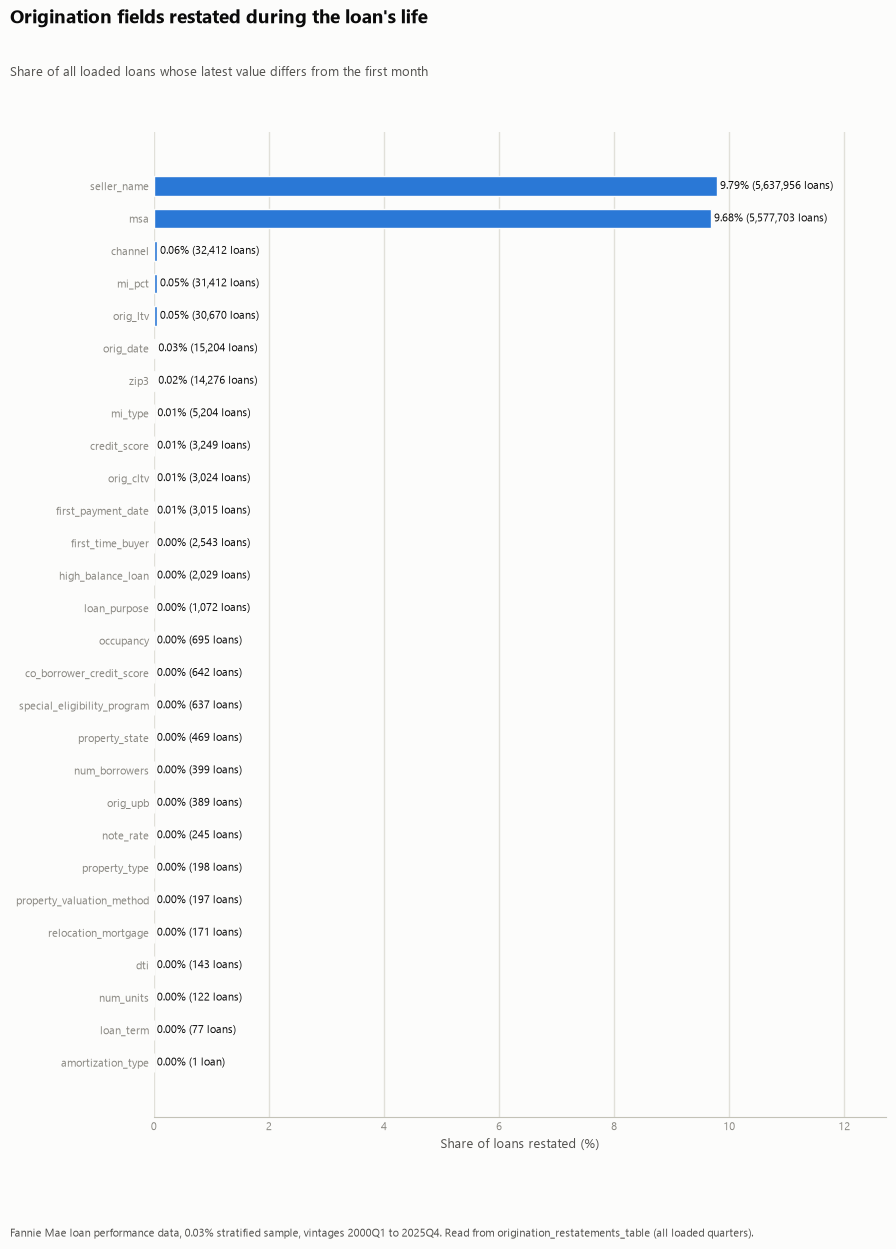

**Result.** The most restated field is `seller_name` (9.79% of loans, 5,637,956 loans); then `msa` 9.68%, `channel` 0.06%, `mi_pct` 0.05%.

In [15]:
# Restated origination fields, ranked (from origination_restatements_table).
rest = q("SELECT column_name AS field, sum(loans_restated) AS loans_restated FROM origination_restatements_table GROUP BY 1 ORDER BY 2 DESC")
rest["pct_of_loans"] = 100.0 * rest["loans_restated"] / LEDGER_LOANS
save_table(rest, "eda_02_restatements")
fig, ax = plt.subplots(figsize=(9, max(3.5, 0.38 * len(rest) + 2)))
y = np.arange(len(rest))
ax.barh(y, rest["pct_of_loans"], height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(rest["field"])
ax.invert_yaxis()
for yi, v, k in zip(y, rest["pct_of_loans"], rest["loans_restated"]):
    ax.text(v, yi, f" {v:.2f}% ({int(k):,} loan{'' if int(k) == 1 else 's'})", va="center", ha="left", fontsize=8)
ax.set_xlim(0, max(rest["pct_of_loans"].max() * 1.3, 0.5))
ax.set_xlabel("Share of loans restated (%)")
style_axes(ax, grid="x")
save_chart(fig, "eda_02a_restated_fields", "Origination fields restated during the loan's life",
           "Share of all loaded loans whose latest value differs from the first month", note="Read from origination_restatements_table (all loaded quarters).")
top = rest.iloc[0] if len(rest) else None
say("**Result.** " + (f"The most restated field is `{top['field']}` ({pct(top['pct_of_loans'], 2)} of loans, {n(top['loans_restated'])} loans); "
    f"then " + ", ".join(f"`{r['field']}` {pct(r['pct_of_loans'], 2)}" for _, r in rest.iloc[1:4].iterrows()) + "." if top is not None else "No restatements recorded."))

### 02.3 Missing values by vintage

**Why:** A field can be blank because it was not collected in some years, which changes who can be scored. A heatmap by vintage shows when fields appear or disappear.

**How:** Loan fields: count filled values per vintage in `loans_table`. Monthly fields: use the raw scan (scan 1) blanks per quarter. Shade by percent blank; monthly exit and loss fields are blank except at exit, by design.

**Answers:** Which fields are blank, and in which vintages?

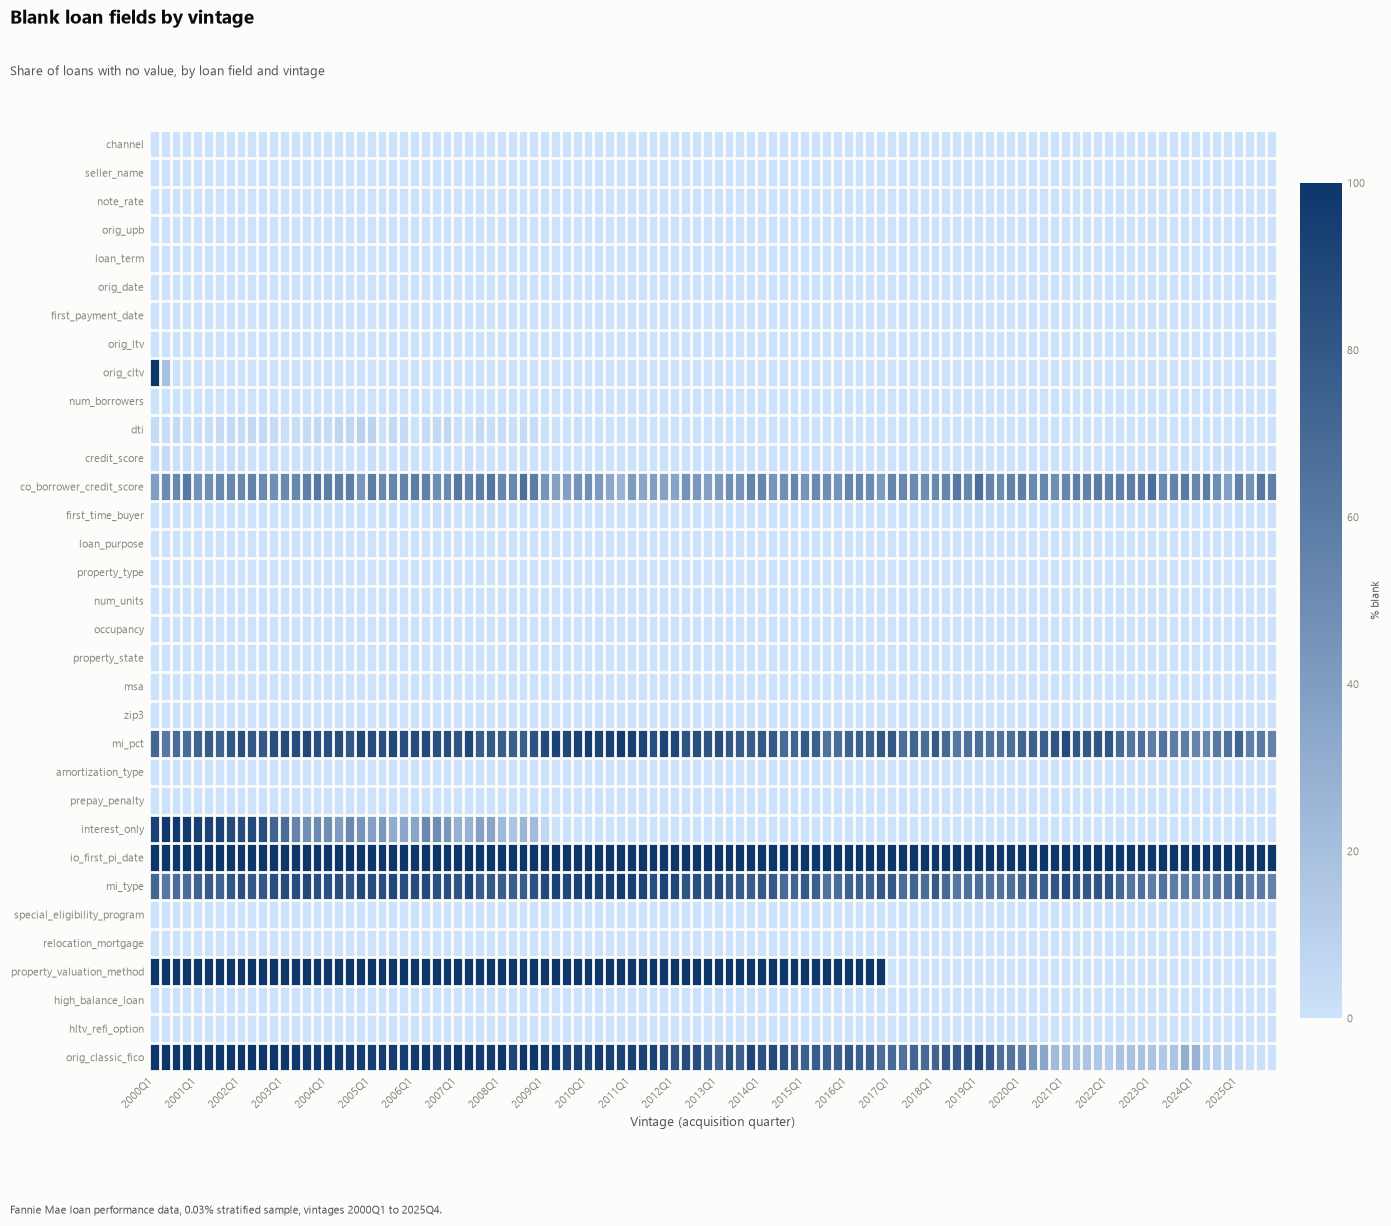

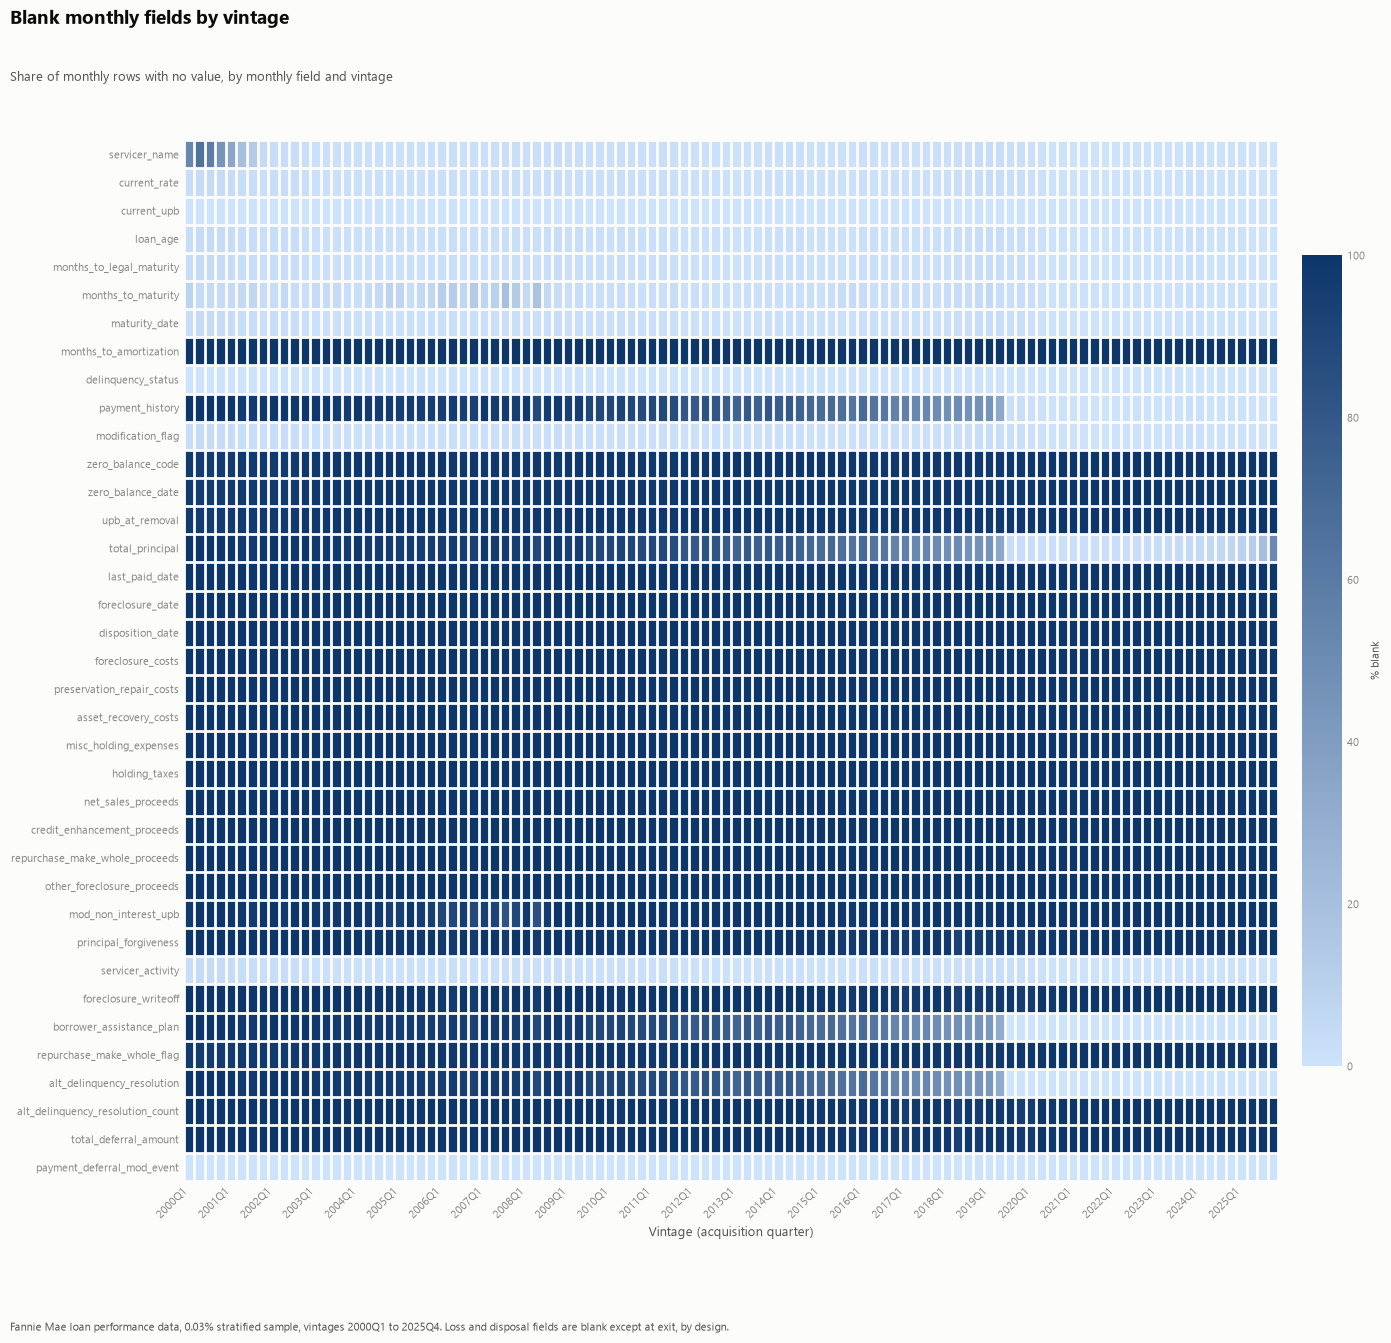

**Result.** 12 of 33 loan fields have some blanks; the most blank are `io_first_pi_date` 100.0%, `mi_pct` 79.2%, `mi_type` 79.2%. 1 loan fields and 22 monthly fields are more than 90% blank over all vintages.

In [16]:
# Percent blank by field and vintage: loan fields from loans_table, monthly fields from the raw scan.
lp = [f"{filled(c)} AS n_{c}" for c in LOAN_COLS]
lv = q(f"SELECT acquisition_quarter, count(*) AS n_all, {', '.join(lp)} FROM {LOANS} GROUP BY 1 ORDER BY 1")
rows = []
for _, r in lv.iterrows():
    for c in LOAN_COLS:
        rows.append(("loans", c, r["acquisition_quarter"], 100.0 * (1 - r[f"n_{c}"] / r["n_all"])))
for c in LOAN_COLS:
    rows.append(("loans", c, "all vintages", 100.0 * (1 - lv[f"n_{c}"].sum() / lv["n_all"].sum())))
idx = {c: i for i, c in enumerate(RAW_FIELDS)}
for _, r in scan1.iterrows():
    for c in MONTHLY_COLS:
        rows.append(("monthly", c, r["quarter"], 100.0 * r[f"b{idx[c]}"] / r["n_rows"]))
for c in MONTHLY_COLS:
    rows.append(("monthly", c, "all vintages", 100.0 * scan1[f"b{idx[c]}"].sum() / scan1["n_rows"].sum()))
missing = pd.DataFrame(rows, columns=["object", "field", "vintage", "pct_blank"])
save_table(missing.round(4), "eda_02_missing_by_vintage")
BLANK_LOANS = missing[(missing["object"] == "loans") & (missing["vintage"] == "all vintages")].set_index("field")["pct_blank"]
BLANK_MONTHLY = missing[(missing["object"] == "monthly") & (missing["vintage"] == "all vintages")].set_index("field")["pct_blank"]

for obj, cols, name, title, sub in (("loans", LOAN_COLS, "eda_02b_missing_loan_fields_by_vintage", "Blank loan fields by vintage", "Share of loans with no value, by loan field and vintage"),
                                    ("monthly", MONTHLY_COLS, "eda_02c_missing_monthly_fields_by_vintage", "Blank monthly fields by vintage",
                                     "Share of monthly rows with no value, by monthly field and vintage")):
    pivot = missing[(missing["object"] == obj) & (missing["vintage"] != "all vintages")].pivot(index="field", columns="vintage", values="pct_blank").loc[cols, VINTAGES]
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(VINTAGES) + 4) if len(VINTAGES) <= 12 else 14, 0.3 * len(cols) + 2.5))
    text = [[f"{v:.1f}" for v in row] for row in pivot.values] if len(VINTAGES) <= 12 else None
    draw_heatmap(ax, pivot.values, cols, VINTAGES, ONE_HUE, 0, 100, cell_text=text, col_ticks=quarter_ticks(VINTAGES), bar_label="% blank")
    ax.set_xlabel("Vintage (acquisition quarter)")
    save_chart(fig, name, title, sub, note="Loss and disposal fields are blank except at exit, by design." if obj == "monthly" else None)

over90_loans, over90_monthly = int((BLANK_LOANS > 90).sum()), int((BLANK_MONTHLY > 90).sum())
with_blanks = BLANK_LOANS[BLANK_LOANS > 0].sort_values(ascending=False)
say(f"**Result.** {len(with_blanks)} of {len(LOAN_COLS)} loan fields have some blanks; the most blank are "
    + ", ".join(f"`{f}` {pct(v)}" for f, v in with_blanks.head(3).items())
    + f". {over90_loans} loan fields and {over90_monthly} monthly fields are more than 90% blank over all vintages.")

### 02.4 Blank against filled

**Why:** If loans with a blank field go bad more often than loans with a value, the blank itself is information.

**How:** For each loan field that is at least 0.1% blank, compare the provisional bad rate when the field is blank with the rate when it is filled (bad / (bad + good), Wilson 95% interval). The gap is in percentage points with a Newcombe interval, plus the ratio. A blank group with fewer than `MIN_CELL` outcome loans is not shown on its own.

**Answers:** Is a blank value linked to a higher or lower provisional bad rate?

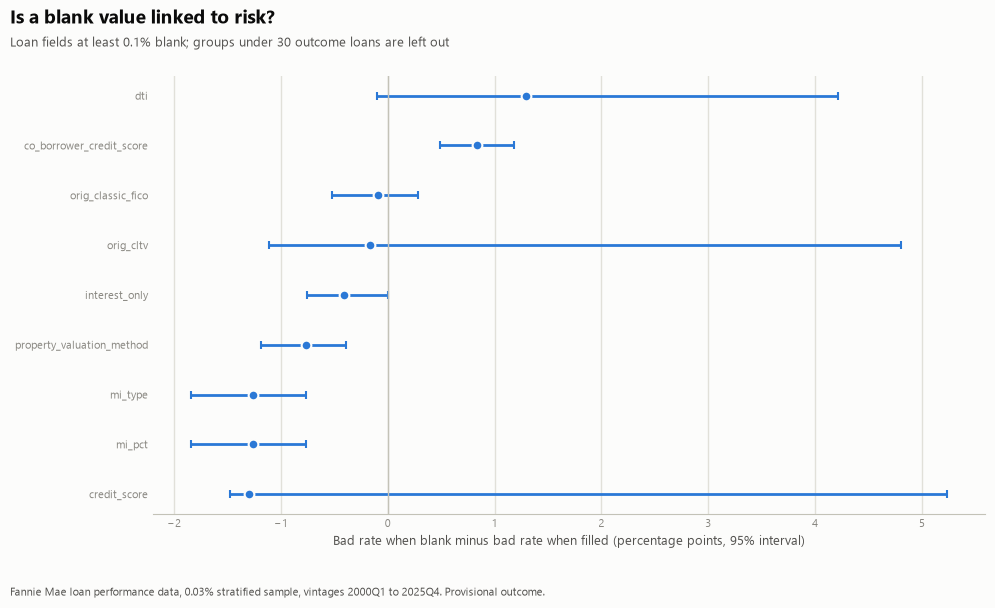

**Result.** 10 loan fields are at least 0.1% blank; 9 have enough blank loans to compare. For 4 of them the interval of the gap excludes zero: `mi_pct` (-1.26 points, ratio 0.45), `mi_type` (-1.26 points, ratio 0.45), `co_borrower_credit_score` (+0.83 points, ratio 1.96), `property_valuation_method` (-0.77 points, ratio 0.57).

In [17]:
# Provisional bad rate when a loan field is blank against when it is filled (fields at least 0.1% blank).
fields = [c for c in LOAN_COLS if BLANK_LOANS[c] >= 0.1]
blank_cond = lambda c: f"{c} IS NULL" if DTYPE.get(c) != "text" else f"({c} IS NULL OR trim({c}) = '')"
parts = [f"count(*) FILTER (WHERE {blank_cond(c)}) AS nb_{c}, count(*) FILTER (WHERE {blank_cond(c)} AND outcome = 'bad') AS bb_{c}" for c in fields]
r = q(f"SELECT count(*) AS n, count(*) FILTER (WHERE outcome = 'bad') AS bad, {', '.join(parts)} FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good')").iloc[0]
rows = []
for c in fields:
    nb, bb = int(r[f"nb_{c}"]), int(r[f"bb_{c}"])
    nf, bf = int(r["n"]) - nb, int(r["bad"]) - bb
    shown = nb >= MIN_CELL and nf >= MIN_CELL
    gap = diff_pp(bb, nb, bf, nf) if shown else (np.nan,) * 4
    rows.append({"field": c, "pct_blank": BLANK_LOANS[c], "outcome_loans_blank": nb, "bad_rate_blank_pct": 100 * wilson(bb, nb)[0] if nb else np.nan,
                 "outcome_loans_filled": nf, "bad_rate_filled_pct": 100 * wilson(bf, nf)[0] if nf else np.nan,
                 "gap_pp": gap[0], "gap_low_pp": gap[1], "gap_high_pp": gap[2], "ratio": gap[3],
                 "note": "" if shown else f"fewer than {MIN_CELL:,} loans"})
blank_vs_filled = pd.DataFrame(rows)
save_table(blank_vs_filled, "eda_02_blank_vs_filled")
plot = blank_vs_filled.dropna(subset=["gap_pp"]).sort_values("gap_pp").reset_index(drop=True)
if len(plot):
    fig, ax = plt.subplots(figsize=(10, max(3.5, 0.45 * len(plot) + 2)))
    y = np.arange(len(plot))
    ax.errorbar(plot["gap_pp"], y, xerr=[plot["gap_pp"] - plot["gap_low_pp"], plot["gap_high_pp"] - plot["gap_pp"]], fmt="o", color=BLUE,
                ecolor=BLUE, capsize=3, markersize=7, markeredgecolor=BG, markeredgewidth=1.5)
    ax.axvline(0, color=AXLINE, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(plot["field"])
    ax.set_xlabel("Bad rate when blank minus bad rate when filled (percentage points, 95% interval)")
    style_axes(ax, grid="x")
    save_chart(fig, "eda_02d_bad_rate_blank_vs_filled", "Is a blank value linked to risk?",
               f"Loan fields at least 0.1% blank; groups under {MIN_CELL:,} outcome loans are left out", provisional=True)
shown_n = len(plot)
strong = plot[plot["gap_low_pp"].gt(0) | plot["gap_high_pp"].lt(0)]
say(f"**Result.** {len(fields)} loan fields are at least 0.1% blank; {shown_n} have enough blank loans to compare. "
    + (f"For {len(strong)} of them the interval of the gap excludes zero: "
       + ", ".join(f"`{r['field']}` ({r['gap_pp']:+.2f} points, ratio {r['ratio']:.2f})" for _, r in strong.reindex(strong['gap_pp'].abs().sort_values(ascending=False).index).head(4).iterrows()) + "."
       if len(strong) else "None has a gap whose interval excludes zero."))

### 02.5 Field classes

**Why:** Whether a field may be used as a feature is decided once, in `03_leakage_audit.py`. The EDA reads that decision.

**How:** Read `field_leakage_table` and count fields by class: origination, one-month lag (monthly fields a model may use after a one-month lag), quarantined (outcome fields: never features) and key.

**Answers:** How many fields are in each class?

In [18]:
# Field classes, read from field_leakage_table (not worked out again).
leak = q("SELECT field_name, source_object, field_class, lag_rule, usable_as_feature FROM field_leakage_table")
classes = leak.groupby(["field_class", "source_object"]).agg(fields=("field_name", "count")).reset_index()
save_table(classes, "eda_02_field_classes")
QUARANTINED = set(leak.loc[leak["field_class"] == "quarantined", "field_name"])
ORIGINATION = set(leak.loc[(leak["field_class"] == "origination") & (leak["source_object"] == "loans_table"), "field_name"])
cnt = leak.groupby("field_class")["field_name"].count()
say("**Result.** `field_leakage_table` holds " + n(len(leak)) + " field entries: " + ", ".join(f"{k} {int(v)}" for k, v in cnt.items())
    + ". Quarantined fields (for example " + ", ".join(f"`{f}`" for f in sorted(QUARANTINED)[:4])
    + ") are outcome fields and never enter sections 05, 06 or 13.")

**Result.** `field_leakage_table` holds 78 field entries: key 5, monthly_lag_1 21, origination 33, quarantined 19. Quarantined fields (for example `asset_recovery_costs`, `credit_enhancement_proceeds`, `disposition_date`, `exit_reason`) are outcome fields and never enter sections 05, 06 or 13.

### 02.6 Lag on economic data

**Why:** Economic series are published after the month they describe. A model that used this month's unemployment rate would use a number nobody had yet.

**How:** Read `macro_sources_table` and show the publication delay of each series. The text states the lag any model must apply.

**Answers:** How late is each economic series, and what lag must a model respect?

In [19]:
# Publication delay of the economic series (from macro_sources_table).
if MACRO_OK:
    lag = q("SELECT series_name, publication_delay, first_observation, last_observation FROM macro_sources_table")
    save_table(lag.astype(str), "eda_02_economic_lag")
    say("**Result.** Publication delay of each series: " + "; ".join(f"{r['series_name']}: {r['publication_delay']}" for _, r in lag.iterrows())
        + ". A model must use economic values lagged by at least the stated delay: the unemployment rate by at least its delay above, and house prices by at least theirs. "
        "Section 06 describes the past and applies no lag. The US source is a departure from UK rules: see `docs\\departures_from_uk_rules.md` (D-025).")
else:
    say("**Result.** The macro tables are missing, so the economic lag is not shown.")

**Result.** Publication delay of each series: federal funds rate: monthly average, published early the next month; unemployment rate: about 1 month after the month; national house price index monthly: about 2 months after the month; state house price index quarterly: about 2 months after the quarter ends. A model must use economic values lagged by at least the stated delay: the unemployment rate by at least its delay above, and house prices by at least theirs. Section 06 describes the past and applies no lag. The US source is a departure from UK rules: see `docs\departures_from_uk_rules.md` (D-025).

In [20]:
say("## Section 02 - What this shows, and which later module uses it")
say(f"The keys are {'clean' if dup_loans == 0 and dup_months == 0 else 'NOT clean'}. {len(rest)} origination fields are restated; the loan table keeps the corrected value, "
    f"so any origination field with many restatements (most: `{rest['field'].iloc[0] if len(rest) else 'none'}`) must be treated with care in Module 3. "
    f"{len(strong)} loan fields have a blank that is linked to the bad rate; Module 3 (`03_rating_and_pd`) should treat those blanks as their own category. "
    "Which fields may be used at all stays with `03_leakage_audit.py`; the lag on economic data goes to every module that uses it (Modules 3, 5 and 7).")

## Section 02 - What this shows, and which later module uses it

The keys are clean. 28 origination fields are restated; the loan table keeps the corrected value, so any origination field with many restatements (most: `seller_name`) must be treated with care in Module 3. 4 loan fields have a blank that is linked to the bad rate; Module 3 (`03_rating_and_pd`) should treat those blanks as their own category. Which fields may be used at all stays with `03_leakage_audit.py`; the lag on economic data goes to every module that uses it (Modules 3, 5 and 7).

# Section 03 - Monthly history checks

**Answers:** Are loan histories complete and in order? (sample / full subset)

### 03.1 History of each loan

**Why:** A mortgage is a monthly history. If months are missing, rows follow the exit, or reporting stops without an exit, every curve built on those histories is wrong.

**How:** Copy the monthly rows of the active subset into a TEMP table, and build one row per loan: first and last month, rows, distinct months, months missing inside the history (months from first to last, plus one, less distinct months), first exit month, rows after the exit, whether reporting stopped before the end of the data without an exit, months between origination and the start of the acquisition quarter (seasoning), and the number of servicers.

**Answers:** Are loan histories complete and in order?

In [21]:
# TEMP tables for the subset: its monthly rows, and one history row per loan.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE subset_months AS
    SELECT loan_id, reporting_period AS rp, delinquency_months AS dm, is_dpd_unknown AS xx, zero_balance_code AS zb,
           modification_flag AS modflag, borrower_assistance_plan AS plan, alt_delinquency_resolution AS defer, current_upb AS upb, servicer_name,
           delinquency_months, modification_flag, zero_balance_code
    FROM {SUBSET_MONTHLY}""")
codes = ", ".join(f"'{c}'" for c in CREDIT_EXIT_CODES)
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE subset_history AS
    WITH e AS (SELECT loan_id, min(rp) FILTER (WHERE zb IS NOT NULL) AS first_exit FROM subset_months GROUP BY loan_id),
    h AS (
        SELECT m.loan_id, min(m.rp) AS first_month, max(m.rp) AS last_month, count(*) AS n_rows, count(DISTINCT m.rp) AS n_months,
               datediff('month', min(m.rp), max(m.rp)) + 1 - count(DISTINCT m.rp) AS months_missing,
               e.first_exit AS first_exit_month,
               count(*) FILTER (WHERE e.first_exit IS NOT NULL AND m.rp > e.first_exit) AS rows_after_exit,
               (max(m.rp) < DATE '{DATA_END}' AND e.first_exit IS NULL) AS stopped_early,
               count(DISTINCT m.servicer_name) AS servicers,
               min(m.rp) FILTER (WHERE {BAD_TRIGGER_SQL}) AS first_bad_month,
               min(m.rp) FILTER (WHERE m.zb = '01') AS prepaid_month
        FROM subset_months m JOIN e ON e.loan_id = m.loan_id GROUP BY m.loan_id, e.first_exit)
    SELECT l.loan_id, l.first_payment_date, {era_case('l.orig_date')} AS era, CAST(l.orig_upb AS DOUBLE) AS orig_upb,
           datediff('month', l.orig_date, {QSTART}) AS seasoning_months, h.*  EXCLUDE (loan_id)
    FROM {SUBSET_LOANS} l LEFT JOIN h ON h.loan_id = l.loan_id""")
H = q("""SELECT count(*) AS loans, count(*) FILTER (WHERE n_rows IS NULL) AS no_rows,
                count(*) FILTER (WHERE months_missing > 0) AS gaps, count(*) FILTER (WHERE rows_after_exit > 0) AS after_exit,
                count(*) FILTER (WHERE stopped_early) AS stopped_early, count(*) FILTER (WHERE seasoning_months > 0) AS seasoned,
                count(*) FILTER (WHERE seasoning_months > 12) AS seasoned_12, count(*) FILTER (WHERE seasoning_months > 24) AS seasoned_24,
                count(*) FILTER (WHERE servicers > 1) AS servicer_changes, count(*) FILTER (WHERE servicers >= 4) AS servicers_4plus,
                median(seasoning_months) AS median_seasoning, max(servicers) AS max_servicers
         FROM subset_history""").iloc[0]
SUBSET_N = int(H["loans"])
tests = [("loans with no monthly rows", "no_rows"), ("loans with months missing inside the history", "gaps"), ("loans with rows after the exit", "after_exit"),
         ("loans that stopped reporting before the end of the data, with no exit code", "stopped_early"),
         ("seasoned loans (origination before the acquisition quarter)", "seasoned"), ("seasoned by more than 12 months", "seasoned_12"),
         ("seasoned by more than 24 months", "seasoned_24"), ("loans with more than one servicer", "servicer_changes")]
history_checks = pd.DataFrame([{"test": t, "loans": int(H[k]), "pct_of_loans": 100.0 * H[k] / SUBSET_N} for t, k in tests])
save_table(history_checks, "eda_03_history_checks")
say(f"**Result {SUBSET_TAG} ({n(SUBSET_N)} loans).** " + "; ".join(f"{t}: {n(H[k])} ({pct(100 * H[k] / SUBSET_N, 2)})" for t, k in tests) + ".")

**Result (0.03% stratified sample) (17,275 loans).** loans with no monthly rows: 0 (0.00%); loans with months missing inside the history: 5 (0.03%); loans with rows after the exit: 0 (0.00%); loans that stopped reporting before the end of the data, with no exit code: 0 (0.00%); seasoned loans (origination before the acquisition quarter): 6,858 (39.70%); seasoned by more than 12 months: 18 (0.10%); seasoned by more than 24 months: 2 (0.01%); loans with more than one servicer: 5,967 (34.54%).

### 03.2 Seasoning and servicer changes

**Why:** Some loans join the data late: one acquisition quarter can hold loans originated years earlier. Vintage curves therefore start from the origination date and must allow for loans that were already seasoned. Servicer transfers change who reports the loan.

**How:** Draw the gap between origination date and the start of the acquisition quarter, in months (0 to 24 and more), and the number of servicers per loan.

**Answers:** How seasoned are loans when they enter the data, and how often does the servicer change?

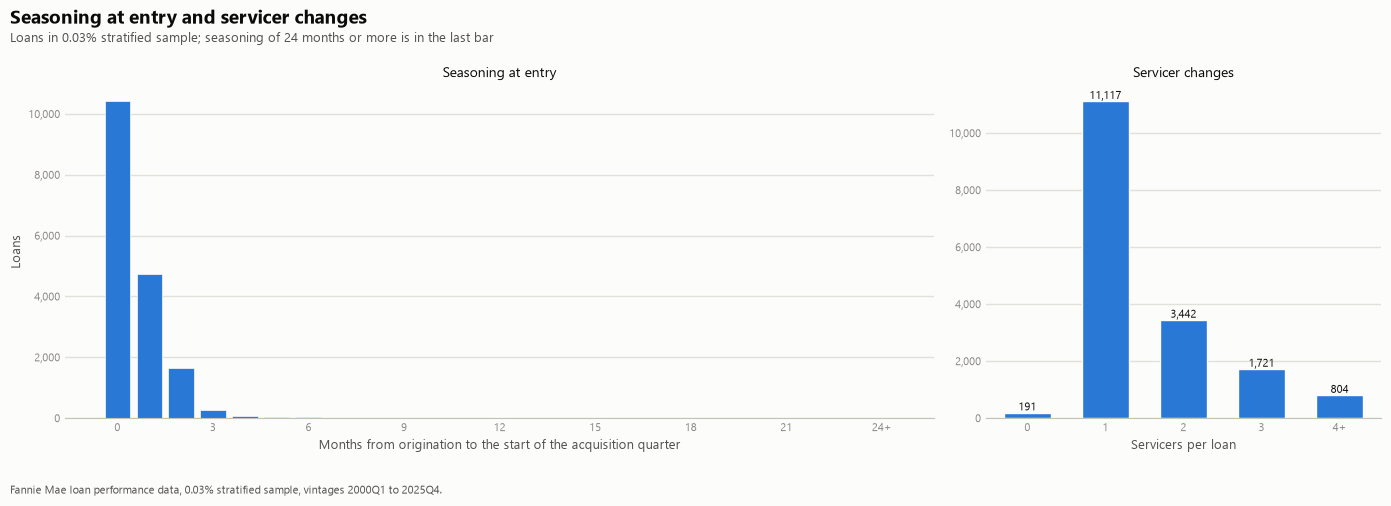

**Result (0.03% stratified sample).** The median loan entered the data 0 months after origination; 0.1% entered more than 12 months late and 0.0% more than 24 months late. 34.5% of loans changed servicer at least once (up to 9 servicers).

In [22]:
# Seasoning at entry (months) and servicers per loan.
seas = q("SELECT least(greatest(seasoning_months, 0), 24) AS m, count(*) AS loans FROM subset_history WHERE seasoning_months IS NOT NULL GROUP BY 1 ORDER BY 1")
serv = q("SELECT least(servicers, 4) AS s, count(*) AS loans FROM subset_history WHERE servicers IS NOT NULL GROUP BY 1 ORDER BY 1")
seas_all = pd.DataFrame({"m": range(25)}).merge(seas, on="m", how="left").fillna(0)
save_table(pd.concat([seas_all.assign(part="seasoning months (24 = 24 or more)").rename(columns={"m": "value"}),
                      serv.assign(part="servicers per loan (4 = 4 or more)").rename(columns={"s": "value"})])[["part", "value", "loans"]].astype({"loans": int}),
           "eda_03_seasoning_and_servicers")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2.2, 1]})
a1.bar(seas_all["m"], seas_all["loans"], width=0.8, color=BLUE, edgecolor=BG, linewidth=0.5)
a1.set_xticks(range(0, 25, 3))
a1.set_xticklabels([str(i) if i < 24 else "24+" for i in range(0, 25, 3)])
a1.set_xlabel("Months from origination to the start of the acquisition quarter")
a1.set_ylabel("Loans")
a1.set_title("Seasoning at entry", fontsize=10)
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
style_axes(a1, grid="y")
a2.bar(serv["s"], serv["loans"], width=0.6, color=BLUE, edgecolor=BG, linewidth=1)
a2.set_xticks(serv["s"])
a2.set_xticklabels([str(int(s)) if s < 4 else "4+" for s in serv["s"]])
for s_, v_ in zip(serv["s"], serv["loans"]):
    a2.text(s_, v_, f"{int(v_):,}", ha="center", va="bottom", fontsize=8)
a2.set_xlabel("Servicers per loan")
a2.set_title("Servicer changes", fontsize=10)
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
style_axes(a2, grid="y")
save_chart(fig, "eda_03a_seasoning_and_servicers", "Seasoning at entry and servicer changes", f"Loans in {SUBSET_TAG.strip('()')}; seasoning of 24 months or more is in the last bar", subset=True)
say(f"**Result {SUBSET_TAG}.** The median loan entered the data {H['median_seasoning']:.0f} months after origination; {pct(100 * H['seasoned_12'] / SUBSET_N)} entered more than 12 months late "
    f"and {pct(100 * H['seasoned_24'] / SUBSET_N)} more than 24 months late. {pct(100 * H['servicer_changes'] / SUBSET_N)} of loans changed servicer at least once (up to {int(H['max_servicers'])} servicers).")

In [23]:
say("## Section 03 - What this shows, and which later module uses it")
bad_hist = int(H["gaps"] + H["after_exit"])
say(f"Of {n(SUBSET_N)} subset loans, {n(H['gaps'])} have months missing inside their history and {n(H['after_exit'])} have rows after their exit; "
    f"{n(H['stopped_early'])} stopped reporting without an exit before the end of the data (these are cut short, not good, and are excluded from the outcome). "
    f"{pct(100 * H['seasoned_12'] / SUBSET_N)} of loans were more than 12 months old when they entered the data, so vintage curves must start from the origination date and allow for late entry. "
    "Module 2 (`04_vintage_curves.py` and `03_roll_rates.py`) reads these checks before it builds curves and transition matrices.")

## Section 03 - What this shows, and which later module uses it

Of 17,275 subset loans, 5 have months missing inside their history and 0 have rows after their exit; 0 stopped reporting without an exit before the end of the data (these are cut short, not good, and are excluded from the outcome). 0.1% of loans were more than 12 months old when they entered the data, so vintage curves must start from the origination date and allow for late entry. Module 2 (`04_vintage_curves.py` and `03_roll_rates.py`) reads these checks before it builds curves and transition matrices.

# Section 04 - One field at a time

**Answers:** How are the main fields spread, where are the spikes, what is the category mix, and which values are impossible?

### 04.1 Spread of the main numeric fields

**Why:** Percentiles, the mean and skew show where loans sit and how long the tails are, field by field.

**How:** For credit score, LTV, combined LTV, DTI, note rate, original balance and loan term, work out in SQL: percentiles 1, 5, 25, 50, 75, 95 and 99, the mean, the skewness, and the share of loans at or below the 1st and at or above the 99th percentile. Transformation choices are left to Module 3.

**Answers:** How spread out is each field, and how heavy are the tails?

In [24]:
# Percentiles, mean, skewness and tail shares for seven numeric fields (DuckDB aggregates).
rows = []
for f in SEVEN:
    x = f"CAST({f} AS DOUBLE)"
    s = q(f"""SELECT count({f}) AS filled, count(*) - count({f}) AS blank, quantile_cont({x}, 0.01) AS p1, quantile_cont({x}, 0.05) AS p5,
                     quantile_cont({x}, 0.25) AS p25, quantile_cont({x}, 0.5) AS p50, quantile_cont({x}, 0.75) AS p75,
                     quantile_cont({x}, 0.95) AS p95, quantile_cont({x}, 0.99) AS p99, avg({x}) AS mean, skewness({x}) AS skewness
              FROM {LOANS}""").iloc[0]
    t = q(f"SELECT count(*) FILTER (WHERE {x} <= {float(s['p1'])!r}) AS low, count(*) FILTER (WHERE {x} >= {float(s['p99'])!r}) AS high FROM {LOANS}").iloc[0]
    rows.append({"field": f, **s.to_dict(), "share_at_or_below_p1_pct": 100.0 * t["low"] / s["filled"], "share_at_or_above_p99_pct": 100.0 * t["high"] / s["filled"]})
numeric_summary = pd.DataFrame(rows)
numeric_summary[["filled", "blank"]] = numeric_summary[["filled", "blank"]].astype(int)
save_table(numeric_summary, "eda_04_numeric_summary")
ns = numeric_summary.set_index("field")
skewed = ns[ns["skewness"].abs() > 1].index.tolist()
say("**Result.** Medians: " + ", ".join(f"{LABEL[f].split(' (')[0]} {ns.loc[f, 'p50']:,.1f}" for f in SEVEN)
    + ". Fields with absolute skewness above 1 (a long tail): " + (", ".join(f"`{f}` ({ns.loc[f, 'skewness']:+.2f})" for f in skewed) if skewed else "none")
    + f". The share of loans at or above the 99th percentile is highest for `{ns['share_at_or_above_p99_pct'].idxmax()}` ({pct(ns['share_at_or_above_p99_pct'].max(), 2)}); "
    "a share well above 1% means many loans sit on the same top value.")

**Result.** Medians: Credit score 759.0, Original LTV 75.0, Original combined LTV 75.0, Debt-to-income 34.0, Note rate 4.8, Original UPB 189,000.0, Loan term 360.0. Fields with absolute skewness above 1 (a long tail): `orig_upb` (+1.33), `loan_term` (-1.18). The share of loans at or above the 99th percentile is highest for `loan_term` (72.25%); a share well above 1% means many loans sit on the same top value.

### 04.2 Histograms

**Why:** The shape of each field shows where loans cluster and whether there are several peaks.

**How:** Count loans per bin in SQL. Values outside the range go into the edge bins. Blank values are counted separately. Check C4 tests that bins plus blanks equal loans in scope.

**Answers:** What shape does each field have?

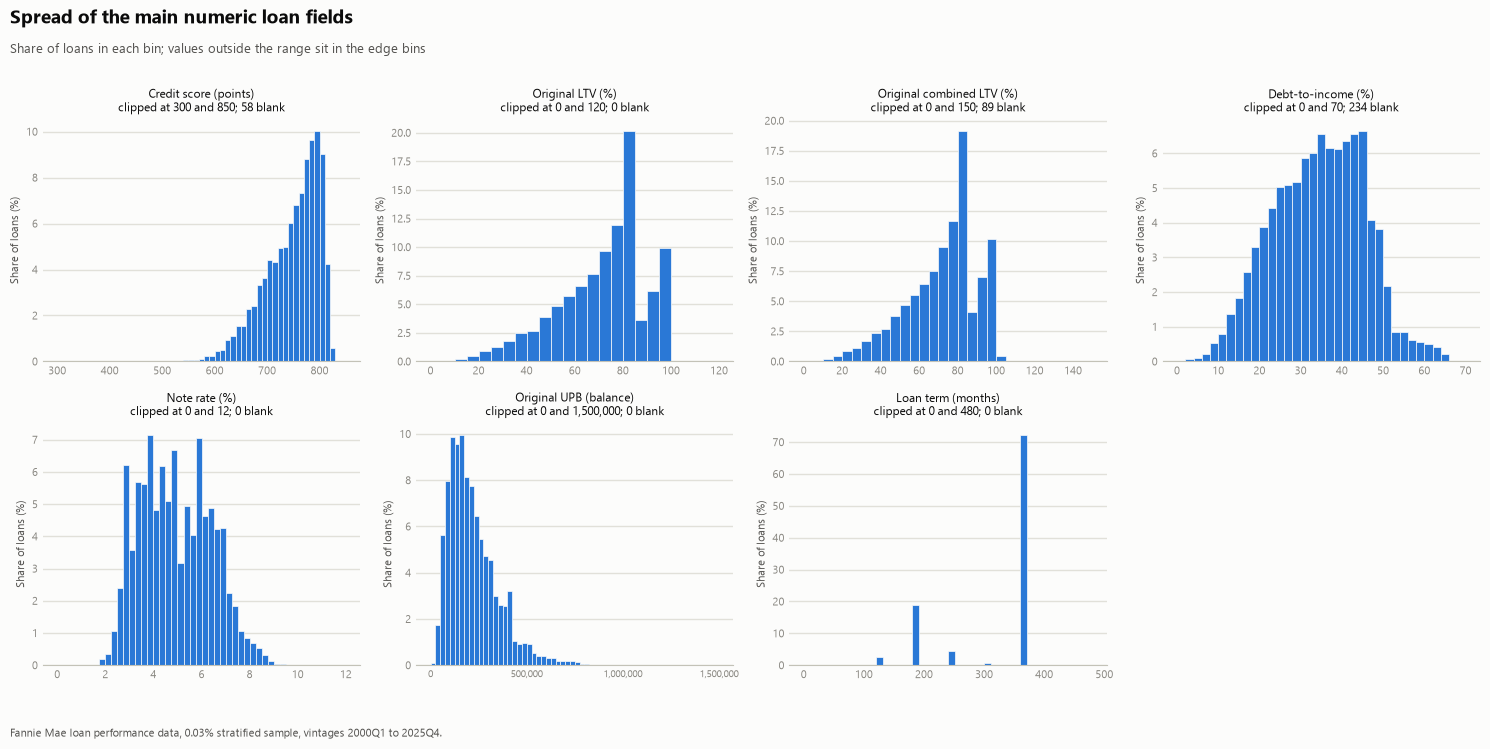

**Result.** 7 histograms drawn. Bin counts plus blanks equal the 17,275 loans in scope for 7 of 7 fields (check C4 passes).

In [25]:
# Histograms of seven numeric fields: share of loans per bin, clipped at the low and high limit.
hist_totals = {}
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, (f, (lo, hi, w)) in zip(axes.ravel(), HIST.items()):
    nb = int(round((hi - lo) / w))
    d = q(f"""SELECT CASE WHEN {f} IS NULL THEN NULL
                          ELSE CAST(least(greatest(floor((CAST({f} AS DOUBLE) - {lo}) / {w}), 0), {nb - 1}) AS INTEGER) END AS bin, count(*) AS n
              FROM {LOANS} GROUP BY 1""")
    blank = int(d.loc[d["bin"].isna(), "n"].sum())
    counts = np.zeros(nb)
    for b, c in zip(d["bin"], d["n"]):
        if not pd.isna(b):
            counts[int(b)] = c
    hist_totals[f] = int(counts.sum()) + blank
    ax.bar(lo + (np.arange(nb) + 0.5) * w, 100.0 * counts / LOANS_N, width=w, color=BLUE, edgecolor=BG, linewidth=0.5)
    ax.set_title(f"{LABEL[f]}\nclipped at {lo:,} and {hi:,}; {blank:,} blank", fontsize=8.5)
    ax.set_ylabel("Share of loans (%)", fontsize=8)
    ax.ticklabel_format(axis="x", style="plain")
    if f == "orig_upb":
        ax.set_xticks([0, 500000, 1000000, 1500000])
        ax.set_xticklabels(["0", "500,000", "1,000,000", "1,500,000"], fontsize=7)
    style_axes(ax, grid="y")
axes.ravel()[-1].axis("off")
save_chart(fig, "eda_04a_numeric_spread", "Spread of the main numeric loan fields", "Share of loans in each bin; values outside the range sit in the edge bins")
ok_hist = all(v == LOANS_N for v in hist_totals.values())
say(f"**Result.** {len(hist_totals)} histograms drawn. Bin counts plus blanks equal the {n(LOANS_N)} loans in scope for {sum(v == LOANS_N for v in hist_totals.values())} of {len(hist_totals)} fields"
    + (" (check C4 passes)." if ok_hist else " (check C4 fails)."))

### 04.3 Spikes at round values

**Why:** Borrowers and lenders aim for round numbers, such as an LTV of exactly 80, and these spikes can break a smooth scorecard curve. Naming them lets Module 3 treat them as their own band.

**How:** For the whole-number fields (credit score, LTV, combined LTV, DTI, loan term) count loans per value. A value is a spike if its share is at least 2 times the median share of the 4 nearest whole values (2 below and 2 above; a missing value counts as zero) and at least `MIN_CELL` loans hold it. The 5 largest spikes per field are kept, ranked by how far the share lies above its neighbours.

**Answers:** At which round values do loans pile up?

In [26]:
# Spikes: a value whose share is at least twice the median share of its four nearest whole values.
rows = []
for f in ["credit_score", "orig_ltv", "orig_cltv", "dti", "loan_term"]:
    d = q(f"SELECT {f} AS v, count(*) AS loans FROM {LOANS} WHERE {f} IS NOT NULL GROUP BY 1")
    tot = d["loans"].sum()
    share = dict(zip(d["v"].astype(int), d["loans"] / tot))
    cnt = dict(zip(d["v"].astype(int), d["loans"]))
    found = []
    for v, s in share.items():
        near = [share.get(v + k, 0.0) for k in (-2, -1, 1, 2)]
        med = float(np.median(near))
        if s >= 2 * med and cnt[v] >= MIN_CELL:
            found.append({"field": f, "value": v, "loans": int(cnt[v]), "share_pct": 100 * s, "median_share_of_4_neighbours_pct": 100 * med, "excess_pct": 100 * (s - med)})
    rows += sorted(found, key=lambda r: -r["excess_pct"])[:5]
spikes = pd.DataFrame(rows, columns=["field", "value", "loans", "share_pct", "median_share_of_4_neighbours_pct", "excess_pct"])
save_table(spikes, "eda_04_spikes")
say("**Result.** Largest spikes: " + "; ".join(
    f"`{f}` at " + ", ".join(f"{int(r['value'])} ({r['share_pct']:.1f}% of loans against {r['median_share_of_4_neighbours_pct']:.1f}% nearby)" for _, r in spikes[spikes['field'] == f].head(3).iterrows())
    for f in spikes["field"].unique()) + "." if len(spikes) else "**Result.** No spikes found.")

**Result.** Largest spikes: `credit_score` at 820 (0.3% of loans against 0.1% nearby); `orig_ltv` at 80 (18.8% of loans against 1.0% nearby), 95 (7.2% of loans against 0.4% nearby), 90 (4.9% of loans against 0.4% nearby); `orig_cltv` at 80 (17.7% of loans against 1.0% nearby), 95 (7.7% of loans against 0.4% nearby), 90 (5.6% of loans against 0.5% nearby); `dti` at 64 (0.2% of loans against 0.1% nearby); `loan_term` at 360 (72.3% of loans against 0.0% nearby), 180 (19.0% of loans against 0.0% nearby), 240 (4.6% of loans against 0.0% nearby).

### 04.4 Category mix

**Why:** The share of loans in each category shows what the book is made of.

**How:** Count loans per value in SQL for the category fields (channel, purpose, property type, occupancy, number of borrowers, first-time buyer, units, state). Show up to 6 bars and the rest as other; blank is its own bar.

**Answers:** What share of loans is in each category?

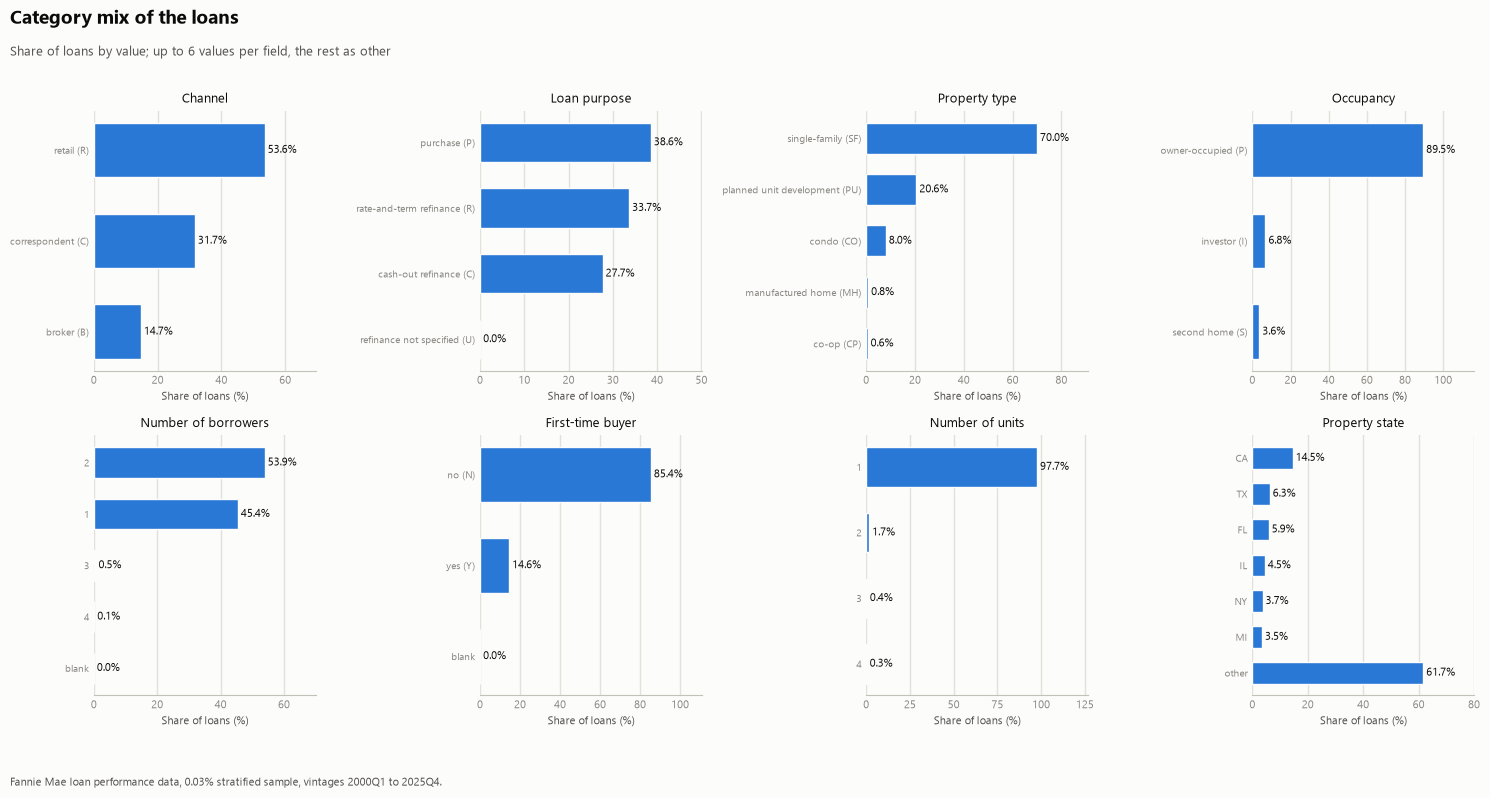

**Result.** Largest value in each field: channel retail 53.6%; loan purpose purchase 38.6%; property type single-family 70.0%; occupancy owner-occupied 89.5%; number of borrowers 2 53.9%; first-time buyer no 85.4%; number of units 1 97.7%; property state other 61.7%.

In [27]:
# Share of loans by category value, at most 6 bars plus other (other always last).
MIX_FIELDS = ["channel", "loan_purpose", "property_type", "occupancy", "num_borrowers", "first_time_buyer", "num_units", "property_state"]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
mix_rows = []
for ax, f in zip(axes.ravel(), MIX_FIELDS):
    d = q(f"SELECT coalesce(CAST({f} AS VARCHAR), 'blank') AS v, count(*) AS n FROM {LOANS} GROUP BY 1 ORDER BY n DESC")
    top = d.head(6).copy()
    if len(d) > 6:
        top = pd.concat([top, pd.DataFrame({"v": ["other"], "n": [d["n"].iloc[6:].sum()]})], ignore_index=True)
    names = [f"{CODE_LABELS[f][v]} ({v})" if v in CODE_LABELS.get(f, {}) else v for v in top["v"]]
    share = 100.0 * top["n"] / LOANS_N
    for v, c, s in zip(top["v"], top["n"], share):
        mix_rows.append({"field": f, "value": v, "loans": int(c), "share_pct": s})
    y = np.arange(len(top))
    ax.barh(y, share, height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(names, fontsize=7.5)
    ax.invert_yaxis()
    for yi, s in zip(y, share):
        ax.text(s, yi, f" {s:.1f}%", va="center", ha="left", fontsize=8, color=INK)
    ax.set_xlim(0, max(share) * 1.3)
    ax.set_title(LABEL[f], fontsize=9)
    ax.set_xlabel("Share of loans (%)", fontsize=8)
    style_axes(ax, grid="x")
save_chart(fig, "eda_04b_category_mix", "Category mix of the loans", "Share of loans by value; up to 6 values per field, the rest as other")
mix = pd.DataFrame(mix_rows)
save_table(mix, "eda_04_category_mix")
top1 = mix.sort_values("share_pct", ascending=False).groupby("field").head(1).set_index("field")
say("**Result.** Largest value in each field: " + "; ".join(f"{LABEL[f].split(' (')[0].lower()} {CODE_LABELS.get(f, {}).get(r['value'], r['value'])} {pct(r['share_pct'])}" for f, r in top1.loc[[m for m in MIX_FIELDS if m in top1.index]].iterrows()) + ".")

### 04.5 Impossible values

**Why:** Some values cannot be true, for example a credit score of 900. Counting them shows how clean the data is.

**How:** Apply 15 loan rules and 3 monthly rules. Loan rules run on the loan table; monthly rules come from the monthly scan (scan 2). Blanks are never counted. Values are reported, not failed, and nothing is removed.

**Answers:** How many loans and monthly rows break each rule?

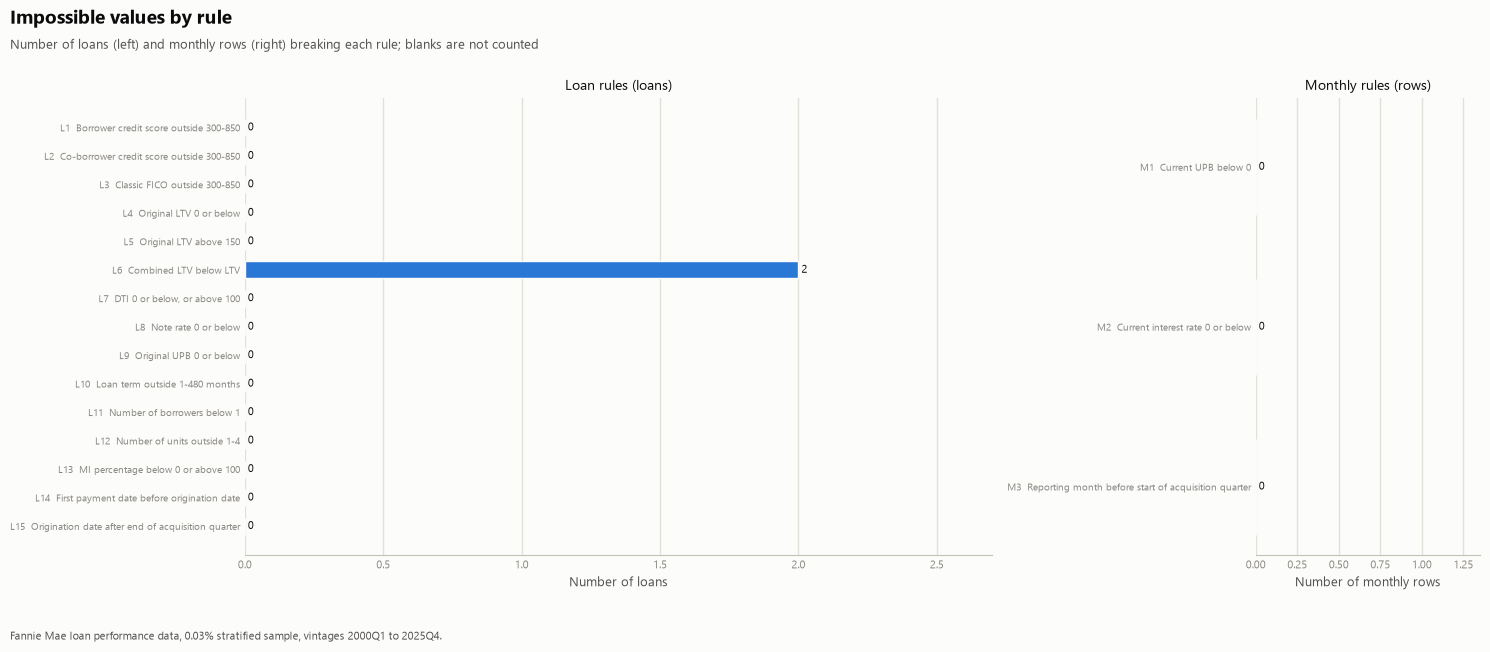

**Result.** 1 of 18 rules found values (reported, not failed): L6 Combined LTV below LTV (2).

In [28]:
# Count rows that break each impossible-value rule (reported only).
loan_parts = [f"count(*) FILTER (WHERE ({cond})) AS {rid}" for rid, obj, fld, txt, cond in RULES if obj == "loans"]
loan_counts = q(f"SELECT {', '.join(loan_parts)} FROM {LOANS}").iloc[0]
rows = []
for rid, obj, fld, txt, cond in RULES:
    k = int(loan_counts[rid]) if obj == "loans" else int(by_month[rid].sum())
    base = LOANS_N if obj == "loans" else MONTHLY_ROWS_BY_MONTH
    rows.append({"rule": rid, "object": obj, "field": fld, "description": txt, "rows_found": k, "pct_of_rows": 100.0 * k / base})
impossible = pd.DataFrame(rows)
save_table(impossible, "eda_04_impossible_values")
fig, (axl, axr) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [15, 4.5]})
for ax, obj, unit in ((axl, "loans", "loans"), (axr, "monthly", "monthly rows")):
    d = impossible[impossible["object"] == obj].reset_index(drop=True)
    y = np.arange(len(d))
    ax.barh(y, d["rows_found"], height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r}  {t}" for r, t in zip(d["rule"], d["description"])], fontsize=7.5)
    ax.invert_yaxis()
    for yi, k in zip(y, d["rows_found"]):
        ax.text(k, yi, f" {k:,}", va="center", ha="left", fontsize=8)
    ax.set_xlim(0, max(d["rows_found"].max(), 1) * 1.35)
    ax.set_xlabel(f"Number of {unit}")
    ax.set_title("Loan rules (loans)" if obj == "loans" else "Monthly rules (rows)", fontsize=10)
    style_axes(ax, grid="x")
save_chart(fig, "eda_04c_impossible_values", "Impossible values by rule", "Number of loans (left) and monthly rows (right) breaking each rule; blanks are not counted")
found = impossible[impossible["rows_found"] > 0]
headline["impossible_rules_found"] = len(found)
say(f"**Result.** {len(found)} of {len(RULES)} rules found values (reported, not failed)"
    + (": " + ", ".join(f"{r['rule']} {r['description']} ({n(r['rows_found'])})" for _, r in found.head(6).iterrows()) + "." if len(found) else "."))

In [29]:
say("## Section 04 - What this shows, and which later module uses it")
say(f"Medians run from {LABEL['credit_score'].split(' (')[0].lower()} {ns.loc['credit_score', 'p50']:,.0f} to a median balance of {ns.loc['orig_upb', 'p50']:,.0f}. "
    f"{len(skewed)} of 7 fields have a long tail (skewness beyond 1); Module 3 (`03_rating_and_pd`) chooses the transformation. "
    + (f"{len(spikes)} spikes were named (for example `{spikes['field'].iloc[0]}` at {int(spikes['value'].iloc[0])}); Module 3 should give round-value spikes their own band. " if len(spikes) else "")
    + f"{len(found)} impossible-value rules found values; `04_feature_catalogue.py` and Module 3 decide how to treat them.")

## Section 04 - What this shows, and which later module uses it

Medians run from credit score 759 to a median balance of 189,000. 2 of 7 fields have a long tail (skewness beyond 1); Module 3 (`03_rating_and_pd`) chooses the transformation. 17 spikes were named (for example `credit_score` at 820); Module 3 should give round-value spikes their own band. 1 impossible-value rules found values; `04_feature_catalogue.py` and Module 3 decide how to treat them.

# Section 05 - Two fields at a time

**Answers:** Which fields separate bad from good, which repeat each other, and which are redundant? Origination fields only; quarantined fields never enter.

### 05.1 Information value

**Why:** Information value (IV) is the standard credit measure of how well a field separates bad from good loans. Rules of thumb (industry practice, not regulation): below 0.02 weak, above 0.5 check for leakage.

**How:** Only fields that `field_leakage_table` classes as origination are used. Numeric fields: 10 bands from decile edges (equal edges merged), blank as its own band. Category fields: one band per value, blank as its own band. A band with no bad or no good loans gets 0.5 added to both counts. Weight of evidence = ln(good share / bad share); IV = sum of (good share - bad share) x weight of evidence. Only bad and good loans count.

**Answers:** Which origination fields separate bad from good, and how strongly?

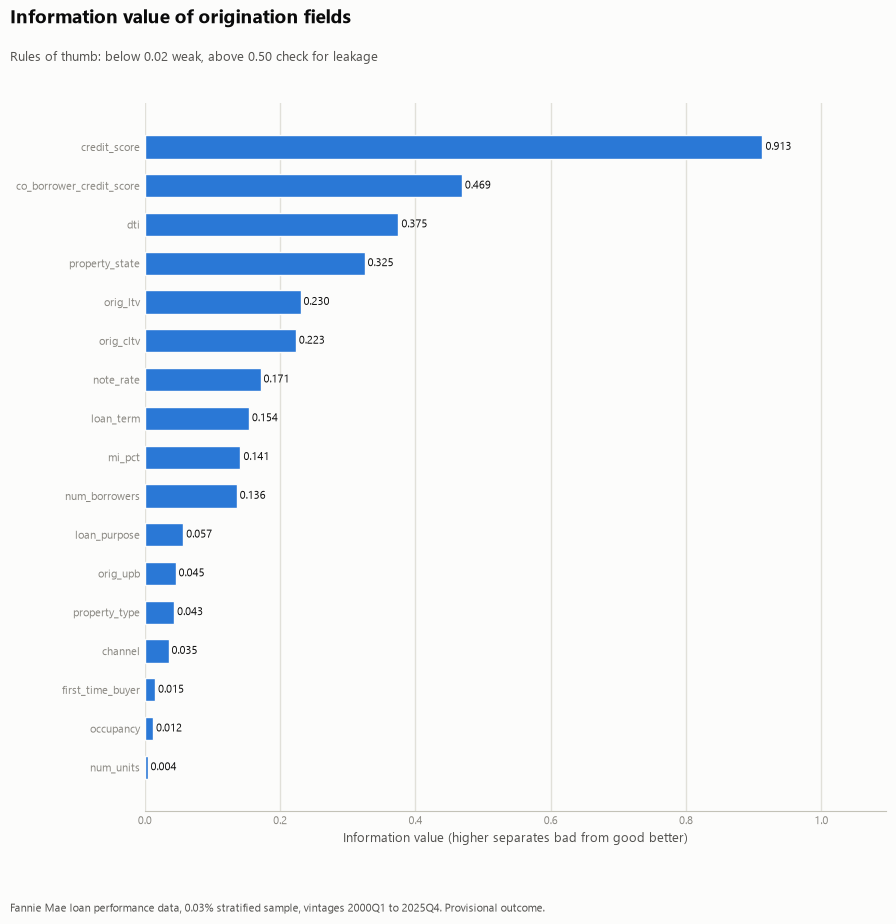

**Result.** Strongest fields: `credit_score` 0.913, `co_borrower_credit_score` 0.469, `dti` 0.375, `property_state` 0.325. Weak (below 0.02): `first_time_buyer`, `occupancy`, `num_units`. Above 0.5 (check for leakage): `credit_score`.

In [30]:
# Information value of each origination field against the provisional outcome.
NUM5 = [f for f in NUM_FIELDS if f in ORIGINATION]
CAT5 = [f for f in CAT_FIELDS if f in ORIGINATION]
FIELDS_USED["05"] |= set(NUM5 + CAT5)
edge_sql = ", ".join(f"quantile_cont(CAST({f} AS DOUBLE), {DECILES}) AS {f}" for f in NUM5)
er = q(f"SELECT {edge_sql} FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good')").iloc[0]
EDGES = {f: clean_edges(er[f]) for f in NUM5}
band_rows, iv_rows = [], []
for f in NUM5 + CAT5:
    if f in NUM5:
        d = q(f"SELECT {band_case(f, EDGES[f])} AS band_no, {OUT_AGG} FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good') GROUP BY 1 ORDER BY 1")
        d["band"] = d["band_no"].map(band_labels(EDGES[f]))
    else:
        d = q(f"SELECT coalesce(CAST({f} AS VARCHAR), 'blank') AS band, {OUT_AGG} FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good') GROUP BY 1 ORDER BY 1")
        d["band_no"] = range(len(d))
    part, woe = iv_parts(d["bad"], d["good"])
    d = rate_by_count_and_balance(d)
    d["field"], d["woe"], d["iv_part"] = f, woe, part
    band_rows.append(d[["field", "band_no", "band", "outcome_loans", "bad", "good", "bad_rate_count_pct", "ci_low_pct", "ci_high_pct", "bad_rate_balance_pct", "woe", "iv_part"]])
    iv_rows.append({"field": f, "information_value": float(part.sum()), "bands": len(d)})
bands = pd.concat(band_rows, ignore_index=True)
iv_df = pd.DataFrame(iv_rows).sort_values("information_value", ascending=False).reset_index(drop=True)
iv_df["rule_of_thumb"] = np.where(iv_df["information_value"] > 0.5, "above 0.5: check for leakage", np.where(iv_df["information_value"] < 0.02, "below 0.02: weak", ""))
IV = iv_df.set_index("field")["information_value"].to_dict()
save_table(bands, "eda_05_woe_bands")
save_table(iv_df, "eda_05_information_value")

plot = iv_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.4 * len(plot) + 2.5))
y = np.arange(len(plot))
ax.barh(y, plot["information_value"], height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(plot["field"])
for yi, v in zip(y, plot["information_value"]):
    ax.text(v, yi, f" {v:.3f}", va="center", ha="left", fontsize=8)
ax.set_xlim(0, max(plot["information_value"].max() * 1.2, 0.05))
ax.set_xlabel("Information value (higher separates bad from good better)")
style_axes(ax, grid="x")
save_chart(fig, "eda_05a_information_value", "Information value of origination fields", "Rules of thumb: below 0.02 weak, above 0.50 check for leakage", provisional=True)
over_half = iv_df[iv_df["information_value"] > 0.5]["field"].tolist()
weak = iv_df[iv_df["information_value"] < 0.02]["field"].tolist()
say("**Result.** Strongest fields: " + ", ".join(f"`{r['field']}` {r['information_value']:.3f}" for _, r in iv_df.head(4).iterrows())
    + ". Weak (below 0.02): " + (", ".join(f"`{f}`" for f in weak) if weak else "none")
    + ". Above 0.5 (check for leakage): " + (", ".join(f"`{f}`" for f in over_half) if over_half else "none") + ".")

### 05.2 Bad rate by band

**Why:** The bad rate in each band is the weight-of-evidence curve in plain terms. It shows whether a field ranks risk in a steady order.

**How:** Show the top 8 fields by information value. Each bar is the bad rate by count with its 95% interval (Wilson); the dark marker is the rate weighted by original balance. A field with more than 12 bands shows its 12 largest. Bands with fewer than `MIN_CELL` outcome loans are not shown.

**Answers:** Does the bad rate rise or fall in steps across the bands of the strongest fields?

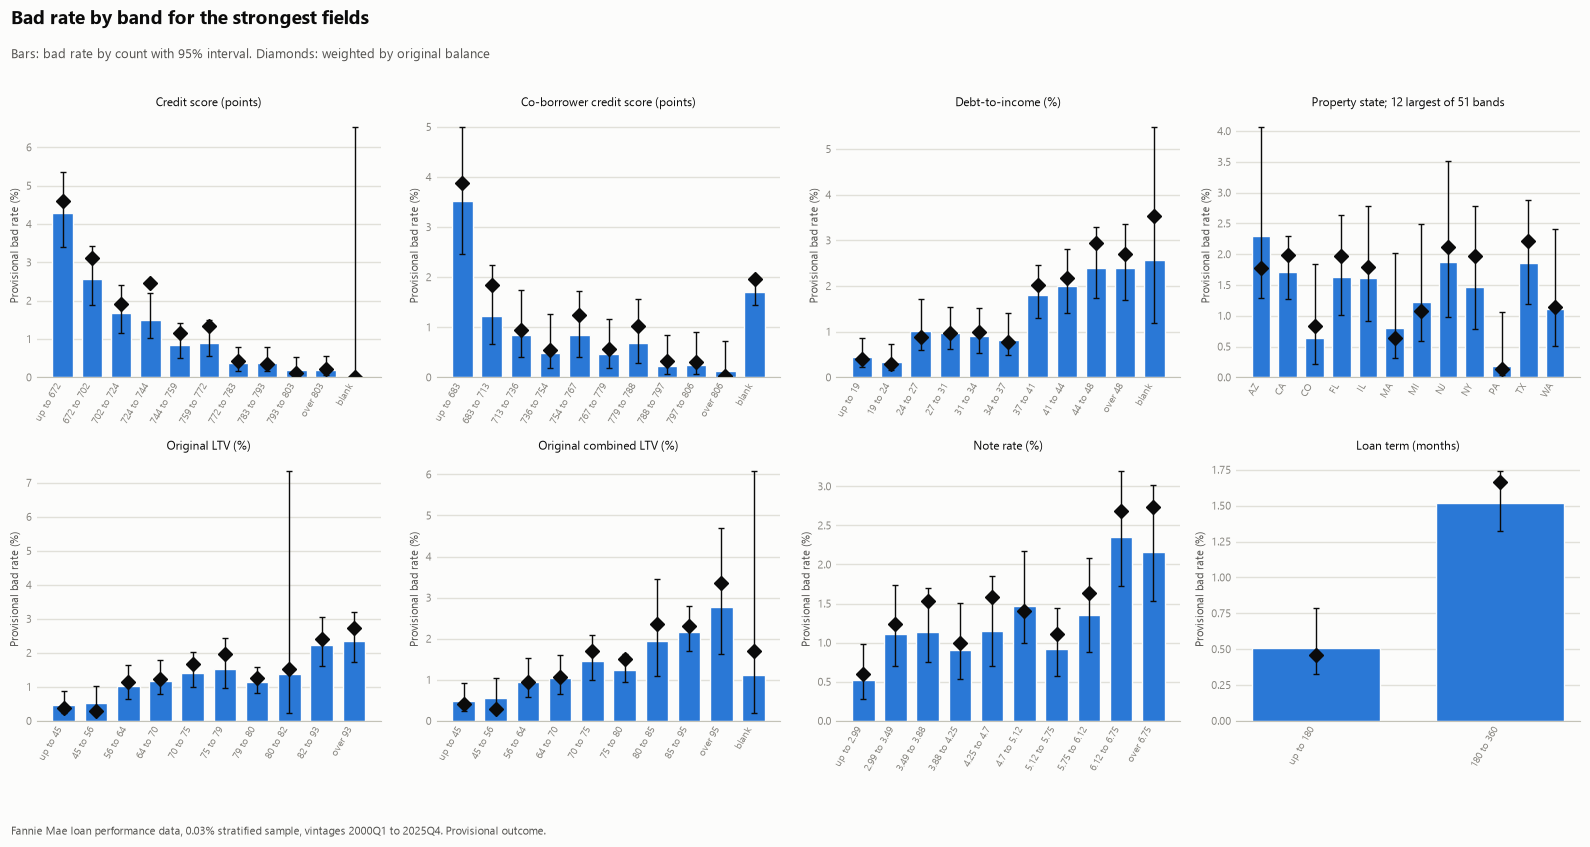

**Result.** Across the bands of the top fields the bad rate is: `credit_score` not steady; `co_borrower_credit_score` not steady; `dti` not steady; `property_state` a category field, no natural order; `orig_ltv` not steady; `orig_cltv` not steady; `note_rate` not steady; `loan_term` rising or falling in one direction.

In [31]:
# Provisional bad rate per band for the 8 fields with the highest information value.
top8 = iv_df["field"].head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
steady = {}
for ax, f in zip(axes.ravel(), top8):
    d = bands[(bands["field"] == f) & (bands["outcome_loans"] >= MIN_CELL)].copy()
    note = ""
    if len(d) > 12:
        note = f"; 12 largest of {len(d)} bands"
        d = d.nlargest(12, "outcome_loans")
    d = d.sort_values("band_no") if f in NUM5 else d.sort_values("band")
    x = np.arange(len(d))
    ax.bar(x, d["bad_rate_count_pct"], width=0.7, color=BLUE, edgecolor=BG, linewidth=1)
    ax.errorbar(x, d["bad_rate_count_pct"], yerr=[d["bad_rate_count_pct"] - d["ci_low_pct"], d["ci_high_pct"] - d["bad_rate_count_pct"]], fmt="none", ecolor=INK, capsize=2, linewidth=1)
    ax.plot(x, d["bad_rate_balance_pct"], linestyle="none", marker="D", markersize=7, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(d["band"], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{LABEL[f]}{note}", fontsize=8.5)
    ax.set_ylabel("Provisional bad rate (%)", fontsize=8)
    style_axes(ax, grid="y")
    vals = d[d["band"] != "blank"]["bad_rate_count_pct"].to_numpy()
    steps = np.diff(vals)
    steady[f] = bool(len(steps) > 0 and (np.all(steps >= 0) or np.all(steps <= 0)))
for ax in axes.ravel()[len(top8):]:
    ax.axis("off")
save_chart(fig, "eda_05b_bad_rate_by_band", "Bad rate by band for the strongest fields", "Bars: bad rate by count with 95% interval. Diamonds: weighted by original balance", provisional=True)
say("**Result.** Across the bands of the top fields the bad rate is: " + "; ".join(f"`{f}` " + ("a category field, no natural order" if f in CAT5 else ("rising or falling in one direction" if s else "not steady")) for f, s in steady.items()) + ".")

### 05.3 Correlation between numeric fields

**Why:** Two fields that move together carry the same information and cause trouble in a scorecard.

**How:** Pearson: `corr(a, b)` in SQL on all loans in scope, blanks skipped pair by pair. Spearman: `corr` of `rank()` for each field, also in SQL. Pairs with an absolute correlation above 0.7 (a rule of thumb) are outlined and named.

**Answers:** Which numeric fields are strongly related?

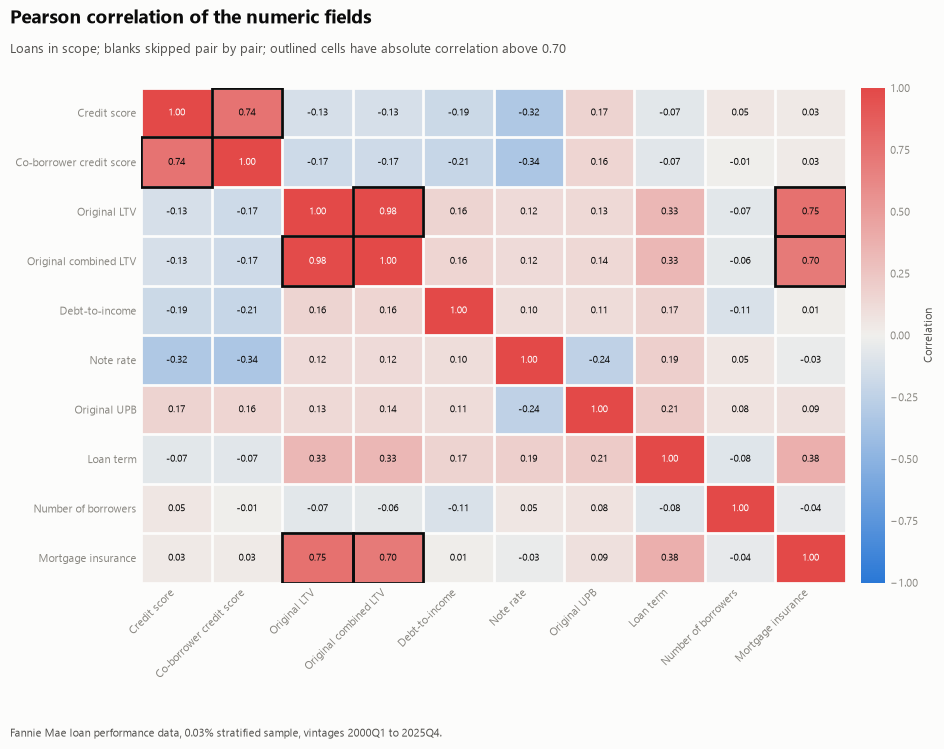

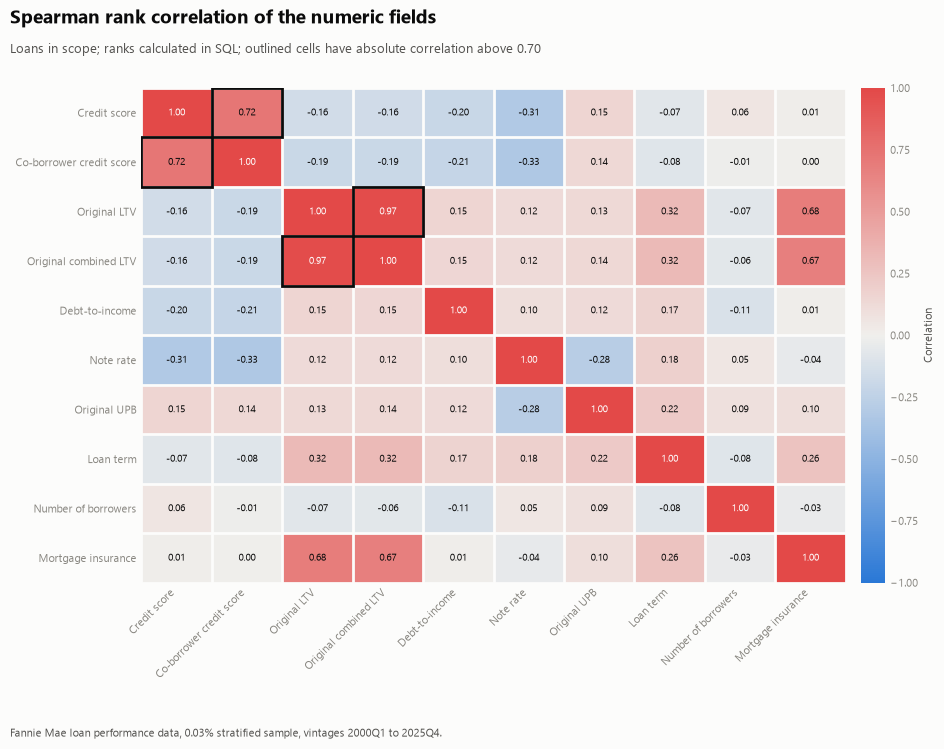

**Result.** 4 pairs have an absolute correlation above 0.7 (Pearson or Spearman): `credit_score` and `co_borrower_credit_score` (Pearson 0.74, Spearman 0.72), `orig_ltv` and `orig_cltv` (Pearson 0.98, Spearman 0.97), `orig_ltv` and `mi_pct` (Pearson 0.75, Spearman 0.68), `orig_cltv` and `mi_pct` (Pearson 0.70, Spearman 0.67).

In [32]:
# Pearson and Spearman correlation matrices for the numeric origination fields, calculated inside DuckDB.
k = len(NUM5)
pairs = [(i, j) for i in range(k) for j in range(i + 1, k)]
pr = q("SELECT " + ", ".join(f"corr(CAST({NUM5[i]} AS DOUBLE), CAST({NUM5[j]} AS DOUBLE)) AS c_{i}_{j}" for i, j in pairs) + f" FROM {LOANS}").iloc[0]
ranks = ", ".join(f"CASE WHEN {f} IS NULL THEN NULL ELSE rank() OVER (ORDER BY {f} NULLS LAST) END AS r_{i}" for i, f in enumerate(NUM5))
sr = q(f"WITH ranked AS (SELECT {ranks} FROM {LOANS}) SELECT " + ", ".join(f"corr(r_{i}, r_{j}) AS c_{i}_{j}" for i, j in pairs) + " FROM ranked").iloc[0]


def to_matrix(series):
    m = np.eye(k)
    for i, j in pairs:
        m[i, j] = m[j, i] = series[f"c_{i}_{j}"]
    return m


PEARSON, SPEARMAN = to_matrix(pr), to_matrix(sr)
corr_labels = [LABEL[f].split(" (")[0] for f in NUM5]


def draw_corr(matrix, name, title, subtitle):
    fig, ax = plt.subplots(figsize=(9.5, 7.5))
    text = [[("" if np.isnan(v) else f"{v:.2f}") for v in row] for row in matrix]
    flagged = [(i, j) for i in range(k) for j in range(k) if i != j and abs(matrix[i, j]) > 0.70]
    draw_heatmap(ax, matrix, corr_labels, corr_labels, CORR_CMAP, -1, 1, cell_text=text, outline=flagged, bar_label="Correlation")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    save_chart(fig, name, title, subtitle)


draw_corr(PEARSON, "eda_05c_correlation_pearson", "Pearson correlation of the numeric fields", "Loans in scope; blanks skipped pair by pair; outlined cells have absolute correlation above 0.70")
draw_corr(SPEARMAN, "eda_05d_correlation_spearman", "Spearman rank correlation of the numeric fields", "Loans in scope; ranks calculated in SQL; outlined cells have absolute correlation above 0.70")
rows = []
for method, m in (("pearson", PEARSON), ("spearman", SPEARMAN)):
    for i, j in pairs:
        rows.append({"method": method, "field_a": NUM5[i], "field_b": NUM5[j], "r": m[i, j], "above_0_70": bool(abs(m[i, j]) > 0.70)})
correlations = pd.DataFrame(rows)
save_table(correlations, "eda_05_correlations")
high = correlations[correlations["above_0_70"]]
HIGH_PAIRS = high[["field_a", "field_b"]].drop_duplicates()
say(f"**Result.** {len(HIGH_PAIRS)} pairs have an absolute correlation above 0.7 (Pearson or Spearman): "
    + (", ".join(f"`{r['field_a']}` and `{r['field_b']}` (Pearson {PEARSON[NUM5.index(r['field_a']), NUM5.index(r['field_b'])]:.2f}, Spearman {SPEARMAN[NUM5.index(r['field_a']), NUM5.index(r['field_b'])]:.2f})" for _, r in HIGH_PAIRS.iterrows()) if len(HIGH_PAIRS) else "none") + ".")

### 05.4 Association between category fields

**Why:** Category fields can duplicate each other too. Cramer's V measures the link from 0 (none) to 1 (identical).

**How:** For each pair of category fields count loans per combination in SQL, then work out Cramer's V from the counts. Blanks are left out of the pair.

**Answers:** Which category fields are strongly associated?

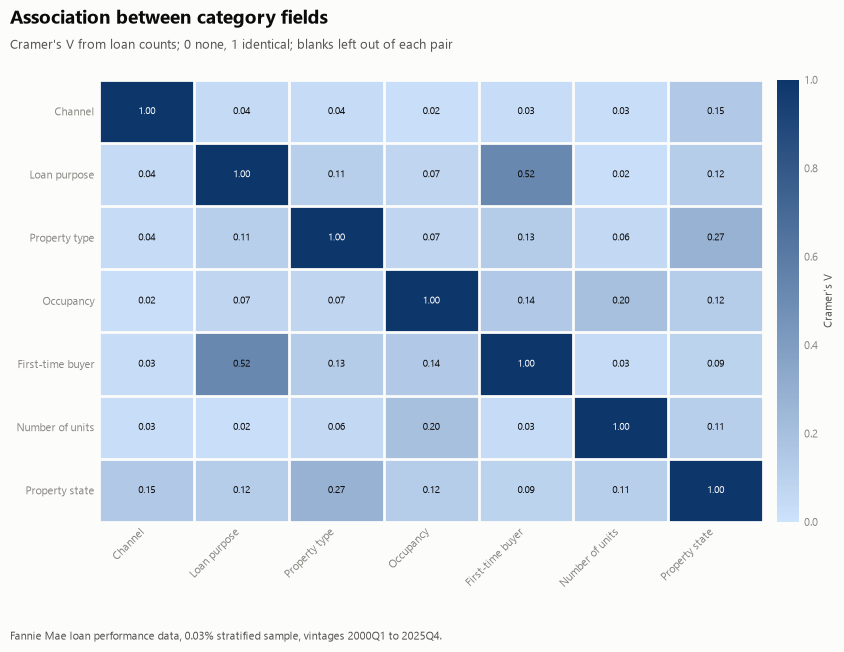

**Result.** Strongest category pairs: `loan_purpose` and `first_time_buyer` (0.52), `property_type` and `property_state` (0.27), `occupancy` and `num_units` (0.20).

In [33]:
# Cramer's V between category fields, from counts calculated in SQL.
def cramers_v(table):
    total = table.sum()
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / total
    mask = expected > 0
    chi2 = (((table - expected) ** 2)[mask] / expected[mask]).sum()
    kk = min(table.shape) - 1
    return float(np.sqrt(chi2 / (total * kk))) if kk > 0 and total > 0 else np.nan


m_ = len(CAT5)
cv = np.eye(m_)
rows = []
for i in range(m_):
    for j in range(i + 1, m_):
        a, b = CAT5[i], CAT5[j]
        d = q(f"SELECT CAST({a} AS VARCHAR) AS a, CAST({b} AS VARCHAR) AS b, count(*) AS n FROM {LOANS} WHERE {a} IS NOT NULL AND {b} IS NOT NULL GROUP BY 1, 2")
        table = d.pivot_table(index="a", columns="b", values="n", aggfunc="sum", fill_value=0).values.astype(float)
        cv[i, j] = cv[j, i] = cramers_v(table)
        rows.append({"field_a": a, "field_b": b, "cramers_v": cv[i, j]})
cramers = pd.DataFrame(rows)
save_table(cramers, "eda_05_cramers_v")
fig, ax = plt.subplots(figsize=(8.5, 6.5))
names = [LABEL[f] for f in CAT5]
draw_heatmap(ax, cv, names, names, ONE_HUE, 0, 1, cell_text=[[f"{v:.2f}" for v in row] for row in cv], bar_label="Cramer's V")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save_chart(fig, "eda_05e_category_association", "Association between category fields", "Cramer's V from loan counts; 0 none, 1 identical; blanks left out of each pair")
topc = cramers.sort_values("cramers_v", ascending=False).head(3)
say("**Result.** Strongest category pairs: " + ", ".join(f"`{r['field_a']}` and `{r['field_b']}` ({r['cramers_v']:.2f})" for _, r in topc.iterrows()) + ".")

### 05.5 Variance inflation factor

**Why:** VIF says how well each field is explained by all the others. Above 10 is a common rule of thumb for redundancy (industry practice, not regulation).

**How:** Take the numeric fields that are at least 95% filled in `feature_catalogue_table`, invert their Pearson correlation matrix with numpy and read the diagonal.

**Answers:** Which fields are redundant given all the others?

In [34]:
# VIF = diagonal of the inverse Pearson matrix, for fields at least 95% filled (fill rate read from the catalogue).
fill = catalogue[catalogue["source_object"] == "loans_table"].set_index("field_name")["fill_rate"]
keep = [i for i, f in enumerate(NUM5) if fill.get(f, 0) >= 0.95 and not np.isnan(PEARSON[i]).any()]
sub = PEARSON[np.ix_(keep, keep)]
try:
    inv = np.linalg.inv(sub)
except np.linalg.LinAlgError:
    inv = np.linalg.pinv(sub)
vif = pd.DataFrame({"field": [NUM5[i] for i in keep], "vif": np.diag(inv)})
vif["above_10"] = vif["vif"] > 10
VIF = vif.set_index("field")["vif"].to_dict()
save_table(vif, "eda_05_vif")
say(f"**Result.** VIF was worked out for {len(vif)} fields (the others are under 95% filled). Above 10: "
    + (", ".join(f"`{r['field']}` ({r['vif']:.1f})" for _, r in vif[vif['above_10']].iterrows()) if vif["above_10"].any() else "none")
    + ". Highest: " + ", ".join(f"`{r['field']}` {r['vif']:.1f}" for _, r in vif.sort_values("vif", ascending=False).head(3).iterrows()) + ".")

**Result.** VIF was worked out for 8 fields (the others are under 95% filled). Above 10: `orig_ltv` (28.1), `orig_cltv` (28.1). Highest: `orig_cltv` 28.1, `orig_ltv` 28.1, `note_rate` 1.3.

In [35]:
say("## Section 05 - What this shows, and which later module uses it")
say(f"The origination fields that separate bad from good best are {', '.join('`' + f + '`' for f in iv_df['field'].head(3))}. "
    + (f"{', '.join('`' + f + '`' for f in over_half)} is above 0.5 and must be checked for leakage in `03_leakage_audit.py`. " if over_half else "No field is above 0.5, so no origination field looks like leakage. ")
    + f"{len(HIGH_PAIRS)} numeric pairs repeat each other (above 0.7) and {int(vif['above_10'].sum())} fields have VIF above 10: Module 3 (`03_rating_and_pd`) should keep one of each repeating pair. "
    "All of this uses the provisional outcome and only origination fields, so it guides the feature choice and does not make it.")

## Section 05 - What this shows, and which later module uses it

The origination fields that separate bad from good best are `credit_score`, `co_borrower_credit_score`, `dti`. `credit_score` is above 0.5 and must be checked for leakage in `03_leakage_audit.py`. 4 numeric pairs repeat each other (above 0.7) and 2 fields have VIF above 10: Module 3 (`03_rating_and_pd`) should keep one of each repeating pair. All of this uses the provisional outcome and only origination fields, so it guides the feature choice and does not make it.

# Section 06 - Over time and by place

**Answers:** How did lending standards and results change by vintage, era and state?

### 06.1 Lending standards by vintage

**Why:** If credit scores fall and LTV or DTI rise from one vintage to the next, lending standards loosened.

**How:** Work out the median and the 10th and 90th percentiles of five origination fields for each acquisition quarter in SQL.

**Answers:** How did the typical borrower change from vintage to vintage?

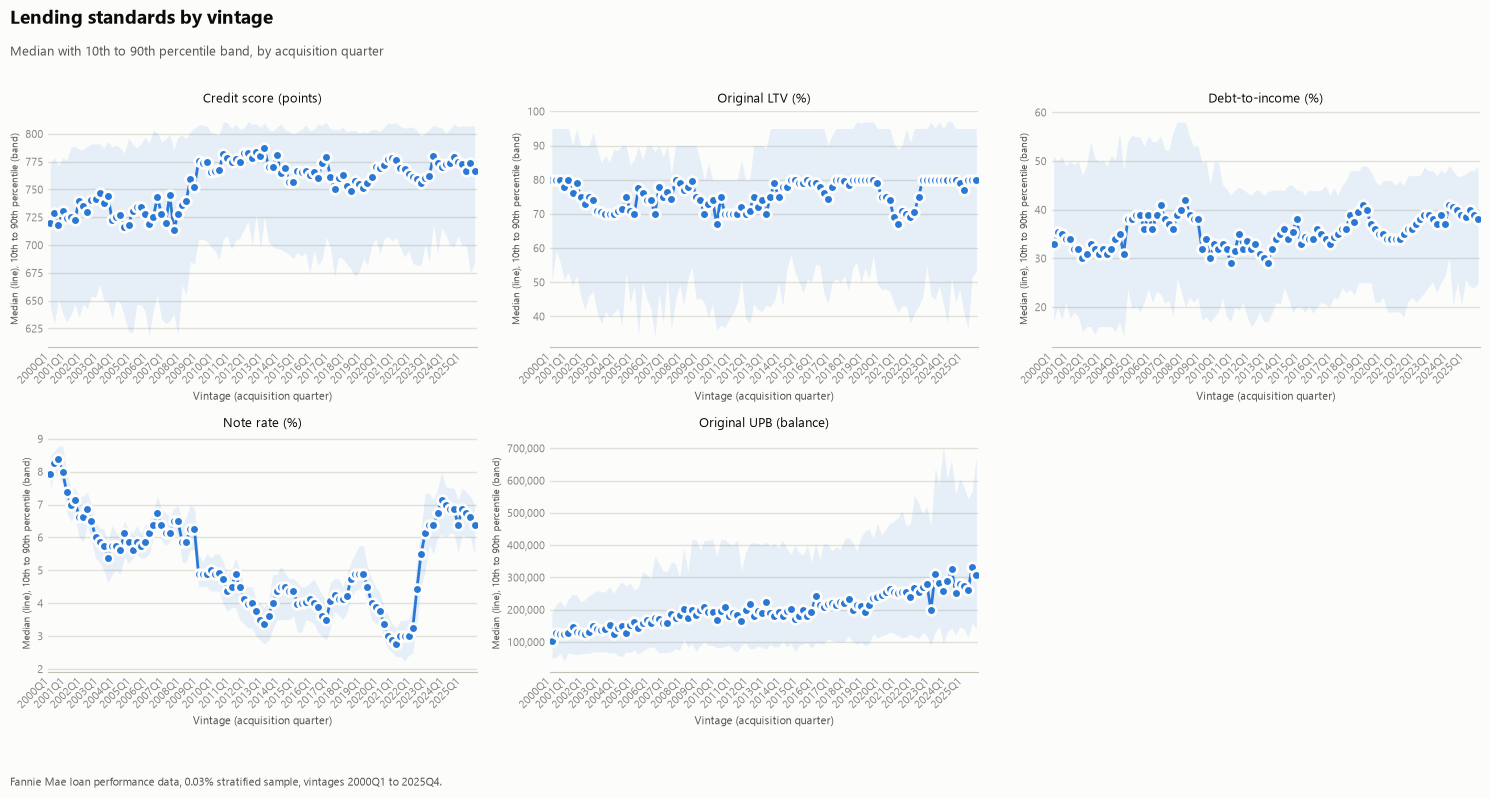

**Result.** From 2000Q1 to 2025Q4 the median credit score went from 720 to 767, LTV from 80 to 80, DTI from 33 to 38, note rate from 7.938 to 6.375 and original balance from 102,500 to 309,000.

In [36]:
# Median and 10th-90th percentile of five origination fields, by acquisition quarter.
FIVE = ["credit_score", "orig_ltv", "dti", "note_rate", "orig_upb"]
FIELDS_USED["06"] |= set(FIVE) | {"acquisition_quarter"}
parts = []
for f in FIVE:
    x = f"CAST({f} AS DOUBLE)"
    parts.append(f"quantile_cont({x}, 0.5) AS {f}_median, quantile_cont({x}, 0.1) AS {f}_p10, quantile_cont({x}, 0.9) AS {f}_p90")
by_vintage = q(f"SELECT acquisition_quarter AS vintage, count(*) AS loans, {', '.join(parts)} FROM {LOANS} GROUP BY 1 ORDER BY 1")
save_table(by_vintage, "eda_06_standards_by_vintage")
bv = by_all_quarters(by_vintage)
xs = np.arange(len(bv))
ticks = quarter_ticks(bv["vintage"].tolist())
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), FIVE):
    ax.fill_between(xs, bv[f"{f}_p10"], bv[f"{f}_p90"], color=BLUE, alpha=0.10, linewidth=0)
    ax.plot(xs, bv[f"{f}_median"], color=BLUE, linewidth=2, marker="o", markersize=7, markeredgecolor=BG, markeredgewidth=2)
    ax.set_xlim(-0.5, len(xs) - 0.5)
    if f == "orig_upb":
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.set_xticks(ticks[0])
    ax.set_xticklabels(ticks[1], rotation=45, ha="right")
    ax.set_title(LABEL[f], fontsize=9)
    ax.set_xlabel("Vintage (acquisition quarter)", fontsize=8)
    ax.set_ylabel("Median (line), 10th to 90th percentile (band)", fontsize=7.5)
    style_axes(ax, grid="y")
axes.ravel()[-1].axis("off")
save_chart(fig, "eda_06a_lending_standards_by_vintage", "Lending standards by vintage", "Median with 10th to 90th percentile band, by acquisition quarter")
f0, f1 = by_vintage.iloc[0], by_vintage.iloc[-1]
say(f"**Result.** From {f0['vintage']} to {f1['vintage']} the median credit score went from {f0['credit_score_median']:.0f} to {f1['credit_score_median']:.0f}, "
    f"LTV from {f0['orig_ltv_median']:.0f} to {f1['orig_ltv_median']:.0f}, DTI from {f0['dti_median']:.0f} to {f1['dti_median']:.0f}, "
    f"note rate from {f0['note_rate_median']:.3f} to {f1['note_rate_median']:.3f} and original balance from {f0['orig_upb_median']:,.0f} to {f1['orig_upb_median']:,.0f}.")
headline.update({"fico_median_first": float(f0["credit_score_median"]), "fico_median_last": float(f1["credit_score_median"]),
                 "ltv_median_first": float(f0["orig_ltv_median"]), "ltv_median_last": float(f1["orig_ltv_median"])})

### 06.2 Six eras

**Why:** Lending standards and results changed with the economy. Grouping loans by the year they were originated into six eras makes the changes easy to compare.

**How:** Eras by origination year: early 2000s (2000-2003; loans originated earlier are included), boom (2004-2006), crisis (2007-2009), recovery (2010-2019), pandemic (2020-2021), rate rises (2022-2025). For each era: loans, original balance, medians of five fields, and the provisional bad rate by count and by balance with a 95% interval. Vintage charts keep the acquisition quarter; era tables use the origination year.

**Answers:** How did the book and its bad rate differ by era?

In [37]:
# Loans, balance, medians and bad rate by era (origination year).
med = ", ".join(f"median(CAST({f} AS DOUBLE)) AS median_{f}" for f in FIVE)
era = q(f"SELECT era, count(*) AS loans, CAST(sum(orig_upb) AS DOUBLE) AS balance, {med}, {OUT_AGG} FROM {LOANS_OUT} GROUP BY 1")
era["order"] = era["era"].map({e: i for i, e in enumerate(ERA_NAMES)}).fillna(99)
era = rate_by_count_and_balance(era.sort_values("order").drop(columns="order").reset_index(drop=True))
era.loc[era["outcome_loans"] < MIN_CELL, ["bad_rate_count_pct", "ci_low_pct", "ci_high_pct", "bad_rate_balance_pct"]] = np.nan
era["balance_share_pct"] = 100.0 * era["balance"] / era["balance"].sum()
save_table(era, "eda_06_by_era")
ERAS_PRESENT = [e for e in ERA_NAMES if e in set(era["era"])]
say("**Result.** " + "; ".join(
    f"{r['era']}: {n(r['loans'])} loans ({pct(r['balance_share_pct'])} of balance), median credit score {r['median_credit_score']:.0f}, LTV {r['median_orig_ltv']:.0f}, "
    f"bad rate {fmt_ci(r['bad'], r['outcome_loans']) if r['outcome_loans'] >= MIN_CELL else f'fewer than {MIN_CELL:,} outcome loans'}" for _, r in era.iterrows()) + ".")

**Result.** Early 2000s: 4,127 loans (16.0% of balance), median credit score 735, LTV 74, bad rate 0.65% (0.45% to 0.95%); Boom: 1,288 loans (5.8% of balance), median credit score 728, LTV 74, bad rate 1.24% (0.77% to 2.01%); Crisis: 1,519 loans (8.7% of balance), median credit score 758, LTV 75, bad rate 3.55% (2.73% to 4.61%); Recovery: 6,070 loans (36.8% of balance), median credit score 771, LTV 75, bad rate 1.29% (1.03% to 1.60%); Pandemic: 2,891 loans (21.3% of balance), median credit score 773, LTV 70, bad rate 1.21% (0.87% to 1.68%); Rate rises: 1,380 loans (11.4% of balance), median credit score 768, LTV 80, bad rate 0.64% (0.27% to 1.49%).

### 06.3 Drift by era: PSI

**Why:** A field whose distribution moves between eras can make a model built on one era unreliable in another. The population stability index (PSI) measures the move. Rules of thumb (industry practice, not regulation): below 0.10 stable, 0.10 to 0.25 moderate shift, above 0.25 major shift.

**How:** Compare each era with one reference era: recovery (2010-2019). Numeric fields: 10 bands from the recovery deciles, blank as its own band. Category fields: one band per value. Shares are floored at 0.0001. PSI = sum of (share - reference share) x ln(share / reference share). Not worked out if recovery has fewer than `MIN_CELL` loans in scope.

**Answers:** Which fields drift between eras, and by how much?

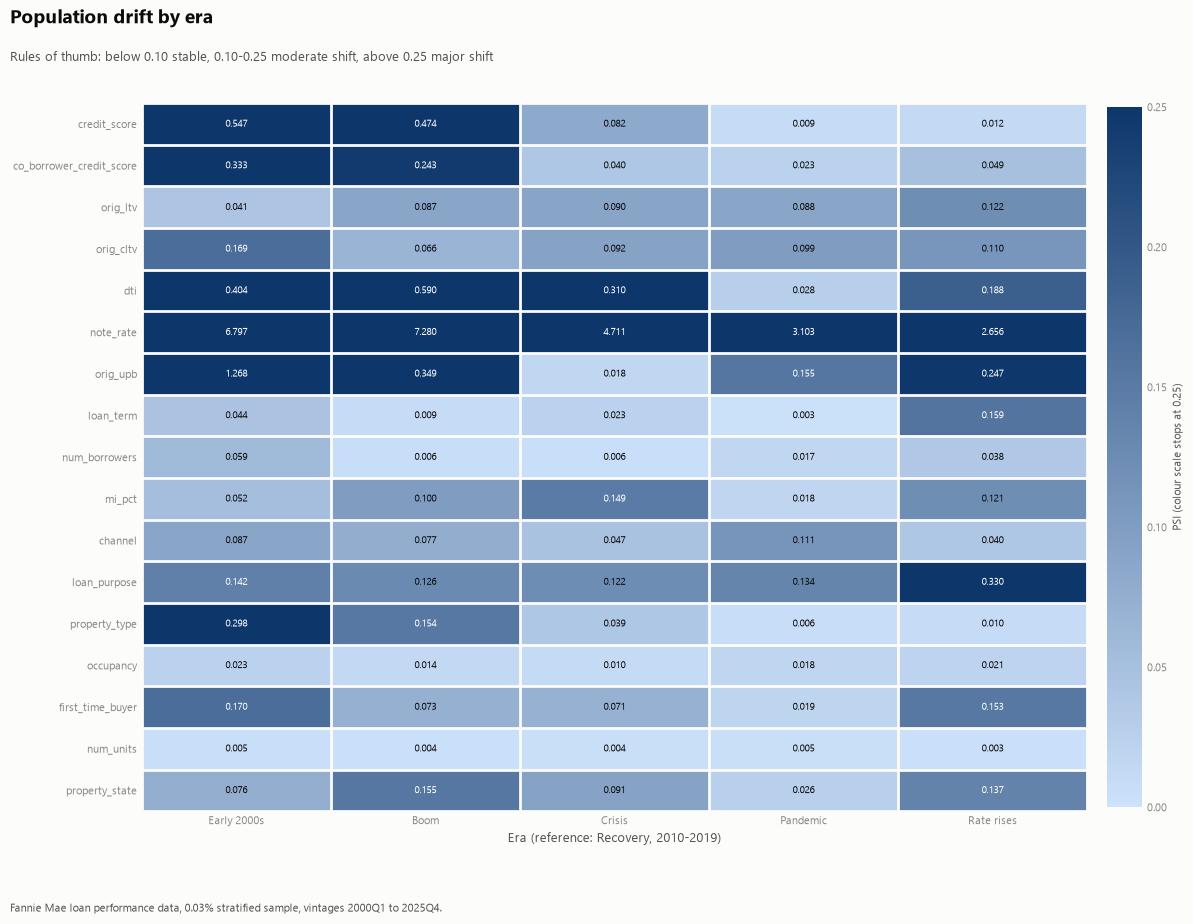

**Result.** Against the recovery era (6,070 loans), 7 of 17 fields have PSI above 0.25 in at least one era: `note_rate` (7.28), `orig_upb` (1.27), `dti` (0.59), `credit_score` (0.55), `co_borrower_credit_score` (0.33). Eras with fewer than 30 loans are not compared.

In [38]:
# PSI of each era against the recovery era (2010-2019).
REF_ERA = "Recovery"
ref_loans = int(era.loc[era["era"] == REF_ERA, "loans"].sum())
FLOOR = 0.0001
PSI_FIELDS = NUM5 + CAT5
FIELDS_USED["06"] |= set(PSI_FIELDS) | {"orig_date"}
LOANS_ERA = f"(SELECT *, {era_case('orig_date')} AS era FROM {LOANS})"
psi_long = pd.DataFrame(columns=["field", "era", "psi"])
if ref_loans < MIN_CELL:
    say(f"**Result.** Recovery has {n(ref_loans)} loans in scope (fewer than {MIN_CELL:,}), so PSI is not worked out.")
else:
    redge = q(f"SELECT {', '.join(f'quantile_cont(CAST({f} AS DOUBLE), {DECILES}) AS {f}' for f in NUM5)} FROM {LOANS_ERA} WHERE era = '{REF_ERA}'").iloc[0]
    rows = []
    loans_by_era = era.set_index("era")["loans"]
    for f in PSI_FIELDS:
        band = band_case(f, clean_edges(redge[f])) if f in NUM5 else f"coalesce(CAST({f} AS VARCHAR), 'blank')"
        d = q(f"SELECT era, {band} AS band, count(*) AS n FROM {LOANS_ERA} GROUP BY 1, 2")
        mat = d.pivot_table(index="band", columns="era", values="n", aggfunc="sum", fill_value=0)
        share = (mat / mat.sum()).clip(lower=FLOOR)
        base = share[REF_ERA]
        for e in [e for e in ERA_NAMES if e in share.columns and e != REF_ERA]:
            ok = loans_by_era.get(e, 0) >= MIN_CELL
            rows.append({"field": f, "era": e, "psi": float(((share[e] - base) * np.log(share[e] / base)).sum()) if ok else np.nan})
    psi_long = pd.DataFrame(rows)
    save_table(psi_long, "eda_06_psi_by_era")
    cols = [e for e in ERAS_PRESENT if e != REF_ERA and psi_long["era"].eq(e).any()]
    if cols:
        pivot = psi_long.pivot(index="field", columns="era", values="psi").loc[PSI_FIELDS, cols]
        fig, ax = plt.subplots(figsize=(max(7, 1.6 * len(cols) + 4), 0.4 * len(pivot) + 2.5))
        draw_heatmap(ax, pivot.values, pivot.index.tolist(), cols, ONE_HUE, 0, 0.25, cell_text=[[("" if np.isnan(v) else f"{v:.3f}") for v in row] for row in pivot.values],
                     bar_label="PSI (colour scale stops at 0.25)")
        ax.set_xlabel(f"Era (reference: {REF_ERA}, 2010-2019)")
        save_chart(fig, "eda_06b_psi_by_era", "Population drift by era", "Rules of thumb: below 0.10 stable, 0.10-0.25 moderate shift, above 0.25 major shift")
        PSI_MAX = psi_long.groupby("field")["psi"].max()
        over = PSI_MAX[PSI_MAX > 0.25]
        say(f"**Result.** Against the recovery era ({n(ref_loans)} loans), {len(over)} of {len(PSI_FIELDS)} fields have PSI above 0.25 in at least one era"
            + (": " + ", ".join(f"`{f}` ({v:.2f})" for f, v in over.sort_values(ascending=False).head(5).items()) if len(over) else "")
            + f". Eras with fewer than {MIN_CELL:,} loans are not compared.")
    else:
        PSI_MAX = pd.Series(dtype=float)
        say(f"**Result.** No era other than recovery has {MIN_CELL:,} loans, so there is nothing to compare.")
if "PSI_MAX" not in globals():
    PSI_MAX = pd.Series(dtype=float)

### 06.4 Bad rate by vintage, beside the economy

**Why:** A vintage that looks worse than its neighbours may reflect lending standards or the economy at the time. The federal funds rate and the unemployment rate at origination are shown on the same time axis.

**How:** Bad rate by acquisition quarter, by loan count (with a 95% interval) and weighted by original balance. Below, the federal funds rate and the unemployment rate at the loan's origination month (`macro_monthly_table`), averaged over the loans of each vintage. Vintages with fewer than `MIN_CELL` outcome loans are left off. These are US series: see `docs\departures_from_uk_rules.md` (D-025). The panels describe the past and apply no publication lag.

**Answers:** How did the provisional bad rate move across vintages, and what was the economy doing?

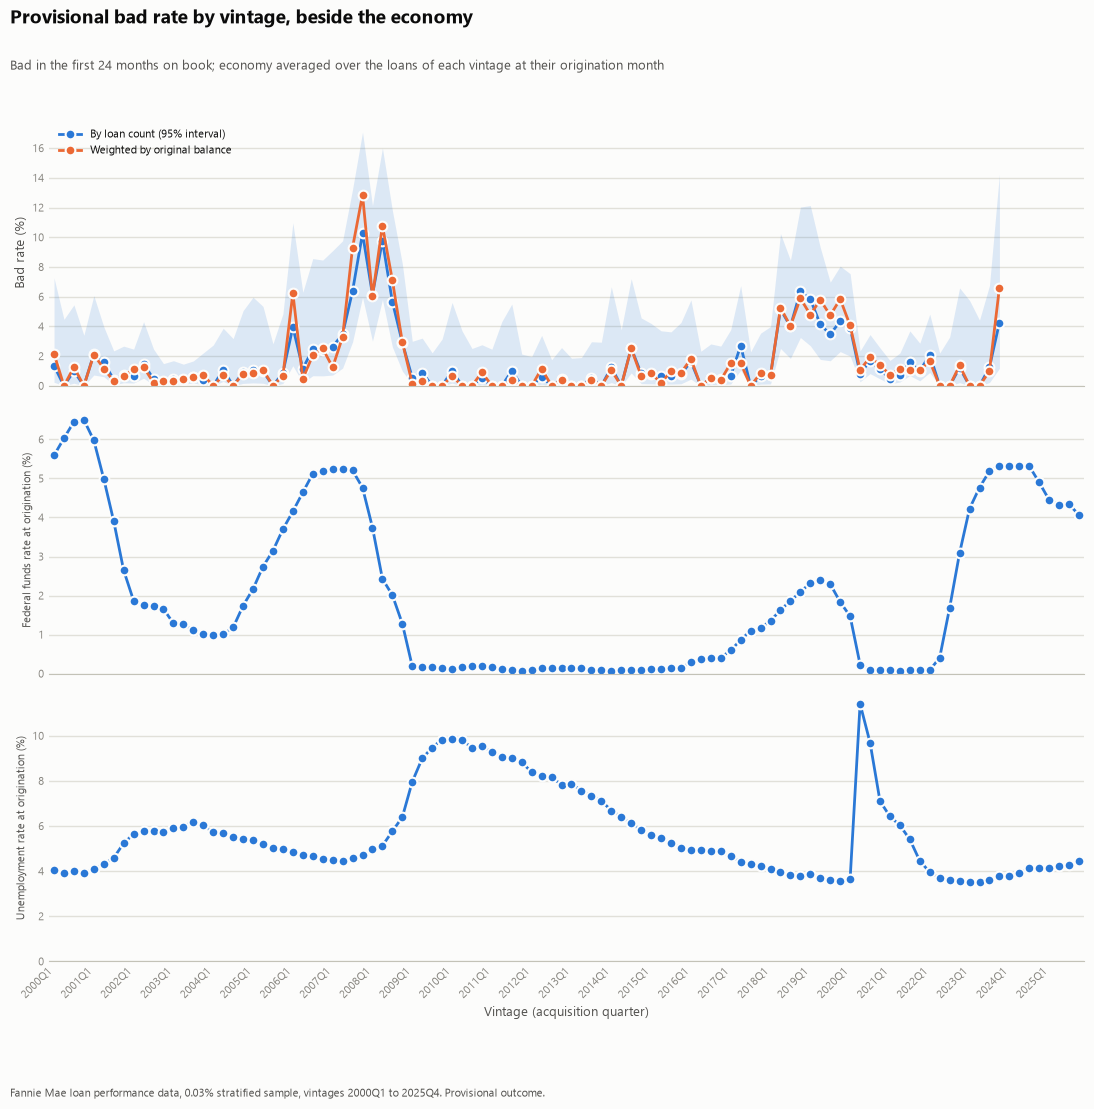

**Result.** The bad rate by count is highest for the 2007Q4 vintage (10.26% (5.96% to 17.07%)) and lowest for 2000Q2 (0.00% (0.00% to 4.48%)); the gap is 10.26 percentage points. The loan-weighted federal funds rate at origination was 4.76% for the highest and 6.03% for the lowest vintage; unemployment 4.69% and 3.94%.

In [39]:
# Provisional bad rate by acquisition quarter, with the economy at origination.
FIELDS_USED["06"] |= {"orig_date", "acquisition_quarter", "orig_upb"}
if MACRO_OK:
    macro_sel = ("avg(CAST(m.federal_funds_rate_pct AS DOUBLE)) AS fed_funds_rate_pct, avg(CAST(m.unemployment_rate_pct AS DOUBLE)) AS unemployment_rate_pct")
    macro_join = "LEFT JOIN macro_monthly_table m ON m.period = CAST(date_trunc('month', l.orig_date) AS DATE)"
else:
    macro_sel, macro_join = "CAST(NULL AS DOUBLE) AS fed_funds_rate_pct, CAST(NULL AS DOUBLE) AS unemployment_rate_pct", ""
vint = q(f"""SELECT l.acquisition_quarter AS vintage, count(*) AS loans, {OUT_AGG.replace('outcome', 'l.outcome').replace('orig_upb', 'l.orig_upb')},
                    count(*) FILTER (WHERE l.outcome = 'not yet observed') AS not_yet_observed, {macro_sel}
             FROM {LOANS_OUT} l {macro_join} GROUP BY 1 ORDER BY 1""")
vint = rate_by_count_and_balance(vint)
vint.loc[vint["outcome_loans"] < MIN_CELL, ["bad_rate_count_pct", "ci_low_pct", "ci_high_pct", "bad_rate_balance_pct"]] = np.nan
save_table(vint, "eda_06_bad_rate_by_vintage")
vp = by_all_quarters(vint)
xs = np.arange(len(vp))
ticks = quarter_ticks(vp["vintage"].tolist())
panels = 3 if MACRO_OK else 1
fig, axes = plt.subplots(panels, 1, figsize=(11, 3.4 * panels + 1), sharex=True)
axes = np.atleast_1d(axes)
a = axes[0]
a.fill_between(xs, vp["ci_low_pct"], vp["ci_high_pct"], color=BLUE, alpha=0.15, linewidth=0)
a.plot(xs, vp["bad_rate_count_pct"], color=BLUE, marker="o", markersize=7, markeredgecolor=BG, markeredgewidth=1.5, label="By loan count (95% interval)")
a.plot(xs, vp["bad_rate_balance_pct"], color=ORANGE, marker="o", markersize=7, markeredgecolor=BG, markeredgewidth=1.5, label="Weighted by original balance")
a.set_ylim(bottom=0)
a.set_ylabel("Bad rate (%)")
a.legend(frameon=False, fontsize=8, loc="upper left")
style_axes(a, grid="y")
if MACRO_OK:
    for ax_, col, lab, colr in ((axes[1], "fed_funds_rate_pct", "Federal funds rate at origination (%)", BLUE), (axes[2], "unemployment_rate_pct", "Unemployment rate at origination (%)", BLUE)):
        ax_.plot(xs, vp[col], color=colr, marker="o", markersize=7, markeredgecolor=BG, markeredgewidth=1.5)
        ax_.set_ylim(bottom=0)
        ax_.set_ylabel(lab, fontsize=8)
        style_axes(ax_, grid="y")
axes[-1].set_xticks(ticks[0])
axes[-1].set_xticklabels(ticks[1], rotation=45, ha="right")
axes[-1].set_xlabel("Vintage (acquisition quarter)")
axes[-1].set_xlim(-0.5, len(xs) - 0.5)
save_chart(fig, "eda_06c_bad_rate_by_vintage", "Provisional bad rate by vintage, beside the economy", "Bad in the first 24 months on book; economy averaged over the loans of each vintage at their origination month", provisional=True)
vv = vint.dropna(subset=["bad_rate_count_pct"])
if len(vv):
    hi_, lo_ = vv.loc[vv["bad_rate_count_pct"].idxmax()], vv.loc[vv["bad_rate_count_pct"].idxmin()]
    say((f"Only {len(vv)} vintage(s) in scope: too few to describe a cycle. " if len(vv) < 3 else "") + f"**Result.** The bad rate by count is highest for the {hi_['vintage']} vintage ({fmt_ci(hi_['bad'], hi_['outcome_loans'])}) and lowest for {lo_['vintage']} ({fmt_ci(lo_['bad'], lo_['outcome_loans'])}); "
        f"the gap is {hi_['bad_rate_count_pct'] - lo_['bad_rate_count_pct']:.2f} percentage points. "
        + (f"The loan-weighted federal funds rate at origination was {hi_['fed_funds_rate_pct']:.2f}% for the highest and {lo_['fed_funds_rate_pct']:.2f}% for the lowest vintage; "
           f"unemployment {hi_['unemployment_rate_pct']:.2f}% and {lo_['unemployment_rate_pct']:.2f}%." if MACRO_OK else ""))
else:
    say(f"**Result.** No vintage has {MIN_CELL:,} outcome loans.")

### 06.5 Indexed LTV over the loan's life

**Why:** Original LTV does not show how much equity is left. Moving the property value with the house price index of the state gives an estimate of the current LTV through time.

**How:** Original property value = original balance / original LTV. Indexed value in month t = original value x state house price index (`macro_state_hpi_table`, not seasonally adjusted) of the quarter holding t / index of the quarter holding the origination month. Current indexed LTV = current balance / indexed value x 100, on rows with a balance above zero. Median, 90th percentile and the share above 100 are shown by month. This describes the past and applies no publication lag. Needs the macro tables as rebuilt by the fixed macro script.

**Answers:** How did the loan-to-value of the book move after origination?

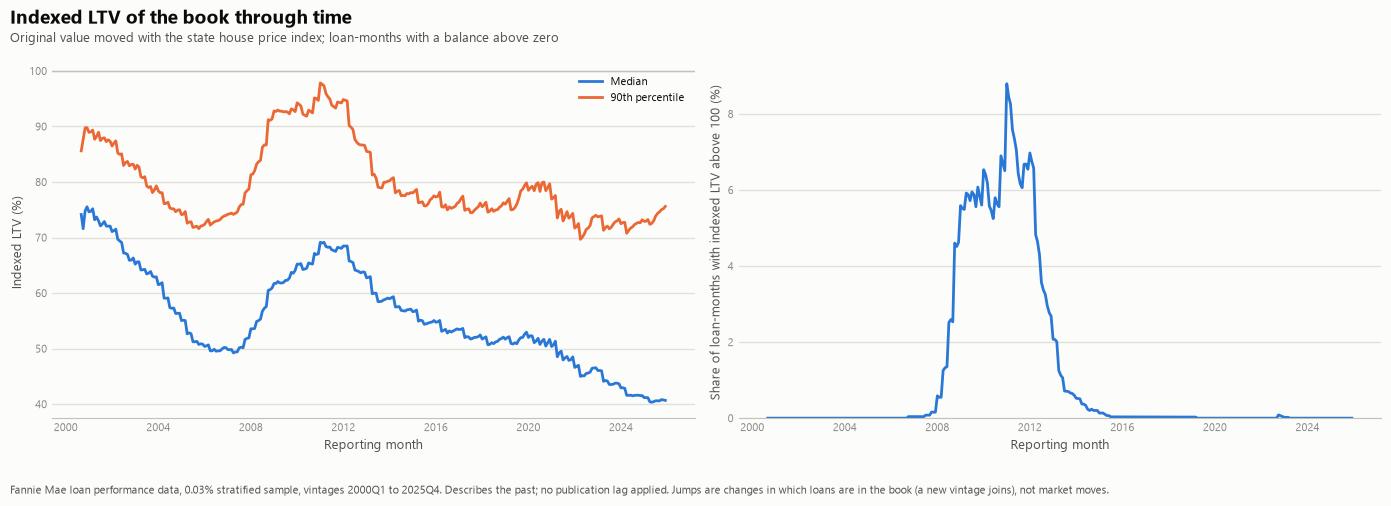

**Result (0.03% stratified sample).** The median indexed LTV was 74% in 2000-09 and 41% in 2025-12. The share of loan-months above 100% peaked at 8.8% in 2011-01.

In [40]:
# Indexed LTV by month on the active monthly subset.
FIELDS_USED["06"] |= {"orig_upb", "orig_ltv", "orig_date", "property_state", "current_upb"}
if not MACRO_OK:
    ILTV = None
    say("**Result.** The macro tables are missing, so indexed LTV is not worked out.")
else:
    hpi = "(SELECT state, CAST(quarter_date AS DATE) AS qd, CAST(house_price_index_nsa AS DOUBLE) AS hpi FROM macro_state_hpi_table WHERE house_price_index_nsa IS NOT NULL)"
    ILTV = q(f"""
        WITH x AS (
            SELECT m.rp, 100.0 * CAST(m.upb AS DOUBLE) / (CAST(l.orig_upb AS DOUBLE) / (l.orig_ltv / 100.0) * h1.hpi / h0.hpi) AS ltv_now
            FROM subset_months m
            JOIN {SUBSET_LOANS} l ON l.loan_id = m.loan_id
            JOIN {hpi} h0 ON h0.state = l.property_state AND h0.qd = CAST(date_trunc('quarter', l.orig_date) AS DATE)
            JOIN {hpi} h1 ON h1.state = l.property_state AND h1.qd = CAST(date_trunc('quarter', m.rp) AS DATE)
            WHERE m.upb > 0 AND l.orig_ltv > 0)
        SELECT rp, count(*) AS loans, median(ltv_now) AS median_ltv, quantile_cont(ltv_now, 0.9) AS p90_ltv,
               100.0 * count(*) FILTER (WHERE ltv_now > 100) / count(*) AS share_above_100_pct
        FROM x GROUP BY 1 ORDER BY 1""")
    ILTV["rp"] = pd.to_datetime(ILTV["rp"])
    ILTV = ILTV[ILTV["loans"] >= MIN_CELL].reset_index(drop=True)
    save_table(ILTV.assign(rp=ILTV["rp"].dt.strftime("%Y-%m")), "eda_06_indexed_ltv_by_month")
    if len(ILTV):
        ILP = ILTV.set_index("rp").reindex(pd.date_range(ILTV["rp"].min(), ILTV["rp"].max(), freq="MS")).rename_axis("rp").reset_index()
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
        a1.plot(ILP["rp"], ILP["median_ltv"], color=BLUE, label="Median")
        a1.plot(ILP["rp"], ILP["p90_ltv"], color=ORANGE, label="90th percentile")
        a1.axhline(100, color=AXLINE, linewidth=1)
        a1.set_ylabel("Indexed LTV (%)")
        a1.legend(frameon=False, fontsize=8)
        a2.plot(ILP["rp"], ILP["share_above_100_pct"], color=BLUE)
        a2.set_ylabel("Share of loan-months with indexed LTV above 100 (%)")
        for a_ in (a1, a2):
            a_.set_xlabel("Reporting month")
            style_axes(a_, grid="y")
        a2.set_ylim(bottom=0)
        save_chart(fig, "eda_06d_indexed_ltv", "Indexed LTV of the book through time", "Original value moved with the state house price index; loan-months with a balance above zero", subset=True,
                   note="Describes the past; no publication lag applied. " + JUMP_NOTE)
        pk = ILTV.loc[ILTV["share_above_100_pct"].idxmax()]
        say(f"**Result {SUBSET_TAG}.** The median indexed LTV was {ILTV['median_ltv'].iloc[0]:.0f}% in {ILTV['rp'].iloc[0]:%Y-%m} and {ILTV['median_ltv'].iloc[-1]:.0f}% in {ILTV['rp'].iloc[-1]:%Y-%m}. "
            f"The share of loan-months above 100% peaked at {pk['share_above_100_pct']:.1f}% in {pk['rp']:%Y-%m}.")
    else:
        say(f"**Result.** No month has {MIN_CELL:,} loans with a house price index, so the chart is not drawn.")

### 06.6 State

**Why:** Geography shows concentration and regional differences in risk.

**How:** For each property state: loans, share of original balance, and the provisional bad rate by count (95% interval) and by balance. States with fewer than `MIN_CELL` outcome loans are folded into other states. The concentration index (Herfindahl) is the sum of the squared balance shares: 1 means one state, and one divided by the index is the number of equal-sized states that would give the same concentration.

**Answers:** Which states carry the book, and where is the bad rate highest and lowest?

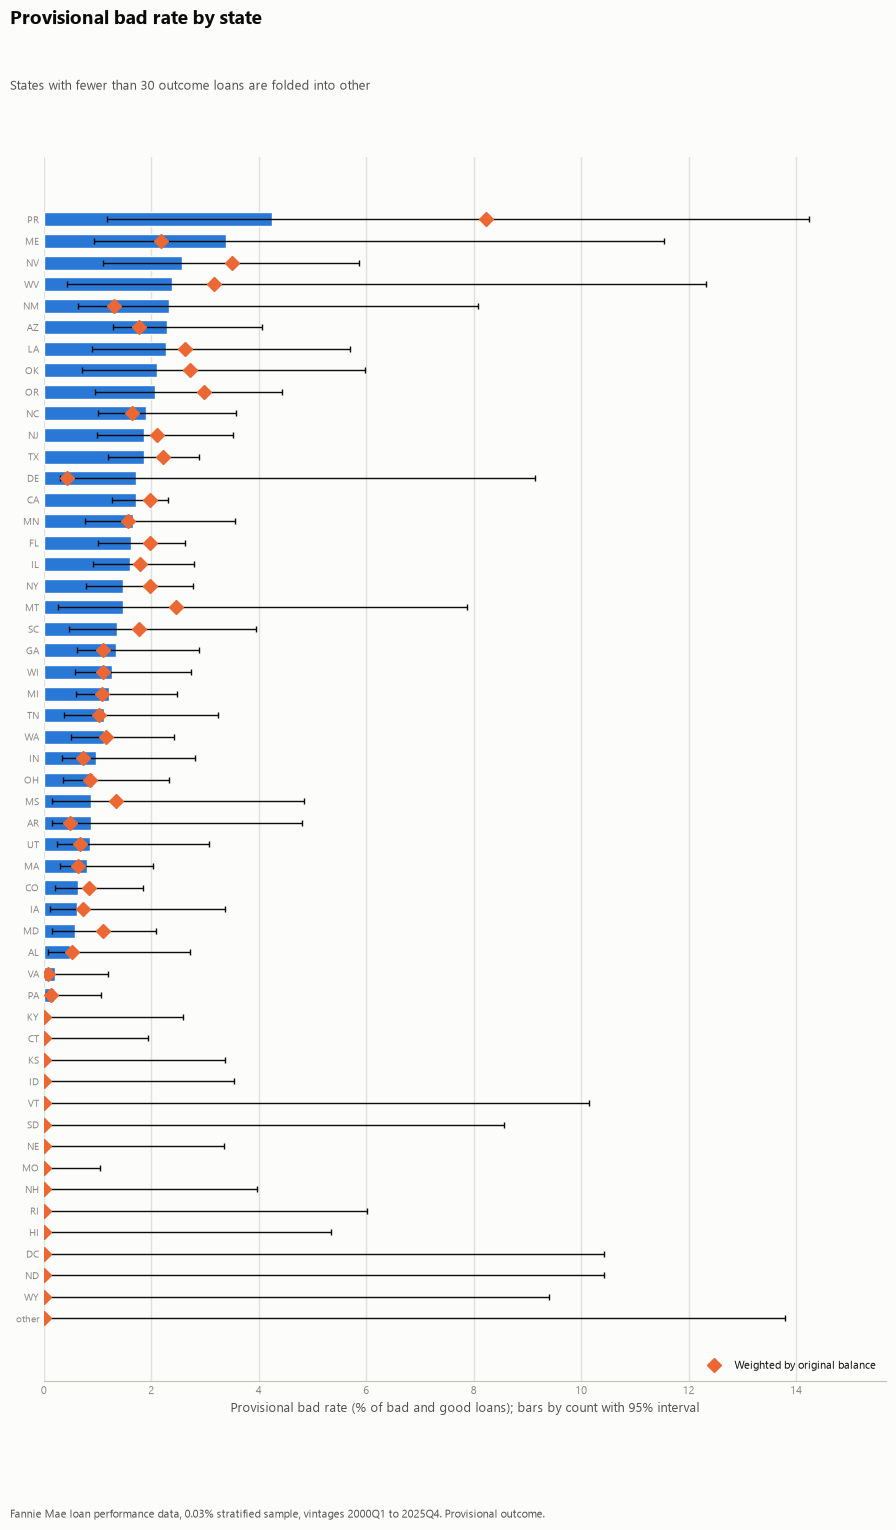

**Result.** 51 states are shown and 2 are folded into other. The bad rate by count is highest in PR (4.26% (1.17% to 14.25%)) and lowest in WY (0.00% (0.00% to 9.41%)). The three largest states hold 31.2% of the balance (CA, TX, FL). The concentration index is 0.0631, like 15.9 equal-sized states.

In [41]:
# Loans, balance share and bad rate by state; the Herfindahl index of balance shares.
FIELDS_USED["06"] |= {"property_state"}
st = q(f"SELECT coalesce(property_state, 'blank') AS state, count(*) AS loans, CAST(sum(orig_upb) AS DOUBLE) AS balance, {OUT_AGG} FROM {LOANS_OUT} GROUP BY 1")
st["balance_share"] = st["balance"] / st["balance"].sum()
HHI_STATE = float((st["balance_share"] ** 2).sum())
by_state, folded = fold_small(st, "state", sort_by=None, extra=("loans", "balance"))
big = by_state[by_state["state"] != "other"].sort_values("bad_rate_count_pct", ascending=False)
by_state = pd.concat([big, by_state[by_state["state"] == "other"]], ignore_index=True)
by_state["balance_share_pct"] = 100.0 * by_state["balance"] / st["balance"].sum()
save_table(by_state, "eda_06_by_state")
fig, ax = plt.subplots(figsize=(9, max(4, 0.26 * len(by_state) + 2)))
y = np.arange(len(by_state))
ax.barh(y, by_state["bad_rate_count_pct"], height=0.65, color=BLUE, edgecolor=BG, linewidth=1)
ax.errorbar(by_state["bad_rate_count_pct"], y, xerr=[by_state["bad_rate_count_pct"] - by_state["ci_low_pct"], by_state["ci_high_pct"] - by_state["bad_rate_count_pct"]], fmt="none", ecolor=INK, capsize=2, linewidth=1)
ax.plot(by_state["bad_rate_balance_pct"], y, linestyle="none", marker="D", markersize=7, color=ORANGE, label="Weighted by original balance")
ax.set_yticks(y)
ax.set_yticklabels(by_state["state"], fontsize=7.5)
ax.invert_yaxis()
ax.set_xlim(0, max(by_state["ci_high_pct"].max(), by_state["bad_rate_balance_pct"].max()) * 1.1)
ax.set_xlabel("Provisional bad rate (% of bad and good loans); bars by count with 95% interval")
ax.legend(frameon=False, fontsize=8, loc="lower right")
style_axes(ax, grid="x")
save_chart(fig, "eda_06e_bad_rate_by_state", "Provisional bad rate by state", f"States with fewer than {MIN_CELL:,} outcome loans are folded into other", provisional=True)
real = by_state[by_state["state"] != "other"]
top_share = st.sort_values("balance_share", ascending=False).head(3)
say(f"**Result.** {len(real)} states are shown and {folded} are folded into other. "
    + (f"The bad rate by count is highest in {real.iloc[0]['state']} ({fmt_ci(real.iloc[0]['bad'], real.iloc[0]['outcome_loans'])}) and lowest in {real.iloc[-1]['state']} ({fmt_ci(real.iloc[-1]['bad'], real.iloc[-1]['outcome_loans'])}). " if len(real) else "")
    + f"The three largest states hold {pct(100 * top_share['balance_share'].sum())} of the balance ({', '.join(top_share['state'])}). "
    f"The concentration index is {HHI_STATE:.4f}, like {1 / HHI_STATE:.1f} equal-sized states.")
headline["state_hhi"] = round(HHI_STATE, 4)

### 06.7 Active loans by month

**Why:** The number of loans still on the books each month shows the size of the portfolio over time.

**How:** Use the monthly scan (scan 2). A monthly row counts as an active loan when it has no exit code.

**Answers:** How many loans are active each month, and when was the peak?

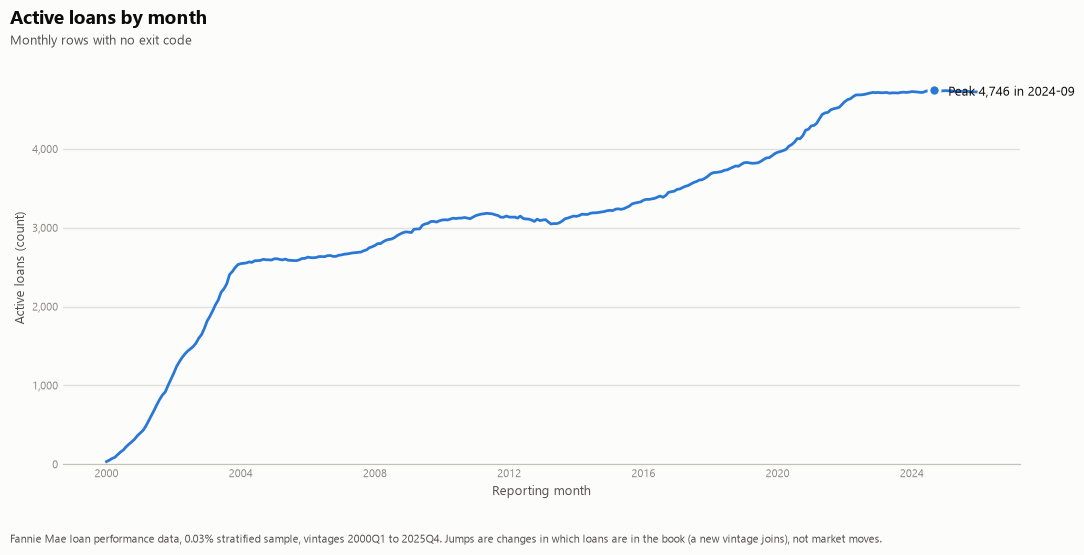

**Result.** Active loans peaked at 4,746 in September 2024; in December 2025 there were 4,724.

In [42]:
# Active loans by month (from scan 2).
save_table(by_month[["reporting_period", "monthly_rows", "active_loans"]].assign(reporting_period=by_month["reporting_period"].dt.strftime("%Y-%m")), "eda_06_active_by_month")
peak = by_month.loc[by_month["active_loans"].idxmax()]
last = by_month.iloc[-1]
fig, ax = plt.subplots(figsize=(11, 5.5))
am = by_month.set_index("reporting_period").reindex(pd.date_range(by_month["reporting_period"].min(), by_month["reporting_period"].max(), freq="MS")).rename_axis("reporting_period").reset_index()
ax.plot(am["reporting_period"], am["active_loans"], color=BLUE, linewidth=2)
ax.plot([peak["reporting_period"]], [peak["active_loans"]], marker="o", markersize=8, color=BLUE, markeredgecolor=BG, markeredgewidth=2)
ax.annotate(f"Peak {int(peak['active_loans']):,} in {peak['reporting_period']:%Y-%m}", (peak["reporting_period"], peak["active_loans"]), textcoords="offset points", xytext=(10, -4), fontsize=9, color=INK)
ax.set_ylim(bottom=0)
ax.set_xlabel("Reporting month")
ax.set_ylabel("Active loans (count)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
style_axes(ax, grid="y")
save_chart(fig, "eda_06f_active_loans_by_month", "Active loans by month", "Monthly rows with no exit code", note=JUMP_NOTE)
headline.update({"active_peak": int(peak["active_loans"]), "active_peak_month": f"{peak['reporting_period']:%Y-%m}", "active_last": int(last["active_loans"])})
say(f"**Result.** Active loans peaked at {n(peak['active_loans'])} in {peak['reporting_period']:%B %Y}; in {last['reporting_period']:%B %Y} there were {n(last['active_loans'])}.")

In [43]:
say("## Section 06 - What this shows, and which later module uses it")
say(f"Medians moved from credit score {f0['credit_score_median']:.0f} ({f0['vintage']}) to {f1['credit_score_median']:.0f} ({f1['vintage']}), and LTV from {f0['orig_ltv_median']:.0f} to {f1['orig_ltv_median']:.0f}. "
    + (f"{int((PSI_MAX > 0.25).sum())} fields drift by more than 0.25 between eras, which Module 3 (`03_rating_and_pd`) takes into account when it picks development and validation windows. " if len(PSI_MAX) and len(ERAS_PRESENT) >= 3 else f"Only {len(ERAS_PRESENT)} eras are in scope, too few to describe drift over the cycle. ")
    + (f"The bad rate swings by {hi_['bad_rate_count_pct'] - lo_['bad_rate_count_pct']:.1f} points between the best and worst vintage, which is the first picture of how results depend on the cycle (Module 7, `07_stress_testing`). " if len(vv) >= 3 else f"Only {len(vv)} vintage(s) are in scope, too few to describe a cycle. ")
    + f"The state concentration index is {HHI_STATE:.4f}; Module 2 (`05_concentrations.py`) builds the full concentration view. Indexed LTV feeds the loss work in Module 4 (`04_lgd_ead`).")

## Section 06 - What this shows, and which later module uses it

Medians moved from credit score 720 (2000Q1) to 767 (2025Q4), and LTV from 80 to 80. 7 fields drift by more than 0.25 between eras, which Module 3 (`03_rating_and_pd`) takes into account when it picks development and validation windows. The bad rate swings by 10.3 points between the best and worst vintage, which is the first picture of how results depend on the cycle (Module 7, `07_stress_testing`). The state concentration index is 0.0631; Module 2 (`05_concentrations.py`) builds the full concentration view. Indexed LTV feeds the loss work in Module 4 (`04_lgd_ead`).

# Section 07 - The outcome

**Answers:** How many loans are bad, good, excluded or not yet observed? What is bad made of, how do loans move through delinquency, and where does the bad rate sit across credit score and LTV?

### 07.1 Size and make-up of the outcome

**Why:** We need to know how many loans are bad, how many were left out and why, before trusting any bad rate.

**How:** Count loans by outcome and by original balance from the TEMP table. For bad loans, count the first trigger: the trigger in the earliest bad month (ties: 90+ days first, then modification, then credit exit).

**Answers:** How many loans are bad, good, excluded or not yet observed, and what is bad made of?

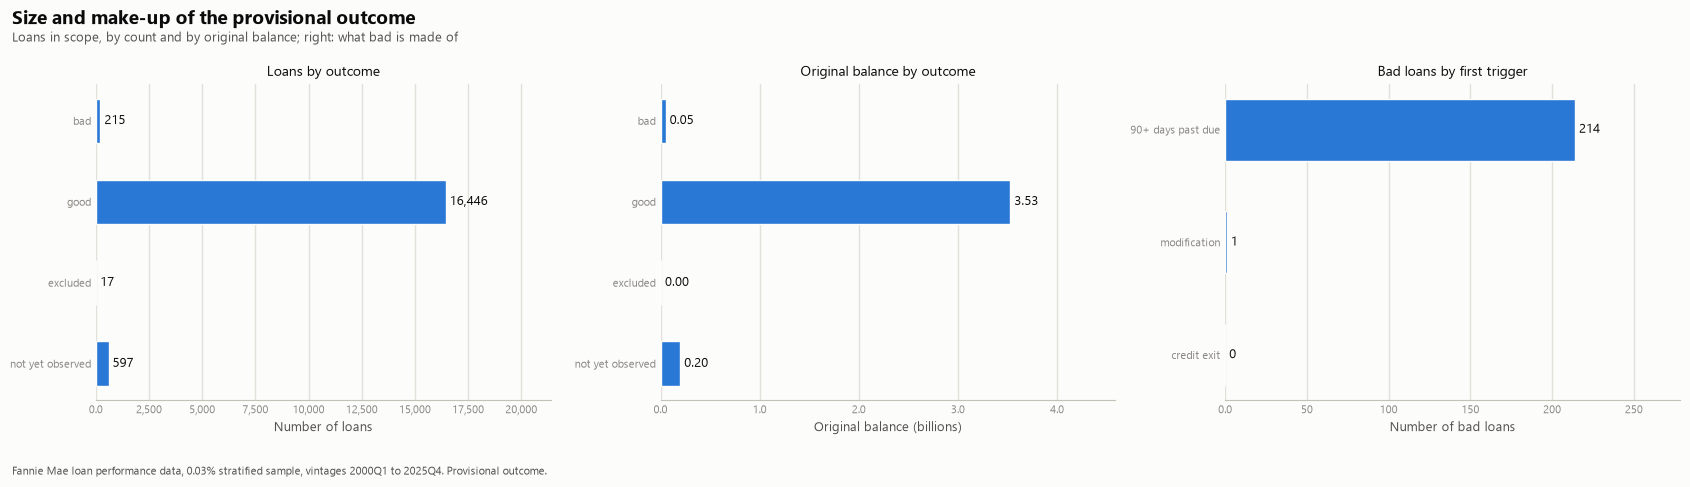

**Result.** Bad 215, good 16,446, excluded 17, not yet observed 597. The bad rate is 1.29% (1.13% to 1.47%) by count and 1.45% by original balance. Bad loans by first trigger: 90+ days past due 99.5%, modification 0.5%, credit exit 0.0%.

In [44]:
# Loans and original balance by provisional outcome; bad loans by first trigger.
oc_bal = outcome_counts["balance"]
TRIGGERS = ["90+ days past due", "modification", "credit exit"]
trig = q("SELECT first_trigger, count(*) AS loans FROM loan_outcome WHERE outcome = 'bad' GROUP BY 1").set_index("first_trigger")["loans"].reindex(TRIGGERS).fillna(0)
outcome_table = pd.DataFrame(
    [{"part": "outcome", "name": k, "loans": OUTCOME_N[k], "pct_of_loans": 100.0 * OUTCOME_N[k] / LOANS_N,
      "original_balance": float(oc_bal[k]), "pct_of_balance": 100.0 * float(oc_bal[k]) / float(oc_bal.sum())} for k in OUTCOME_ORDER]
    + [{"part": "of which excluded", "name": "joined after month 24", "loans": JOINED_LATE, "pct_of_loans": 100.0 * JOINED_LATE / LOANS_N, "original_balance": np.nan, "pct_of_balance": np.nan}]
    + [{"part": "first trigger of bad loans", "name": k, "loans": int(trig[k]), "pct_of_loans": 100.0 * trig[k] / max(trig.sum(), 1), "original_balance": np.nan, "pct_of_balance": np.nan} for k in TRIGGERS])
save_table(outcome_table, "eda_07_outcome")
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, names, vals, xl, ttl, fmt_ in ((a1, OUTCOME_ORDER, [OUTCOME_N[k] for k in OUTCOME_ORDER], "Number of loans", "Loans by outcome", "{:,.0f}"),
                                      (a2, OUTCOME_ORDER, [float(oc_bal[k]) / 1e9 for k in OUTCOME_ORDER], "Original balance (billions)", "Original balance by outcome", "{:,.2f}"),
                                      (a3, TRIGGERS, [int(trig[k]) for k in TRIGGERS], "Number of bad loans", "Bad loans by first trigger", "{:,.0f}")):
    y = np.arange(len(names))
    ax.barh(y, vals, height=0.55, color=BLUE, edgecolor=BG, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(names)
    ax.invert_yaxis()
    for yi, v in zip(y, vals):
        ax.text(v, yi, " " + fmt_.format(v), va="center", ha="left", fontsize=9)
    ax.set_xlim(0, max(max(vals), 1e-9) * 1.3)
    ax.set_xlabel(xl)
    ax.set_title(ttl, fontsize=10)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}" if x >= 10 else f"{x:,.1f}"))
    style_axes(ax, grid="x")
save_chart(fig, "eda_07a_outcome_breakdown", "Size and make-up of the provisional outcome", "Loans in scope, by count and by original balance; right: what bad is made of", provisional=True)
BAD_RATE = 100.0 * bad_n / (bad_n + good_n) if bad_n + good_n else float("nan")
bal_rate = 100.0 * float(oc_bal["bad"]) / (float(oc_bal["bad"]) + float(oc_bal["good"])) if (oc_bal["bad"] + oc_bal["good"]) > 0 else float("nan")
headline.update({"outcome_bad": bad_n, "outcome_good": good_n, "outcome_excluded": OUTCOME_N["excluded"], "outcome_not_yet_observed": OUTCOME_N["not yet observed"],
                 "bad_rate_count_pct": round(BAD_RATE, 2), "bad_rate_balance_pct": round(bal_rate, 2)})
say(f"**Result.** Bad {n(bad_n)}, good {n(good_n)}, excluded {n(OUTCOME_N['excluded'])}, not yet observed {n(OUTCOME_N['not yet observed'])}. "
    f"The bad rate is {fmt_ci(bad_n, bad_n + good_n)} by count and {pct(bal_rate, 2)} by original balance. "
    "Bad loans by first trigger: " + ", ".join(f"{k} {pct(100 * trig[k] / max(trig.sum(), 1))}" for k in TRIGGERS) + ".")

### 07.2 Delinquency status

**Why:** How many months behind each loan-month is shows how the book moves from current to default.

**How:** Add up the delinquency buckets from the monthly scan (scan 2): current (0), 1, 2, 3, 4, 5, 6 or more months behind, XX (status unknown) and blank.

**Answers:** How are loan-months spread across delinquency status?

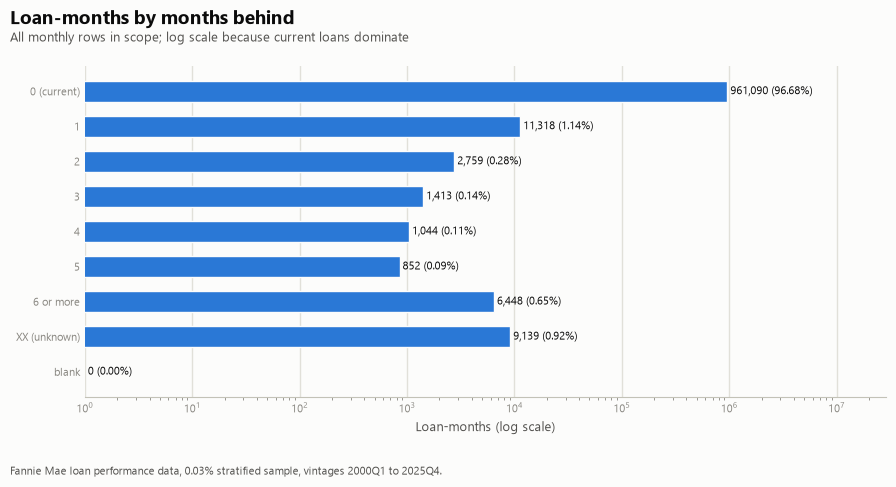

**Result.** 96.68% of loan-months are current. 3 or more months behind: 0.98%. Status XX (unknown) is 9,139 loan-months and blank is 0.

In [45]:
# Loan-months by delinquency bucket (from scan 2), including XX (unknown).
bucket_cols = [("0 (current)", "dq_0"), ("1", "dq_1"), ("2", "dq_2"), ("3", "dq_3"), ("4", "dq_4"), ("5", "dq_5"), ("6 or more", "dq_6plus"), ("XX (unknown)", "dq_xx"), ("blank", "dq_blank")]
dq = pd.DataFrame([{"months_behind": lab, "loan_months": int(by_month[c].sum())} for lab, c in bucket_cols])
dq["pct_of_loan_months"] = 100.0 * dq["loan_months"] / dq["loan_months"].sum()
save_table(dq, "eda_07_delinquency_status")
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(dq))
ax.barh(y, dq["loan_months"], height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(dq["months_behind"])
ax.invert_yaxis()
ax.set_xscale("log")
for yi, v, s in zip(y, dq["loan_months"], dq["pct_of_loan_months"]):
    ax.text(max(v, 1), yi, f" {int(v):,} ({s:.2f}%)", va="center", ha="left", fontsize=8)
ax.set_xlim(1, dq["loan_months"].max() * 30)
ax.set_xlabel("Loan-months (log scale)")
style_axes(ax, grid="x")
save_chart(fig, "eda_07b_delinquency_status", "Loan-months by months behind", "All monthly rows in scope; log scale because current loans dominate")
dqi = dq.set_index("months_behind")
say(f"**Result.** {pct(dqi.loc['0 (current)', 'pct_of_loan_months'], 2)} of loan-months are current. 3 or more months behind: "
    f"{pct(dqi.loc[['3', '4', '5', '6 or more'], 'pct_of_loan_months'].sum(), 2)}. Status XX (unknown) is {n(dqi.loc['XX (unknown)', 'loan_months'])} loan-months and blank is {n(dqi.loc['blank', 'loan_months'])}.")

### 07.3 Cure rates

**Why:** How often a loan that falls behind gets back to current, and how it gets there, shows how deep arrears can go before they rarely recover. Getting back to current through a modification or a payment deferral is not the same as a borrower catching up, so it is shown separately. This describes cure behaviour. It does not set a default line.

**How:** On the active monthly subset, take each loan's first month at exactly m months behind (m = 1, 2, 3, 4). Only first entries with a full 12 months inside the data are counted. Each entry falls in one of three groups. (a) Back to current at least once within 12 months, without a new modification or deferral: this is the headline. (b) Back to current through a modification (flag Y in the cure month but not in the entry month) or a payment deferral (code P, C or D in any month from entry to cure). (c) Paid off (exit code 01) within 12 months without a month at 0 months behind. Rates carry a Wilson 95% interval.

**Answers:** Of loans 1, 2, 3 and 4 months behind, how many get back to current, and how?

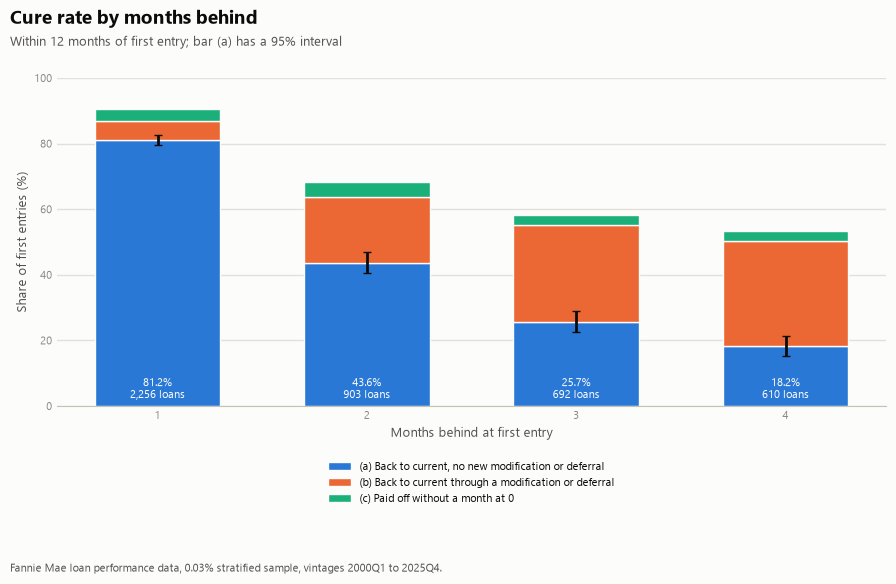

**Result (0.03% stratified sample).** Back to current within 12 months without a new modification or deferral: 1 month(s) behind 81.2% (79.5% to 82.7%) of 2,256 loans; 2 month(s) behind 43.6% (40.4% to 46.9%) of 903 loans; 3 month(s) behind 25.7% (22.6% to 29.1%) of 692 loans; 4 month(s) behind 18.2% (15.3% to 21.5%) of 610 loans. Through a modification or deferral: 1: 5.6%, 2: 20.2%, 3: 29.3%, 4: 32.0%. Paid off without a month at 0: 1: 3.8%, 2: 4.7%, 3: 3.3%, 4: 3.1%. Step in the headline rate from one depth to the next: 1 to 2 months -37.5 points, 2 to 3 months -17.9 points, 3 to 4 months -7.5 points. The headline rate falls with depth. This describes cure behaviour only. It does not set a default line.

In [46]:
# Cure rates by the number of months behind at first entry, split three ways.
cure = q(f"""
    WITH f AS (SELECT loan_id, dm AS m, min(rp) AS first_rp FROM subset_months WHERE dm BETWEEN 1 AND 4 GROUP BY 1, 2),
    e AS (SELECT f.loan_id, f.m, f.first_rp, CAST(f.first_rp + INTERVAL 12 MONTH AS DATE) AS cap, s.modflag AS entry_mod
          FROM f JOIN subset_months s ON s.loan_id = f.loan_id AND s.rp = f.first_rp
          WHERE CAST(f.first_rp + INTERVAL 12 MONTH AS DATE) <= DATE '{DATA_END}'),
    c AS (SELECT e.loan_id, e.m, e.first_rp, e.cap, e.entry_mod, min(s.rp) AS cure_rp
          FROM e LEFT JOIN subset_months s ON s.loan_id = e.loan_id AND s.rp > e.first_rp AND s.rp <= e.cap AND s.dm = 0
          GROUP BY ALL),
    d AS (SELECT c.*,
                 (c.cure_rp IS NOT NULL AND (
                    EXISTS (SELECT 1 FROM subset_months x WHERE x.loan_id = c.loan_id AND x.rp = c.cure_rp AND x.modflag = 'Y' AND c.entry_mod IS DISTINCT FROM 'Y')
                    OR EXISTS (SELECT 1 FROM subset_months x WHERE x.loan_id = c.loan_id AND x.rp >= c.first_rp AND x.rp <= c.cure_rp AND x.defer IN ('P', 'C', 'D')))) AS through_relief,
                 (c.cure_rp IS NULL AND EXISTS (SELECT 1 FROM subset_months x WHERE x.loan_id = c.loan_id AND x.rp > c.first_rp AND x.rp <= c.cap AND x.zb = '01')) AS paid_off
          FROM c)
    SELECT m AS months_behind, count(*) AS entries,
           count(*) FILTER (WHERE cure_rp IS NOT NULL AND NOT through_relief) AS cured_clean,
           count(*) FILTER (WHERE through_relief) AS cured_through_modification_or_deferral,
           count(*) FILTER (WHERE paid_off) AS paid_off_without_cure
    FROM d GROUP BY 1 ORDER BY 1""")
for col, nm in (("cured_clean", "clean"), ("cured_through_modification_or_deferral", "through"), ("paid_off_without_cure", "paid_off")):
    cure[f"{nm}_pct"] = [100 * wilson(k_, t_)[0] for k_, t_ in zip(cure[col], cure["entries"])]
    cure[f"{nm}_ci_low_pct"] = [100 * wilson(k_, t_)[1] for k_, t_ in zip(cure[col], cure["entries"])]
    cure[f"{nm}_ci_high_pct"] = [100 * wilson(k_, t_)[2] for k_, t_ in zip(cure[col], cure["entries"])]
save_table(cure, "eda_07_cure_rates")
cure_falls = bool(len(cure) > 1 and cure["clean_pct"].is_monotonic_decreasing)
if len(cure):
    fig, ax = plt.subplots(figsize=(9, 5.8))
    x = cure["months_behind"].to_numpy()
    ax.bar(x, cure["clean_pct"], width=0.6, color=BLUE, edgecolor=BG, linewidth=1, label="(a) Back to current, no new modification or deferral")
    ax.bar(x, cure["through_pct"], bottom=cure["clean_pct"], width=0.6, color=ORANGE, edgecolor=BG, linewidth=1, label="(b) Back to current through a modification or deferral")
    ax.bar(x, cure["paid_off_pct"], bottom=cure["clean_pct"] + cure["through_pct"], width=0.6, color=PALETTE[2], edgecolor=BG, linewidth=1, label="(c) Paid off without a month at 0")
    ax.errorbar(x, cure["clean_pct"], yerr=[cure["clean_pct"] - cure["clean_ci_low_pct"], cure["clean_ci_high_pct"] - cure["clean_pct"]], fmt="none", ecolor=INK, capsize=3)
    for m_, v_, e_ in zip(x, cure["clean_pct"], cure["entries"]):
        ax.text(m_, 1.5, f"{v_:.1f}%\n{int(e_):,} loans", ha="center", va="bottom", fontsize=8, color="white")
    ax.set_xticks(x)
    ax.set_xlabel("Months behind at first entry")
    ax.set_ylabel("Share of first entries (%)")
    ax.set_ylim(0, 100)
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1)
    style_axes(ax, grid="y")
    save_chart(fig, "eda_07c_cure_rates", "Cure rate by months behind", "Within 12 months of first entry; bar (a) has a 95% interval", subset=True)
    steps_ = np.diff(cure["clean_pct"].to_numpy())
    say(f"**Result {SUBSET_TAG}.** Back to current within 12 months without a new modification or deferral: " + "; ".join(f"{int(r['months_behind'])} month(s) behind {fmt_ci(r['cured_clean'], r['entries'], 1)} of {n(r['entries'])} loans" for _, r in cure.iterrows())
        + ". Through a modification or deferral: " + ", ".join(f"{int(r['months_behind'])}: {r['through_pct']:.1f}%" for _, r in cure.iterrows())
        + ". Paid off without a month at 0: " + ", ".join(f"{int(r['months_behind'])}: {r['paid_off_pct']:.1f}%" for _, r in cure.iterrows())
        + ". Step in the headline rate from one depth to the next: " + ", ".join(f"{int(a_)} to {int(b_)} months {d_:+.1f} points" for a_, b_, d_ in zip(cure['months_behind'][:-1], cure['months_behind'][1:], steps_))
        + ". The headline rate " + ("falls with depth." if cure_falls else "does not fall with depth at every step.") + " This describes cure behaviour only. It does not set a default line.")
else:
    say("**Result.** No loan has 12 months of history after entering arrears inside the data.")

### 07.4 Exit codes

**Why:** How a loan leaves the pool tells whether it was paid off, lost or taken out for another reason.

**How:** Count the exit rows (the row with a zero balance code) by code from the monthly scan (scan 2): all 8 kinds, plus any other code.

**Answers:** How do loans leave the pool?

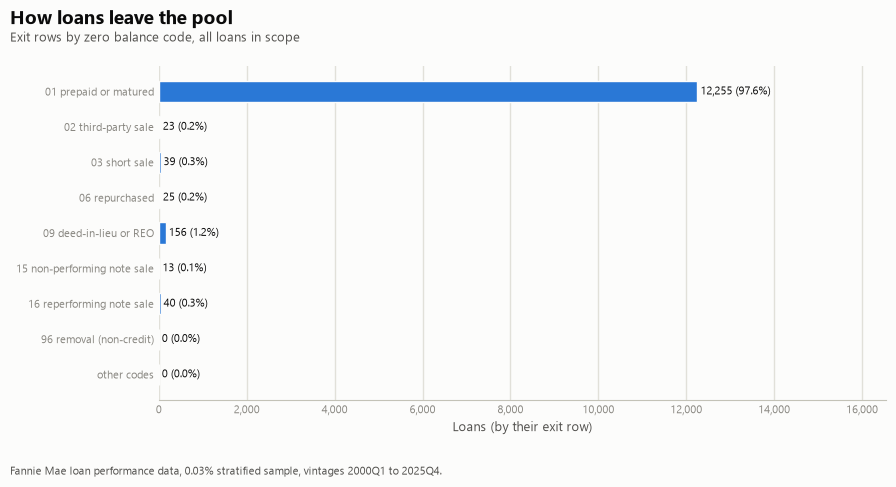

**Result.** 12,551 loans have an exit row: 97.6% paid off or matured (01) and 231 (1.84%) left by a credit exit (02, 03, 09, 15).

In [47]:
# Exit rows by zero balance code (from scan 2).
ex = pd.DataFrame([{"code": c, "reason": lab, "loans": int(by_month[f"exit_{c}"].sum())} for c, lab in EXIT_LABELS.items()]
                  + [{"code": "other", "reason": "other codes", "loans": int(by_month["exit_other"].sum())}])
ex["pct_of_exits"] = 100.0 * ex["loans"] / max(ex["loans"].sum(), 1)
save_table(ex, "eda_07_exit_codes")
fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(ex))
ax.barh(y, ex["loans"], height=0.6, color=BLUE, edgecolor=BG, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels([r if c == "other" else f"{c} {r}" for c, r in zip(ex["code"], ex["reason"])])
ax.invert_yaxis()
for yi, v, s in zip(y, ex["loans"], ex["pct_of_exits"]):
    ax.text(v, yi, f" {int(v):,} ({s:.1f}%)", va="center", ha="left", fontsize=8)
ax.set_xlim(0, max(ex["loans"].max(), 1) * 1.35)
ax.set_xlabel("Loans (by their exit row)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
style_axes(ax, grid="x")
save_chart(fig, "eda_07d_exit_codes", "How loans leave the pool", "Exit rows by zero balance code, all loans in scope")
credit_exits_n = int(ex[ex["code"].isin(CREDIT_EXIT_CODES)]["loans"].sum())
say(f"**Result.** {n(ex['loans'].sum())} loans have an exit row: {pct(ex.loc[ex['code'] == '01', 'pct_of_exits'].iloc[0])} paid off or matured (01) and "
    f"{n(credit_exits_n)} ({pct(100 * credit_exits_n / max(ex['loans'].sum(), 1), 2)}) left by a credit exit (02, 03, 09, 15).")

### 07.5 FICO x LTV grid

**Why:** Credit score and LTV are the two main origination risk fields. Together they show where the risk sits.

**How:** Group bad and good loans into 6 credit score bands and 6 LTV bands and work out the provisional bad rate by count in each cell, with a Wilson 95% interval. Cells with fewer than `MIN_CELL` outcome loans are left blank.

**Answers:** How does the provisional bad rate vary across credit score and LTV?

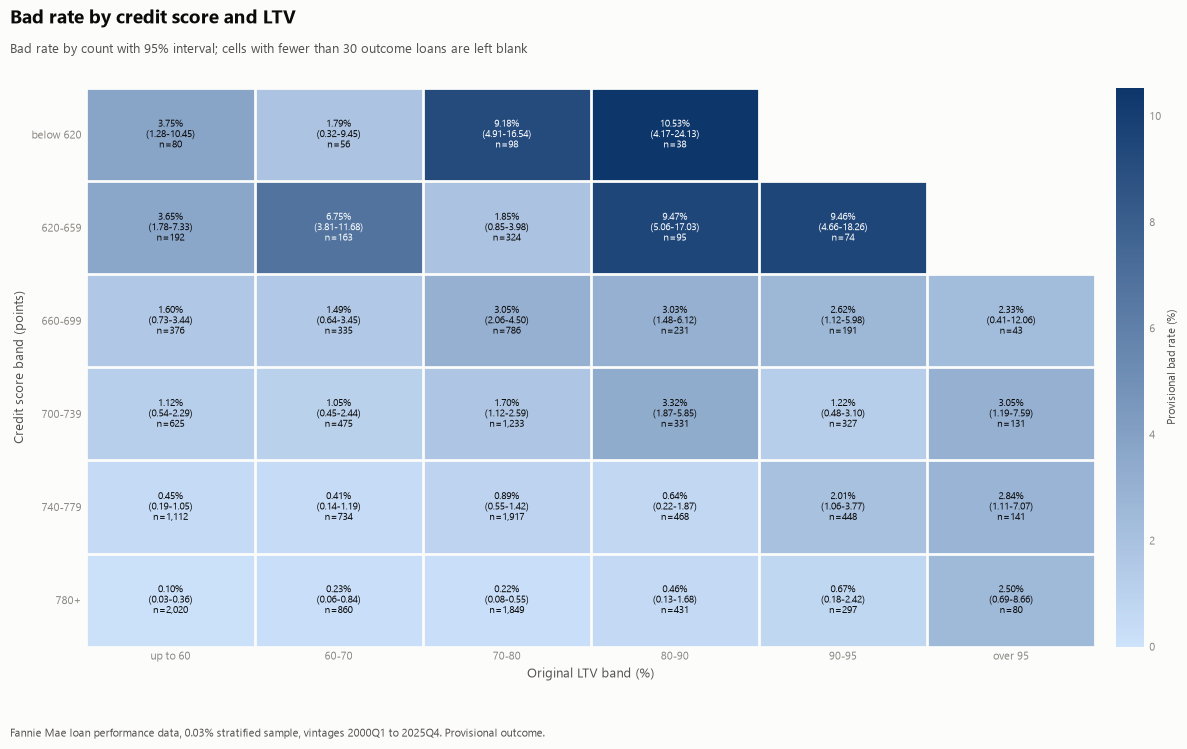

**Result.** 33 of 36 cells have 30 or more outcome loans. The bad rate runs from 0.10% (780+ points, LTV up to 60) to 10.53% (below 620 points, LTV 80-90), a ratio of 106.3 to 1.

In [48]:
# Provisional bad rate by credit score band and LTV band.
g = q(f"""SELECT {score_case} AS s, {ltv_case} AS l, {OUT_AGG}
          FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good') AND credit_score IS NOT NULL AND orig_ltv IS NOT NULL GROUP BY 1, 2""")
g = rate_by_count_and_balance(g)
rate = np.full((6, 6), np.nan)
cnt = np.zeros((6, 6), dtype=int)
ci_txt = [["" for _ in range(6)] for _ in range(6)]
for _, r in g.iterrows():
    i, j = int(r["s"]), int(r["l"])
    cnt[i, j] = r["outcome_loans"]
    if r["outcome_loans"] >= MIN_CELL:
        rate[i, j] = r["bad_rate_count_pct"]
        ci_txt[i][j] = f"{r['bad_rate_count_pct']:.2f}%\n({r['ci_low_pct']:.2f}-{r['ci_high_pct']:.2f})\nn={int(r['outcome_loans']):,}"
grid = g.assign(credit_score_band=[SCORE_BANDS[int(i)] for i in g["s"]], ltv_band=[LTV_BANDS[int(j)] for j in g["l"]])
grid.loc[grid["outcome_loans"] < MIN_CELL, ["bad_rate_count_pct", "ci_low_pct", "ci_high_pct", "bad_rate_balance_pct"]] = np.nan
save_table(grid[["credit_score_band", "ltv_band", "outcome_loans", "bad", "bad_rate_count_pct", "ci_low_pct", "ci_high_pct", "bad_rate_balance_pct"]], "eda_07_fico_ltv_grid")
fig, ax = plt.subplots(figsize=(12, 7.5))
vmax = np.nanmax(rate) if not np.all(np.isnan(rate)) else 1
draw_heatmap(ax, rate, SCORE_BANDS, LTV_BANDS, ONE_HUE, 0, vmax, cell_text=ci_txt, bar_label="Provisional bad rate (%)", fontsize=7)
ax.set_xlabel("Original LTV band (%)")
ax.set_ylabel("Credit score band (points)")
save_chart(fig, "eda_07e_bad_rate_fico_by_ltv", "Bad rate by credit score and LTV", f"Bad rate by count with 95% interval; cells with fewer than {MIN_CELL:,} outcome loans are left blank", provisional=True)
shown = int(np.sum(~np.isnan(rate)))
if shown:
    lo_i, hi_i = np.unravel_index(np.nanargmin(rate), rate.shape), np.unravel_index(np.nanargmax(rate), rate.shape)
    say(f"**Result.** {shown} of 36 cells have {MIN_CELL:,} or more outcome loans. The bad rate runs from {rate[lo_i]:.2f}% ({SCORE_BANDS[lo_i[0]]} points, LTV {LTV_BANDS[lo_i[1]]}) "
        f"to {rate[hi_i]:.2f}% ({SCORE_BANDS[hi_i[0]]} points, LTV {LTV_BANDS[hi_i[1]]}), a ratio of {rate[hi_i] / rate[lo_i]:.1f} to 1.")
else:
    say(f"**Result.** No cell has {MIN_CELL:,} outcome loans.")

### 07.6 Occupancy x LTV

**Why:** How the book is spread across occupancy and LTV is useful context for the capital work. This is a description only; risk weights are Module 6.

**How:** Count loans and original balance in each occupancy and LTV band (all loans in scope, whatever the outcome). No risk weights are applied.

**Answers:** How are loans and balance spread across occupancy and LTV?

In [49]:
# Loans and original balance by occupancy and LTV band (description only).
ob = q(f"""SELECT coalesce(occupancy, 'blank') AS occupancy, {ltv_case} AS l, count(*) AS loans, CAST(sum(orig_upb) AS DOUBLE) AS balance
           FROM {LOANS} WHERE orig_ltv IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2""")
ob["ltv_band"] = [LTV_BANDS[int(i)] for i in ob["l"]]
ob["occupancy_name"] = [CODE_LABELS["occupancy"].get(o, o) for o in ob["occupancy"]]
ob["pct_of_balance"] = 100.0 * ob["balance"] / ob["balance"].sum()
save_table(ob[["occupancy", "occupancy_name", "ltv_band", "loans", "balance", "pct_of_balance"]], "eda_07_occupancy_by_ltv")
big_ob = ob.sort_values("balance", ascending=False).iloc[0]
say(f"**Result.** The largest cell is {big_ob['occupancy_name']} loans with LTV {big_ob['ltv_band']}: {n(big_ob['loans'])} loans, {pct(big_ob['pct_of_balance'])} of original balance. "
    + "Share of balance by occupancy: " + ", ".join(f"{k} {pct(v)}" for k, v in ob.groupby('occupancy_name')['pct_of_balance'].sum().sort_values(ascending=False).items()) + ".")

**Result.** The largest cell is owner-occupied loans with LTV 70-80: 5,521 loans, 33.4% of original balance. Share of balance by occupancy: owner-occupied 91.1%, investor 5.5%, second home 3.5%.

In [50]:
say("## Section 07 - What this shows, and which later module uses it")
say(f"The provisional bad rate is {fmt_ci(bad_n, bad_n + good_n)}; {pct(100 * (OUTCOME_N['excluded'] + OUTCOME_N['not yet observed']) / LOANS_N)} of loans are excluded or not yet observed, "
    f"so the rate rests on {n(bad_n + good_n)} loans. Bad is made mostly of {trig.idxmax()} ({pct(100 * trig.max() / max(trig.sum(), 1))}). "
    + ("The cure rate (without a new modification or deferral) falls with the months behind. " if cure_falls else "The cure rate does not fall with the months behind at every step. ")
    + "Cure rates describe behaviour and do not set a default line. Module 2 (`02_default_engine.py` and `03_roll_rates.py`) sets the default definition and does not rely on this. The grid shows where risk sits across credit score and LTV; Module 3 uses it to check that a scorecard ranks risk in the same order.")

## Section 07 - What this shows, and which later module uses it

The provisional bad rate is 1.29% (1.13% to 1.47%); 3.6% of loans are excluded or not yet observed, so the rate rests on 16,661 loans. Bad is made mostly of 90+ days past due (99.5%). The cure rate (without a new modification or deferral) falls with the months behind. Cure rates describe behaviour and do not set a default line. Module 2 (`02_default_engine.py` and `03_roll_rates.py`) sets the default definition and does not rely on this. The grid shows where risk sits across credit score and LTV; Module 3 uses it to check that a scorecard ranks risk in the same order.

# Section 08 - Defaults and prepayments together

**Answers:** How fast do loans default, and how fast do they repay early, by era? (sample / full subset)

### 08.1 Cumulative default and prepayment curves

**Why:** A loan that repays early can no longer default. Looking at defaults and prepayments side by side, by months on book, shows how many loans leave each way and how many are still open.

**How:** For each era (origination year), and for each month on book from the first payment date, take the loans that have been on book that long inside the data. Cumulative default share = loans with a bad trigger by that month (any month of the loan's life, same triggers as the outcome). Cumulative prepaid share = loans that paid off (code 01) with no bad trigger before. The rest are still open, or left by another route. A loan joins the base only from its first observed month on book (loans that join the data late are not counted before they appear). Curves mix loan age with calendar events (such as 2020), so a bend in a curve can be a calendar effect. Prepaid includes loans that matured. Curves stop where fewer than half of the era's loans (or fewer than `MIN_CELL`) have been on book that long, because the mix of loans changes after that point.

**Answers:** By months on book, what share of each era has defaulted, prepaid or is still open?

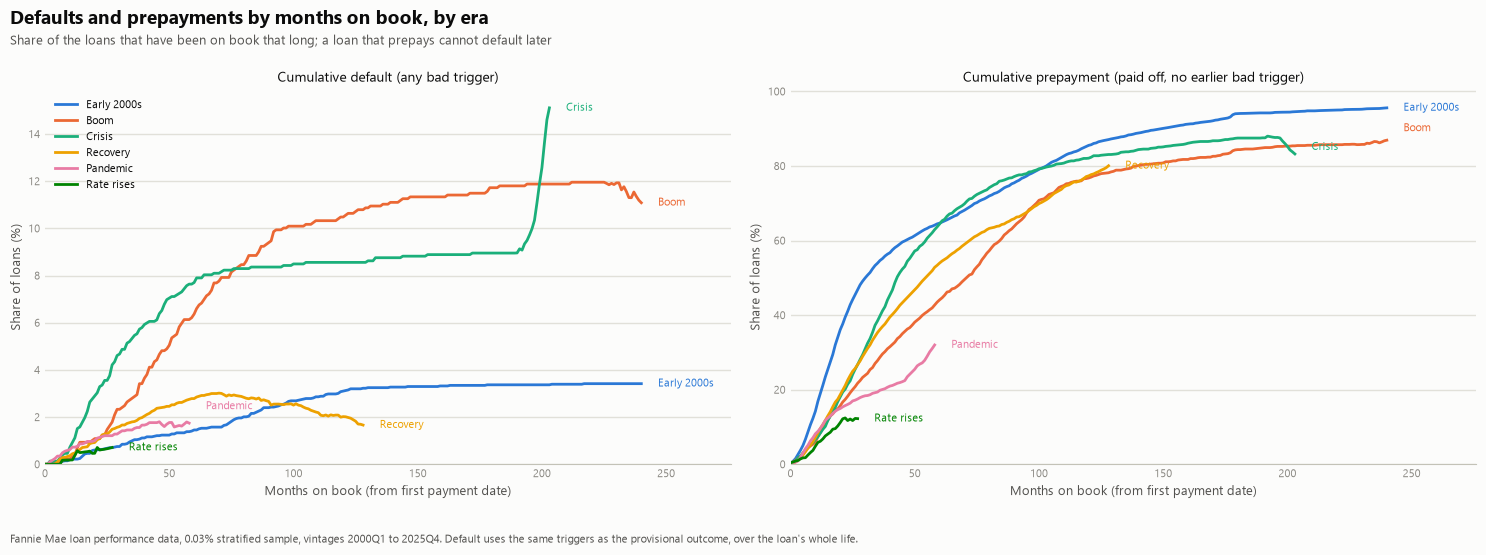

Of 12,255 code 01 exits, 0.0% are within 3 months of maturity, so "prepaid" includes matured loans.

**Result (0.03% stratified sample).** At the end of each curve: Early 2000s: 3.4% defaulted, 95.6% prepaid, 1.0% open after 240 months; Boom: 11.1% defaulted, 86.9% prepaid, 2.0% open after 240 months; Crisis: 15.1% defaulted, 83.2% prepaid, 1.7% open after 203 months; Recovery: 1.7% defaulted, 80.1% prepaid, 18.3% open after 128 months; Pandemic: 1.7% defaulted, 32.0% prepaid, 66.3% open after 58 months; Rate rises: 0.7% defaulted, 12.2% prepaid, 87.1% open after 27 months.

In [51]:
# Cumulative default and prepayment curves by era, by months on book.
hh = q(f"""SELECT era, datediff('month', first_payment_date, DATE '{DATA_END}') AS max_mob, datediff('month', first_payment_date, first_month) AS first_mob,
                  datediff('month', first_payment_date, first_bad_month) AS bad_mob,
                  CASE WHEN first_bad_month IS NULL THEN datediff('month', first_payment_date, prepaid_month) END AS prep_mob,
                  count(*) AS loans
           FROM subset_history WHERE first_payment_date IS NOT NULL AND n_rows IS NOT NULL GROUP BY 1, 2, 3, 4, 5""")
MAXM = 240
rows = []
for e in ERA_NAMES:
    s = hh[hh["era"] == e]
    if s.empty:
        continue
    era_total = s["loans"].sum()
    fm = s["first_mob"].to_numpy()
    mx, bd, pp, ln = s["max_mob"].to_numpy(), s["bad_mob"].to_numpy(dtype=float), s["prep_mob"].to_numpy(dtype=float), s["loans"].to_numpy()
    for m_ in range(MAXM + 1):
        at_risk = ln[(fm <= m_) & (mx >= m_)].sum()
        if at_risk < max(MIN_CELL, 0.5 * era_total):
            break
        d_ = ln[(fm <= m_) & (mx >= m_) & (bd <= m_)].sum()
        p_ = ln[(fm <= m_) & (mx >= m_) & (pp <= m_)].sum()
        rows.append({"era": e, "months_on_book": m_, "loans_on_book": int(at_risk), "cum_default_pct": 100.0 * d_ / at_risk, "cum_prepaid_pct": 100.0 * p_ / at_risk,
                     "open_pct": 100.0 * (at_risk - d_ - p_) / at_risk})
curves = pd.DataFrame(rows)
save_table(curves, "eda_08_default_prepay_curves")
if len(curves):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, col, ttl in ((a1, "cum_default_pct", "Cumulative default (any bad trigger)"), (a2, "cum_prepaid_pct", "Cumulative prepayment (paid off, no earlier bad trigger)")):
        ends = []
        for e in ERA_NAMES:
            c = curves[curves["era"] == e]
            if c.empty:
                continue
            ax.plot(c["months_on_book"], c[col], color=ERA_COLOR[e], label=e)
            ends.append((c["months_on_book"].iloc[-1], c[col].iloc[-1], e, ERA_COLOR[e]))
        ax.set_xlabel("Months on book (from first payment date)")
        ax.set_ylabel("Share of loans (%)")
        ax.set_title(ttl, fontsize=10)
        ax.set_ylim(bottom=0)
        ax.set_xlim(0, curves["months_on_book"].max() * 1.15)
        style_axes(ax, grid="y")
        label_ends(ax, ends)
    a1.legend(frameon=False, fontsize=8, loc="upper left")
    save_chart(fig, "eda_08a_default_prepay_curves", "Defaults and prepayments by months on book, by era",
               "Share of the loans that have been on book that long; a loan that prepays cannot default later", provisional=False, subset=True,
               note="Default uses the same triggers as the provisional outcome, over the loan's whole life.")
    last_pt = curves.groupby("era").tail(1).set_index("era")
    mat = q(f"SELECT count(*) AS exits, count(*) FILTER (WHERE maturity_date IS NOT NULL AND abs(datediff('month', zero_balance_date, maturity_date)) <= 3) AS near FROM {SUBSET_MONTHLY} WHERE zero_balance_code = '01'").iloc[0]
    MAT_SHARE = 100.0 * mat["near"] / max(mat["exits"], 1)
    say(f"Of {n(mat['exits'])} code 01 exits, {pct(MAT_SHARE)} are within 3 months of maturity, so \"prepaid\" includes matured loans.")
    say(f"**Result {SUBSET_TAG}.** At the end of each curve: " + "; ".join(f"{e}: {r['cum_default_pct']:.1f}% defaulted, {r['cum_prepaid_pct']:.1f}% prepaid, {r['open_pct']:.1f}% open after {int(r['months_on_book'])} months" for e, r in last_pt.loc[[e for e in ERA_NAMES if e in last_pt.index]].iterrows()) + ".")
else:
    say(f"**Result.** No era has {MIN_CELL:,} loans in the subset.")

### 08.2 Prepayment speed: SMM and CPR

**Why:** Prepayment speed is quoted as the single monthly mortality rate (SMM) and its yearly equivalent, the conditional prepayment rate (CPR). They show how fast the book repays early in different rate environments.

**How:** By calendar month and era: SMM = loans that prepaid in the month / loans active at the start of the month (count based, not balance based). A loan is active at the start of a month if it had a row with no exit code in the month before. CPR = 1 - (1 - SMM)^12. Months with fewer than `MIN_CELL` active loans are left out. The chart shows a 3-month pooled rate (prepaid over 3 months / active over 3 months), because single months are noisy. The yearly figure pools the months of the year.

**Answers:** How fast do loans repay early, by era and over time?

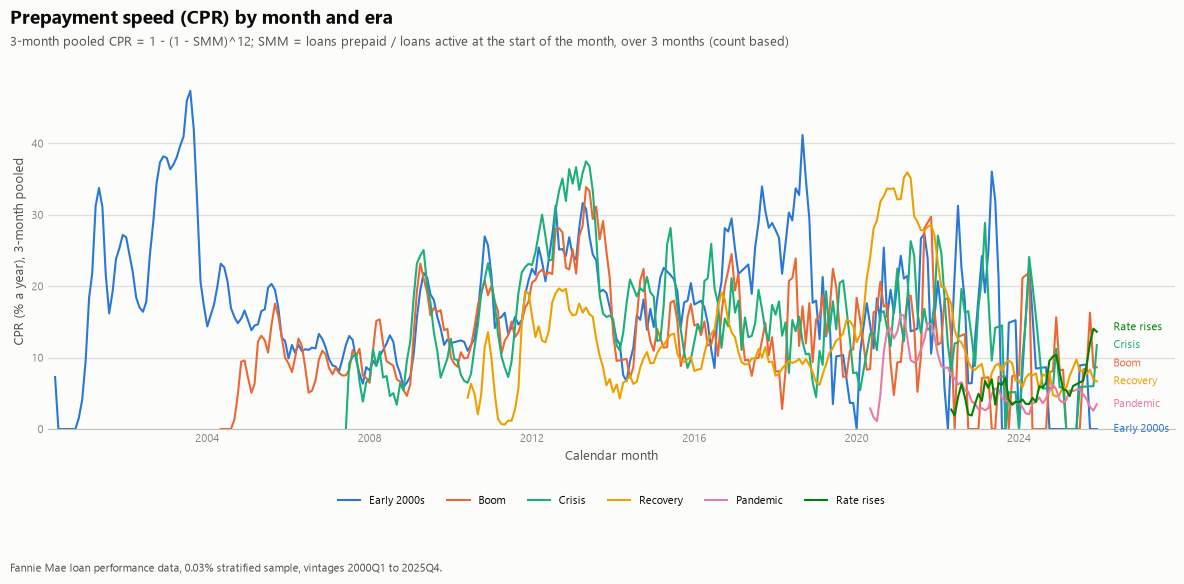

**Result (0.03% stratified sample).** Average CPR by era: Early 2000s 19.0%, Boom 13.2%, Crisis 17.1%, Recovery 13.9%, Pandemic 6.2%, Rate rises 6.8%. The fastest 3-month period ended August 2003 in the Early 2000s era (47.4% a year).

In [52]:
# SMM and CPR by calendar month and era (count based).
sm = q("""SELECT m.rp, h.era, count(*) FILTER (WHERE m.zb = '01') AS prepaid, count(*) FILTER (WHERE m.zb IS NULL) AS active
          FROM subset_months m JOIN subset_history h ON h.loan_id = m.loan_id GROUP BY 1, 2""")
sm["rp"] = pd.to_datetime(sm["rp"])
out_rows = []
for e in ERA_NAMES:
    s = sm[sm["era"] == e].set_index("rp").sort_index()
    if s.empty:
        continue
    full = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    s = s.reindex(full).fillna(0)
    s["active_start"] = s["active"].shift(1)
    s = s.dropna(subset=["active_start"])
    s["valid"] = s["active_start"] >= MIN_CELL
    s["smm"] = s["prepaid"] / s["active_start"]
    s["cpr"] = 1 - (1 - s["smm"]) ** 12
    p_, a_ = s["prepaid"].where(s["valid"]), s["active_start"].where(s["valid"])
    s["cpr_3m"] = 1 - (1 - p_.rolling(3, min_periods=3).sum() / a_.rolling(3, min_periods=3).sum()) ** 12
    s["era"] = e
    out_rows.append(s.reset_index().rename(columns={"index": "month"}))
speed_all = pd.concat(out_rows, ignore_index=True) if out_rows else pd.DataFrame()
speed = speed_all[speed_all["valid"]] if len(speed_all) else speed_all
if len(speed):
    save_table(speed[["month", "era", "prepaid", "active_start", "smm", "cpr", "cpr_3m"]].assign(month=speed["month"].dt.strftime("%Y-%m")), "eda_08_prepayment_speed_monthly")
    yearly = speed.assign(year=speed["month"].dt.year).groupby(["era", "year"]).agg(prepaid=("prepaid", "sum"), active_start=("active_start", "sum")).reset_index()
    yearly["smm"] = yearly["prepaid"] / yearly["active_start"]
    yearly["cpr"] = 1 - (1 - yearly["smm"]) ** 12
    save_table(yearly, "eda_08_prepayment_speed_yearly")
    avg = speed.groupby("era").agg(prepaid=("prepaid", "sum"), active_start=("active_start", "sum")).reset_index()
    avg["average_smm"] = avg["prepaid"] / avg["active_start"]
    avg["average_cpr"] = 1 - (1 - avg["average_smm"]) ** 12
    avg["order"] = avg["era"].map({e: i for i, e in enumerate(ERA_NAMES)})
    avg = avg.sort_values("order").drop(columns="order")
    save_table(avg, "eda_08_average_cpr_by_era")
    fig, ax = plt.subplots(figsize=(12, 5.8))
    ends = []
    for e in ERA_NAMES:
        c = speed_all[speed_all["era"] == e]
        if c["cpr_3m"].isna().all():
            continue
        ax.plot(c["month"], 100 * c["cpr_3m"], color=ERA_COLOR[e], linewidth=1.5, label=e)
        ok = c.dropna(subset=["cpr_3m"])
        if len(ok):
            ends.append((ok["month"].iloc[-1], 100 * ok["cpr_3m"].iloc[-1], e, ERA_COLOR[e]))
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("CPR (% a year), 3-month pooled")
    style_axes(ax, grid="y")
    ax.set_xlim(speed_all["month"].min(), speed_all["month"].max() + pd.Timedelta(days=700))
    label_ends(ax, ends)
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=max(len(ends), 1))
    save_chart(fig, "eda_08b_cpr_by_month", "Prepayment speed (CPR) by month and era", "3-month pooled CPR = 1 - (1 - SMM)^12; SMM = loans prepaid / loans active at the start of the month, over 3 months (count based)", subset=True)
    pkd = speed.dropna(subset=["cpr_3m"])
    pk = pkd.loc[pkd["cpr_3m"].idxmax()]
    say(f"**Result {SUBSET_TAG}.** Average CPR by era: " + ", ".join(f"{r['era']} {100 * r['average_cpr']:.1f}%" for _, r in avg.iterrows())
        + f". The fastest 3-month period ended {pk['month']:%B %Y} in the {pk['era']} era ({100 * pk['cpr_3m']:.1f}% a year).")
else:
    avg = pd.DataFrame(columns=["era", "average_cpr"])
    pk = None
    say(f"**Result.** No month has {MIN_CELL:,} active loans in any era, so SMM and CPR are not shown.")

In [53]:
say("## Section 08 - What this shows, and which later module uses it")
say("Default and prepayment are two exits that compete: the curves show, by era, how many loans leave each way. "
    + (f"Average prepayment speed ranges from {100 * avg['average_cpr'].min():.1f}% to {100 * avg['average_cpr'].max():.1f}% a year across eras, so a model that ignored prepayment would overstate the loans still at risk. " if len(avg) else "")
    + "Module 2 (`04_vintage_curves.py`) builds the vintage default, prepayment and competing-risk curves on the signed-off default definition; "
      "Module 5 (`05_ifrs9_ecl`) uses prepayment speed to project balances.")

## Section 08 - What this shows, and which later module uses it

Default and prepayment are two exits that compete: the curves show, by era, how many loans leave each way. Average prepayment speed ranges from 6.2% to 19.0% a year across eras, so a model that ignored prepayment would overstate the loans still at risk. Module 2 (`04_vintage_curves.py`) builds the vintage default, prepayment and competing-risk curves on the signed-off default definition; Module 5 (`05_ifrs9_ecl`) uses prepayment speed to project balances.

# Section 09 - Payment deferral and forbearance

**Answers:** How did the 2020-2021 relief change delinquency, and what does that mean for the outcome?

### 09.1 Loans under an assistance plan or a payment deferral

**Why:** During COVID many borrowers were given forbearance or a payment deferral. Months under such relief can look current or behind for reasons that are not about credit quality.

**How:** From the monthly scan (scan 2), count loan-months under each borrower assistance plan (F forbearance, T trial period, R repayment plan) and each payment deferral code (P, C, D in the alternative delinquency resolution field), by reporting month. Also count months with a deferral amount above zero.

**Answers:** When did relief peak, and how large was it?

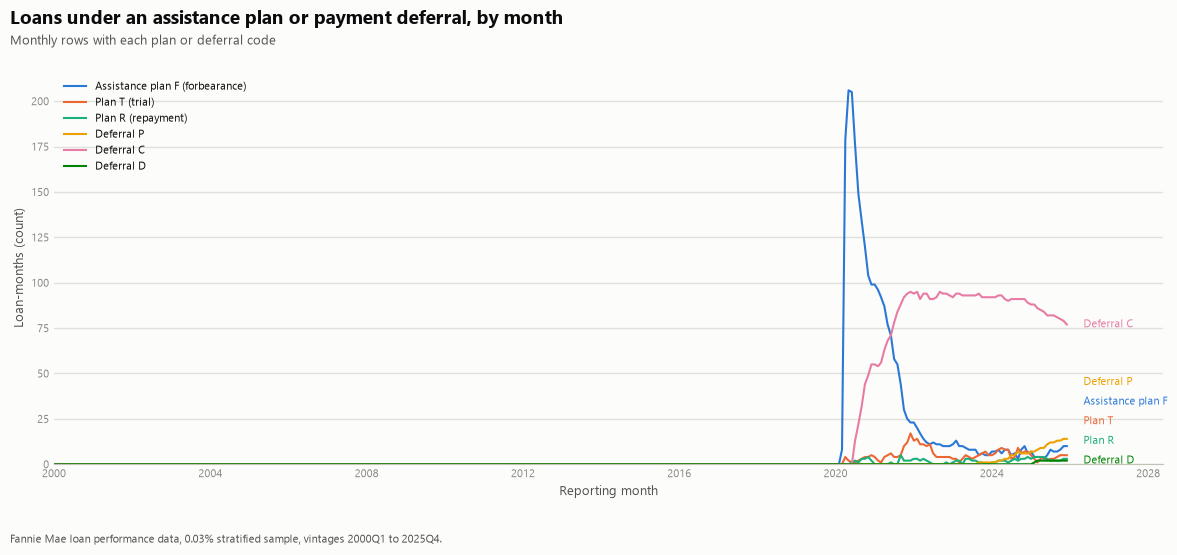

**Result.** 8,681 loan-months (0.87% of all loan-months) are under a plan or deferral code. The peak is May 2020 with 208 loan-months (5.05% of that month's rows). Forbearance (F) accounts for 2,555 loan-months and deferral codes P, C, D for 5,636; months with a deferral amount above zero: 5,635.

In [54]:
# Loan-months under an assistance plan or a payment deferral, by month (from scan 2).
rel = by_month[["reporting_period", "monthly_rows", "plan_F", "plan_T", "plan_R", "defer_P", "defer_C", "defer_D", "deferral_amount_positive"]].copy()
rel["any_relief"] = rel[["plan_F", "plan_T", "plan_R", "defer_P", "defer_C", "defer_D"]].sum(axis=1)
save_table(rel.assign(reporting_period=rel["reporting_period"].dt.strftime("%Y-%m")), "eda_09_relief_by_month")
series = [("plan_F", "Assistance plan F (forbearance)"), ("plan_T", "Plan T (trial)"), ("plan_R", "Plan R (repayment)"),
          ("defer_P", "Deferral P"), ("defer_C", "Deferral C"), ("defer_D", "Deferral D")]
fig, ax = plt.subplots(figsize=(12, 5.5))
ends = []
for (col, lab), colr in zip(series, PALETTE):
    ax.plot(rel["reporting_period"], rel[col], color=colr, label=lab, linewidth=1.5)
    ends.append((rel["reporting_period"].iloc[-1], rel[col].iloc[-1], lab.split(" (")[0], colr))
ax.set_ylim(bottom=0)
ax.set_xlabel("Reporting month")
ax.set_ylabel("Loan-months (count)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
style_axes(ax, grid="y")
ax.set_xlim(rel["reporting_period"].min(), rel["reporting_period"].max() + pd.Timedelta(days=900))
label_ends(ax, ends)
ax.legend(frameon=False, fontsize=8, loc="upper left")
save_chart(fig, "eda_09a_relief_by_month", "Loans under an assistance plan or payment deferral, by month", "Monthly rows with each plan or deferral code")
tot_relief = int(rel["any_relief"].sum())
pkm = rel.loc[rel["any_relief"].idxmax()]
headline["relief_loan_months"] = tot_relief
say(f"**Result.** {n(tot_relief)} loan-months ({pct(100 * tot_relief / MONTHLY_ROWS_BY_MONTH, 2)} of all loan-months) are under a plan or deferral code. "
    + (f"The peak is {pkm['reporting_period']:%B %Y} with {n(pkm['any_relief'])} loan-months ({pct(100 * pkm['any_relief'] / pkm['monthly_rows'], 2)} of that month's rows). " if tot_relief else "")
    + f"Forbearance (F) accounts for {n(rel['plan_F'].sum())} loan-months and deferral codes P, C, D for {n(rel[['defer_P', 'defer_C', 'defer_D']].sum().sum())}; months with a deferral amount above zero: {n(rel['deferral_amount_positive'].sum())}.")

### 09.2 Delinquency during and after forbearance

**Why:** If loans in forbearance are shown as current, or if they fall behind and then cure, the delinquency status during and after relief needs a careful reading before it is used to define default.

**How:** On the active monthly subset, take loans with at least one month under plan F. Count their months behind in the months under F, and in the 6 months after their last month under F.

**Answers:** How does delinquency status behave during and after forbearance?

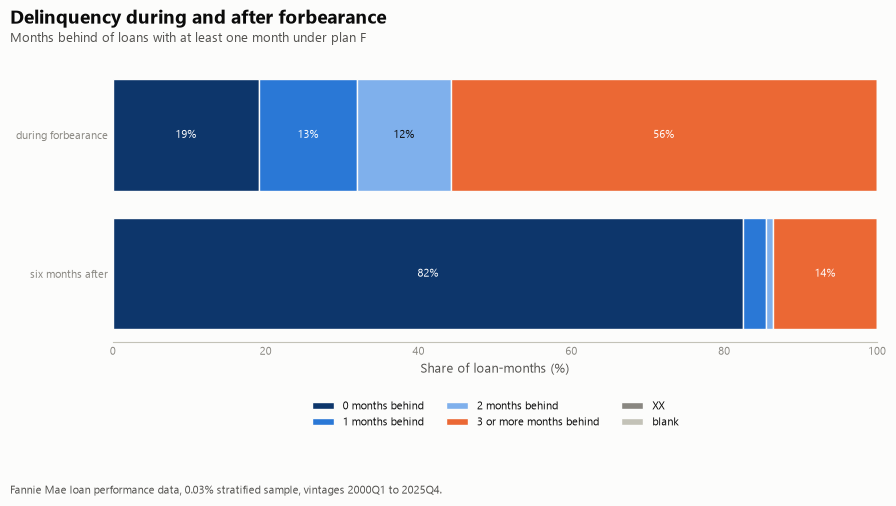

**Result (0.03% stratified sample).** 341 subset loans have a month under plan F. During forbearance 19.1% of their loan-months show current and 55.8% show 3 or more months behind; in the six months after, 82.5% show current and 13.6% 3 or more months behind.

In [55]:
# Delinquency status of loans with plan F, during F and in the 6 months after the last F month.
bucket = "CASE WHEN m.xx THEN 'XX' WHEN m.dm IS NULL THEN 'blank' WHEN m.dm >= 3 THEN '3 or more' ELSE CAST(m.dm AS VARCHAR) END"
da = q(f"""
    WITH f AS (SELECT loan_id, max(rp) AS last_f FROM subset_months WHERE plan = 'F' GROUP BY 1)
    SELECT 'during forbearance' AS period, {bucket} AS months_behind, count(*) AS loan_months
    FROM subset_months m JOIN f ON f.loan_id = m.loan_id WHERE m.plan = 'F' GROUP BY 2
    UNION ALL
    SELECT 'six months after', {bucket}, count(*)
    FROM subset_months m JOIN f ON f.loan_id = m.loan_id
    WHERE m.rp > f.last_f AND m.rp <= CAST(f.last_f + INTERVAL 6 MONTH AS DATE) GROUP BY 2""")
F_LOANS = int(con.execute("SELECT count(DISTINCT loan_id) FROM subset_months WHERE plan = 'F'").fetchone()[0])
ORDER_B = ["0", "1", "2", "3 or more", "XX", "blank"]
if len(da):
    da["pct"] = 100.0 * da["loan_months"] / da.groupby("period")["loan_months"].transform("sum")
    save_table(da.sort_values(["period", "months_behind"]), "eda_09_delinquency_during_after_forbearance")
    pv = da.pivot(index="months_behind", columns="period", values="pct").reindex(ORDER_B).fillna(0)
    fig, ax = plt.subplots(figsize=(9, 5))
    periods = [p_ for p_ in ["during forbearance", "six months after"] if p_ in pv.columns]
    left = np.zeros(len(periods))
    shades = ["#0d366b", "#2a78d6", "#7fb0ec", "#eb6834", "#898781", "#c3c2b7"]
    for b_, colr in zip(ORDER_B, shades):
        vals = np.array([pv.loc[b_, p_] for p_ in periods])
        ax.barh(range(len(periods)), vals, left=left, color=colr, edgecolor=BG, linewidth=1, label=f"{b_} months behind" if b_[0].isdigit() else b_)
        for i_, (v_, l_) in enumerate(zip(vals, left)):
            if v_ >= 4:
                ax.text(l_ + v_ / 2, i_, f"{v_:.0f}%", ha="center", va="center", fontsize=8, color="white" if colr in ("#0d366b", "#2a78d6", "#eb6834", "#898781") else INK)
        left += vals
    ax.set_yticks(range(len(periods)))
    ax.set_yticklabels(periods)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Share of loan-months (%)")
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    style_axes(ax, grid=None)
    save_chart(fig, "eda_09b_delinquency_during_after", "Delinquency during and after forbearance", "Months behind of loans with at least one month under plan F", subset=True)
    dur = da[da["period"] == "during forbearance"].set_index("months_behind")["pct"]
    aft = da[da["period"] == "six months after"].set_index("months_behind")["pct"]
    say(f"**Result {SUBSET_TAG}.** {n(F_LOANS)} subset loans have a month under plan F. During forbearance {pct(dur.get('0', 0))} of their loan-months show current and {pct(dur.get('3 or more', 0))} show 3 or more months behind; "
        f"in the six months after, {pct(aft.get('0', 0))} show current and {pct(aft.get('3 or more', 0))} 3 or more months behind.")
else:
    say("**Result.** No loan in the subset has a month under plan F in this data.")

### 09.3 What happens to the outcome if relief months are left out

**Why:** If months under an assistance plan were ignored, some loans now called bad would not be bad. The size of that change tells Module 2 how much the question matters.

**How:** For every loan, repeat the bad test (3 or more months behind, modification, credit exit) but ignore months where the assistance plan is F, T or R. A loan that was bad only because of such months becomes good if it was still reporting at 24 months or paid off, and excluded otherwise. Compare the counts and the bad rate.

**Answers:** How much does the outcome change if relief months are left out?

In [56]:
# Outcome counts with and without months under an assistance plan (F, T, R).
w = q("""SELECT outcome, bad_without_plan_months AS b2, observed_to_end AS obs, count(*) AS loans, sum(orig_upb) AS bal FROM loan_outcome GROUP BY 1, 2, 3""")
w["outcome_ignoring_plan_months"] = np.where(w["outcome"] != "bad", w["outcome"], np.where(w["b2"], "bad", np.where(w["obs"], "good", "excluded")))
a_ = w.groupby("outcome")["loans"].sum().reindex(OUTCOME_ORDER).fillna(0).astype(int)
b_ = w.groupby("outcome_ignoring_plan_months")["loans"].sum().reindex(OUTCOME_ORDER).fillna(0).astype(int)
cmp_ = pd.DataFrame({"outcome": OUTCOME_ORDER, "loans_as_built": a_.values, "loans_ignoring_plan_months": b_.values})
cmp_["change"] = cmp_["loans_ignoring_plan_months"] - cmp_["loans_as_built"]
rate1, rate2 = 100 * a_["bad"] / (a_["bad"] + a_["good"]), 100 * b_["bad"] / (b_["bad"] + b_["good"])
save_table(cmp_, "eda_09_outcome_without_relief_months")
moved = int(a_["bad"] - b_["bad"])
headline["bad_moved_by_relief"] = moved
say(f"**Result.** Ignoring months under an assistance plan, bad loans fall from {n(a_['bad'])} to {n(b_['bad'])} ({n(moved)} loans, {pct(100 * moved / max(a_['bad'], 1), 2)} of bad loans). "
    f"The bad rate goes from {rate1:.2f}% to {rate2:.2f}%, a gap of {rate2 - rate1:+.2f} percentage points (ratio {rate2 / rate1 if rate1 else float('nan'):.2f}). "
    "This is the size of the open question. Whether relief months count as arrears is decided in Module 2 (`02_default_engine.py`), not here.")

**Result.** Ignoring months under an assistance plan, bad loans fall from 215 to 158 (57 loans, 26.51% of bad loans). The bad rate goes from 1.29% to 0.95%, a gap of -0.34 percentage points (ratio 0.73). This is the size of the open question. Whether relief months count as arrears is decided in Module 2 (`02_default_engine.py`), not here.

In [57]:
say("## Section 09 - What this shows, and which later module uses it")
say(f"Relief peaked in {pkm['reporting_period']:%B %Y} at {n(pkm['any_relief'])} loan-months. "
    f"Leaving relief months out would move {n(moved)} loans out of bad ({rate1:.2f}% to {rate2:.2f}%). "
    "Module 2 (`02_default_engine.py`) owns the decision on how deferrals and forbearance count towards default; this section gives it the size of the question. "
    "The loans are US loans, so US relief programmes apply; see `docs\\departures_from_uk_rules.md` (D-025) for where the US data departs from UK rules.")

## Section 09 - What this shows, and which later module uses it

Relief peaked in May 2020 at 208 loan-months. Leaving relief months out would move 57 loans out of bad (1.29% to 0.95%). Module 2 (`02_default_engine.py`) owns the decision on how deferrals and forbearance count towards default; this section gives it the size of the question. The loans are US loans, so US relief programmes apply; see `docs\departures_from_uk_rules.md` (D-025) for where the US data departs from UK rules.

# Section 10 - Losses on credit exits

**Answers:** How much is lost when a loan ends badly, and how long does it take?

### 10.1 Credit exits and their net loss

**Why:** When a loan leaves by third-party sale, short sale, deed-in-lieu/REO or non-performing note sale, the exit row carries costs and proceeds. They show how much is lost on a loan that ends badly. This is descriptive: it is not a loss given default (LGD) estimate.

**How:** Take every exit row with code 02, 03, 09 or 15. The end date is the zero balance date; for code 09 (REO) it is the disposition date (the sale), and REO with no disposition date is left out and counted. Exits whose end date is in the last 6 months of the data are left out, because proceeds can arrive months after the sale. Blank costs and proceeds count as 0, but exits with every proceeds field blank are counted on their own line and kept out of severity. Net loss = balance at removal + foreclosure costs + preservation and repair costs + asset recovery costs + miscellaneous holding expenses + holding taxes - net sales proceeds - credit enhancement proceeds - repurchase make-whole proceeds - other foreclosure proceeds. Severity = net loss / balance at removal, for balances above zero. Unpaid interest (layout field 85) is not in the data, so severity is understated; it could be estimated later from the last paid date, the current rate and the balance at removal (Module 4).

**Answers:** How many credit exits are there, and how many are usable for severity?

In [58]:
# Credit exits: net loss and severity per exit row (scan 5, part 1).
def coalesced(c):
    return f"coalesce(m.{c}, 0)"


NET_LOSS = ("CAST(" + " + ".join(coalesced(c) for c in ["upb_at_removal", "foreclosure_costs", "preservation_repair_costs", "asset_recovery_costs", "misc_holding_expenses", "holding_taxes"])
            + " - " + " - ".join(coalesced(c) for c in ["net_sales_proceeds", "credit_enhancement_proceeds", "repurchase_make_whole_proceeds", "other_foreclosure_proceeds"]) + " AS DOUBLE)")
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE credit_exits AS
    SELECT m.loan_id, m.zero_balance_code AS code, m.zero_balance_date AS zb_date,
           CASE WHEN m.zero_balance_code = '09' THEN m.disposition_date ELSE m.zero_balance_date END AS end_date,
           CAST(m.upb_at_removal AS DOUBLE) AS upb_removal, {NET_LOSS} AS net_loss,
           (m.net_sales_proceeds IS NULL AND m.credit_enhancement_proceeds IS NULL AND m.repurchase_make_whole_proceeds IS NULL AND m.other_foreclosure_proceeds IS NULL) AS no_proceeds,
           l.property_state, l.orig_ltv, {era_case('l.orig_date')} AS era
    FROM {MONTHLY} m JOIN {LOANS} l ON l.loan_id = m.loan_id
    WHERE m.zero_balance_code IN ({', '.join(f"'{c}'" for c in CREDIT_EXIT_CODES)})""")
CUTOFF = f"CAST(DATE '{DATA_END}' - INTERVAL 6 MONTH AS DATE)"
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE credit_exits_s AS
    SELECT *, CASE WHEN code = '09' AND end_date IS NULL THEN 'reo_no_sale'
                   WHEN end_date IS NULL OR end_date > {CUTOFF} THEN 'too_recent'
                   WHEN upb_removal IS NULL OR upb_removal <= 0 THEN 'no_balance'
                   WHEN no_proceeds THEN 'no_proceeds' ELSE 'used' END AS status
    FROM credit_exits""")
con.execute("CREATE OR REPLACE TEMP TABLE credit_exits_ok AS SELECT *, net_loss / upb_removal AS severity FROM credit_exits_s WHERE status = 'used'")
# Months behind: start of the last unbroken run of 3+ months behind before the exit (scan 5, part 2).
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE exit_arrears AS
    WITH x AS (SELECT m.loan_id, m.reporting_period AS rp, m.delinquency_months AS dm, e.zb_date
               FROM {MONTHLY} m JOIN credit_exits_ok e ON e.loan_id = m.loan_id WHERE m.reporting_period <= e.zb_date),
    lb AS (SELECT loan_id, max(rp) FILTER (WHERE dm < 3) AS last_below FROM x GROUP BY 1)
    SELECT x.loan_id, min(x.rp) FILTER (WHERE x.dm >= 3 AND x.rp > coalesce(lb.last_below, DATE '1900-01-01')) AS run_start
    FROM x JOIN lb ON lb.loan_id = x.loan_id GROUP BY x.loan_id""")
S = q("SELECT status, count(*) AS exits FROM credit_exits_s GROUP BY 1").set_index("status")["exits"]
sg = lambda k: int(S.get(k, 0))
USED, REO_NO_SALE, NO_PROCEEDS = sg("used"), sg("reo_no_sale"), sg("no_proceeds")
exit_counts = pd.DataFrame([("credit exit rows (codes 02, 03, 09, 15)", int(S.sum())), ("left out: REO (09) with no disposition date", REO_NO_SALE),
                            ("left out: end date in the last 6 months of the data (or no end date)", sg("too_recent")),
                            ("left out: balance at removal blank or zero", sg("no_balance")),
                            ("kept out of severity: every proceeds field blank", NO_PROCEEDS), ("exits used for severity", USED)], columns=["item", "exits"])
save_table(exit_counts, "eda_10_exit_counts")
if USED:
    t = q("SELECT sum(net_loss) AS nl, sum(upb_removal) AS ub, median(severity) AS med, quantile_cont(severity, 0.25) AS p25, quantile_cont(severity, 0.75) AS p75 FROM credit_exits_ok").iloc[0]
    SEV_ALL, SEV_MED = 100 * t["nl"] / t["ub"], 100 * t["med"]
    headline.update({"credit_exits_used": USED, "severity_weighted_pct": round(SEV_ALL, 1), "severity_median_pct": round(SEV_MED, 1)})
    say(f"**Result.** {n(S.sum())} credit exit rows. Left out: {n(REO_NO_SALE)} REO with no disposition date, {n(sg('too_recent'))} with an end date in the last 6 months (or none), {n(sg('no_balance'))} with no balance at removal. "
        f"{n(NO_PROCEEDS)} more have every proceeds field blank and are kept out of severity. That leaves {n(USED)} exits. Severity is {SEV_ALL:.1f}% weighted by balance and {SEV_MED:.1f}% at the median "
        f"(middle half of loans from {100 * t['p25']:.1f}% to {100 * t['p75']:.1f}%). Unpaid interest is not in the data, so these figures are understated. "
        "The US data departs from UK rules in several places; see `docs\\departures_from_uk_rules.md`.")
else:
    SEV_ALL = SEV_MED = float("nan")
    say(f"**Result.** {n(S.sum())} credit exit rows, none usable for severity ({n(REO_NO_SALE)} REO with no disposition date, {n(sg('too_recent'))} too recent, {n(sg('no_balance'))} with no balance, {n(NO_PROCEEDS)} with every proceeds field blank).")

**Result.** 231 credit exit rows. Left out: 2 REO with no disposition date, 1 with an end date in the last 6 months (or none), 0 with no balance at removal. 0 more have every proceeds field blank and are kept out of severity. That leaves 228 exits. Severity is 26.2% weighted by balance and 24.7% at the median (middle half of loans from -0.9% to 53.4%). Unpaid interest is not in the data, so these figures are understated. The US data departs from UK rules in several places; see `docs\departures_from_uk_rules.md`.

### 10.2 Severity by era, state and LTV band

**Why:** Severity is expected to be higher for higher-LTV loans and in states where house prices fell. These cuts show whether the data agrees.

**How:** Severity weighted by balance (sum of net loss / sum of balance at removal) and the median severity, by origination era, property state and original LTV band. Groups with fewer than `MIN_CELL` exits are not shown on their own: states are folded into other, and eras and LTV bands are shown as 'fewer than `MIN_CELL`'. With few exits the state table is mostly folded.

**Answers:** Where is the loss on a credit exit highest and lowest?

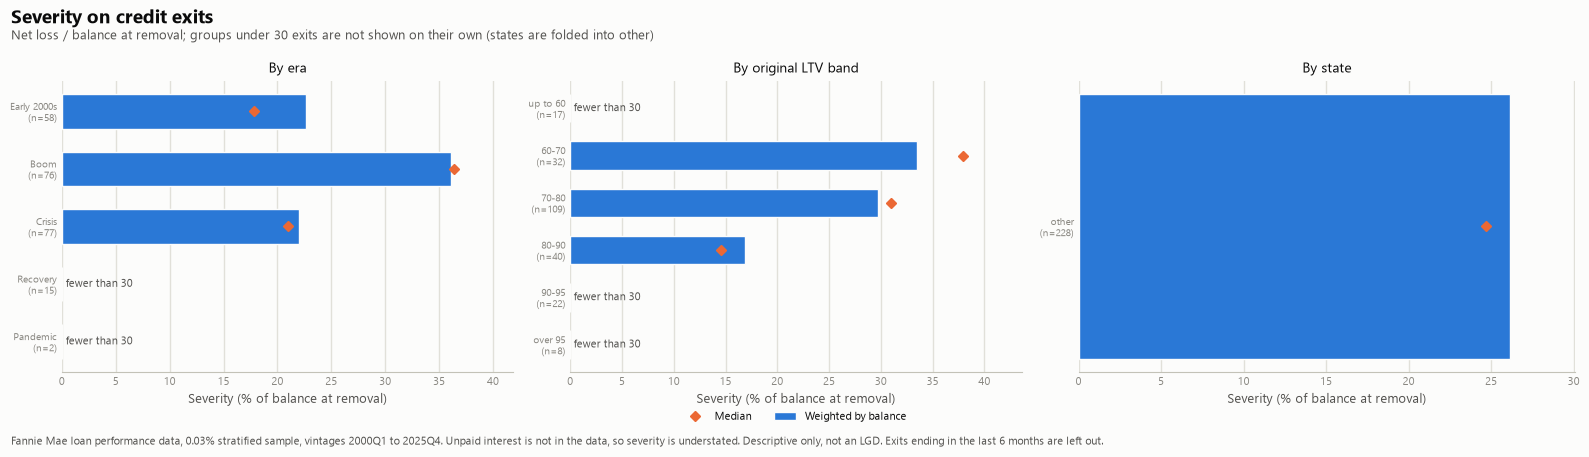

**Result.** Severity by era (weighted): Early 2000s 22.6% (n=58), Boom 36.1% (n=76), Crisis 22.0% (n=77). By LTV band: 60-70 33.5%, 70-80 29.7%, 80-90 16.8%. State table: 0 states have 30 or more exits (the table is mostly folded into other).

In [59]:
# Severity by era, LTV band and state.
def sev_table(key_sql, labels=None, fold=False):
    d = q(f"SELECT {key_sql} AS grp, count(*) AS exits FROM credit_exits_ok GROUP BY 1")
    small = set(d.loc[d["exits"] < MIN_CELL, "grp"])
    if fold and small:
        names = ", ".join("'" + str(s).replace("'", "''") + "'" for s in small)
        key_sql = f"CASE WHEN {key_sql} IN ({names}) THEN 'other' ELSE {key_sql} END"
    d = q(f"""SELECT {key_sql} AS grp, count(*) AS exits, sum(net_loss) AS net_loss, sum(upb_removal) AS balance_at_removal, median(severity) AS med
              FROM credit_exits_ok GROUP BY 1""")
    d["severity_weighted_pct"] = 100 * d["net_loss"] / d["balance_at_removal"]
    d["severity_median_pct"] = 100 * d["med"]
    d["note"] = ""
    if not fold:
        mask = d["exits"] < MIN_CELL
        d.loc[mask, ["severity_weighted_pct", "severity_median_pct"]] = np.nan
        d.loc[mask, "note"] = f"fewer than {MIN_CELL:,} loans"
    return d.drop(columns="med")


if USED:
    by_era_sev = sev_table("era")
    by_era_sev["o"] = by_era_sev["grp"].map({e: i for i, e in enumerate(ERA_NAMES)}).fillna(99)
    by_era_sev = by_era_sev.sort_values("o").drop(columns="o")
    by_ltv_sev = sev_table(f"CASE WHEN orig_ltv IS NULL THEN 'blank' ELSE CASE WHEN {ltv_case} = 0 THEN '{LTV_BANDS[0]}' WHEN {ltv_case} = 1 THEN '{LTV_BANDS[1]}' WHEN {ltv_case} = 2 THEN '{LTV_BANDS[2]}' WHEN {ltv_case} = 3 THEN '{LTV_BANDS[3]}' WHEN {ltv_case} = 4 THEN '{LTV_BANDS[4]}' ELSE '{LTV_BANDS[5]}' END END")
    by_ltv_sev["o"] = by_ltv_sev["grp"].map({b: i for i, b in enumerate(LTV_BANDS)}).fillna(99)
    by_ltv_sev = by_ltv_sev.sort_values("o").drop(columns="o")
    by_state_sev = sev_table("coalesce(property_state, 'blank')", fold=True)
    by_state_sev = pd.concat([by_state_sev[by_state_sev["grp"] != "other"].sort_values("severity_weighted_pct", ascending=False), by_state_sev[by_state_sev["grp"] == "other"]], ignore_index=True)
    for d_, nm, key in ((by_era_sev, "eda_10_severity_by_era", "era"), (by_ltv_sev, "eda_10_severity_by_ltv_band", "ltv_band"), (by_state_sev, "eda_10_severity_by_state", "state")):
        save_table(d_.rename(columns={"grp": key}), nm)
    fig, axes = plt.subplots(1, 3, figsize=(16, max(4.5, 0.3 * len(by_state_sev) + 2)), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    for ax, d_, ttl in ((axes[0], by_era_sev, "By era"), (axes[1], by_ltv_sev, "By original LTV band"), (axes[2], by_state_sev, "By state")):
        d_ = d_.reset_index(drop=True)
        y = np.arange(len(d_))
        top_ = np.nanmax(d_["severity_weighted_pct"].to_numpy(dtype=float)) if d_["severity_weighted_pct"].notna().any() else 10.0
        ax.barh(y, d_["severity_weighted_pct"].fillna(0), height=0.6, color=BLUE, edgecolor=BG, linewidth=1, label="Weighted by balance")
        ax.plot(d_["severity_median_pct"], y, linestyle="none", marker="D", markersize=5, color=ORANGE, label="Median")
        for yi, v_ in zip(y, d_["severity_weighted_pct"]):
            if pd.isna(v_):
                ax.text(0.01 * top_, yi, f"fewer than {MIN_CELL:,}", va="center", ha="left", fontsize=8, color=INK2)
        ax.set_xlim(0, max(top_, d_["severity_median_pct"].max() if d_["severity_median_pct"].notna().any() else 0) * 1.15)
        ax.set_yticks(y)
        ax.set_yticklabels([f"{g_}\n(n={int(e_):,})" if len(d_) <= 8 else f"{g_} ({int(e_):,})" for g_, e_ in zip(d_["grp"], d_["exits"])], fontsize=7.5)
        ax.invert_yaxis()
        ax.set_title(ttl, fontsize=10)
        ax.set_xlabel("Severity (% of balance at removal)")
        style_axes(ax, grid="x")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, frameon=False, fontsize=8, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.045))
    save_chart(fig, "eda_10a_severity", "Severity on credit exits", f"Net loss / balance at removal; groups under {MIN_CELL:,} exits are not shown on their own (states are folded into other)",
               note="Unpaid interest is not in the data, so severity is understated. Descriptive only, not an LGD. Exits ending in the last 6 months are left out.")
    ok_era = by_era_sev.dropna(subset=["severity_weighted_pct"])
    say("**Result.** Severity by era (weighted): " + (", ".join(f"{r['grp']} {r['severity_weighted_pct']:.1f}% (n={int(r['exits']):,})" for _, r in ok_era.iterrows()) if len(ok_era) else f"no era has {MIN_CELL:,} exits")
        + ". By LTV band: " + (", ".join(f"{r['grp']} {r['severity_weighted_pct']:.1f}%" for _, r in by_ltv_sev.dropna(subset=['severity_weighted_pct']).iterrows()) or f"no band has {MIN_CELL:,} exits")
        + f". State table: {len(by_state_sev) - int((by_state_sev['grp'] == 'other').any())} states have {MIN_CELL:,} or more exits" + (" (the table is mostly folded into other)." if (by_state_sev["grp"] == "other").any() and by_state_sev.loc[by_state_sev["grp"] == "other", "exits"].iloc[0] > 0.5 * by_state_sev["exits"].sum() else "."))
else:
    by_era_sev = by_ltv_sev = by_state_sev = pd.DataFrame()
    say("**Result.** No usable credit exits, so no severity tables.")

### 10.3 Months from default to sale

**Why:** How long a loan stays in arrears before it is sold sets how long interest and costs keep building, and how long a lender waits for proceeds.

**How:** For each used credit exit, count the months from the start of the last unbroken run of 3 or more months behind before the exit (the first month at 3 or more after the last month below 3) to the end date (the sale). Exits with no such run are counted separately, and so are rows with a negative number of months.

**Answers:** How long does it take from default to sale?

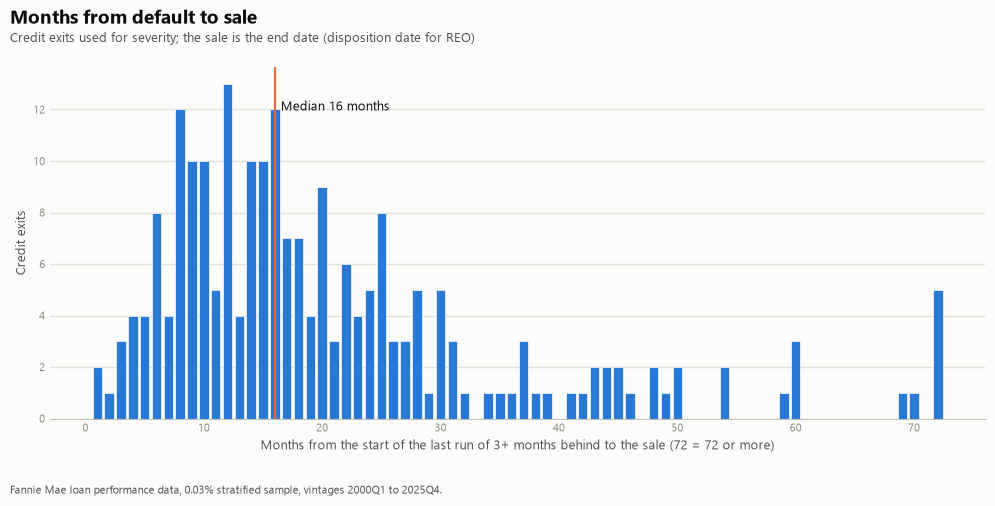

**Result.** For 221 exits the median time from the start of the last run of 3 or more months behind to the sale is 16 months (middle half 10 to 26, 90th percentile 44). 7 exits had no such run before the exit and 0 had a negative number of months (both left out).

In [60]:
# Months from the start of the last unbroken run of 3+ months behind to the end date.
if USED:
    dm_ = q("""SELECT e.code, datediff('month', a.run_start, e.end_date) AS months FROM credit_exits_ok e LEFT JOIN exit_arrears a ON a.loan_id = e.loan_id""")
    no_arrears = int(dm_["months"].isna().sum())
    neg_months = int((dm_["months"] < 0).sum())
    ok_ = dm_.dropna(subset=["months"])
    ok_ = ok_[ok_["months"] >= 0]
    summ = ok_.groupby("code")["months"].agg(exits="count", median="median", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75), p90=lambda s: s.quantile(0.90)).reset_index()
    summ = pd.concat([pd.DataFrame([{"code": "all", "exits": len(ok_), "median": ok_["months"].median(), "p25": ok_["months"].quantile(0.25), "p75": ok_["months"].quantile(0.75), "p90": ok_["months"].quantile(0.9)}]), summ], ignore_index=True)
    summ["reason"] = summ["code"].map(lambda c: EXIT_LABELS.get(c, "all credit exits"))
    save_table(summ, "eda_10_months_default_to_sale")
    if len(ok_):
        cnts = ok_["months"].clip(upper=72).value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(cnts.index, cnts.values, width=0.8, color=BLUE, edgecolor=BG, linewidth=0.5)
        ax.axvline(ok_["months"].median(), color=ORANGE, linewidth=1.5)
        ax.text(ok_["months"].median() + 0.5, cnts.max() * 0.95, f"Median {ok_['months'].median():.0f} months", color=INK, fontsize=9, va="top")
        ax.set_xlabel("Months from the start of the last run of 3+ months behind to the sale (72 = 72 or more)")
        ax.set_ylabel("Credit exits")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
        style_axes(ax, grid="y")
        save_chart(fig, "eda_10b_months_default_to_sale", "Months from default to sale", "Credit exits used for severity; the sale is the end date (disposition date for REO)")
        MONTHS_MED = float(ok_["months"].median())
        say(f"**Result.** For {n(len(ok_))} exits the median time from the start of the last run of 3 or more months behind to the sale is {MONTHS_MED:.0f} months (middle half {ok_['months'].quantile(0.25):.0f} to {ok_['months'].quantile(0.75):.0f}, "
            f"90th percentile {ok_['months'].quantile(0.9):.0f}). {n(no_arrears)} exits had no such run before the exit and {n(neg_months)} had a negative number of months (both left out).")
    else:
        MONTHS_MED = float("nan")
        say(f"**Result.** No exit has a usable run of 3 or more months behind ({n(no_arrears)} without one, {n(neg_months)} negative).")
else:
    MONTHS_MED = float("nan")
    say("**Result.** No usable credit exits.")

In [61]:
say("## Section 10 - What this shows, and which later module uses it")
say((f"On {n(USED)} credit exits the net loss is {SEV_ALL:.1f}% of the balance at removal (weighted), and the median exit takes {MONTHS_MED:.0f} months from the start of the last run of 3 or more months behind. " if USED and not np.isnan(MONTHS_MED) else
     (f"{n(USED)} credit exits are usable. " if USED else "No credit exits are usable in this scope. "))
    + f"{n(REO_NO_SALE)} REO exits with no disposition date and {n(NO_PROCEEDS)} exits with every proceeds field blank were left out. "
    + "Unpaid interest is missing from the data, so these are understated and are not an LGD. Module 4 (`04_lgd_ead`) builds the loss given default and sets the treatment of costs, proceeds and time to sale. "
      "The formula used here (net loss = balance at removal + costs - proceeds) goes to the reviewer before sign-off.")

## Section 10 - What this shows, and which later module uses it

On 228 credit exits the net loss is 26.2% of the balance at removal (weighted), and the median exit takes 16 months from the start of the last run of 3 or more months behind. 2 REO exits with no disposition date and 0 exits with every proceeds field blank were left out. Unpaid interest is missing from the data, so these are understated and are not an LGD. Module 4 (`04_lgd_ead`) builds the loss given default and sets the treatment of costs, proceeds and time to sale. The formula used here (net loss = balance at removal + costs - proceeds) goes to the reviewer before sign-off.

# Section 11 - Who is in and who is out

**Answers:** How do all loans narrow to the outcome population, and is the full-run 10% subset representative (full run only)?

### 11.1 Waterfall from all loans to the outcome population

**Why:** A model is built on fewer loans than the book. If the loans left out differ from the loans kept, the model may not describe the whole book.

**How:** Start with all loans. Remove loans with no first payment date, then loans not observed for 24 months (not yet observed), then excluded loans (left early or stopped reporting). What is left is bad plus good loans, counted separately so that check C6 can test that start minus the steps equals the end. Compare the median credit score, LTV and DTI of the loans kept with those left out.

**Answers:** How many loans remain at each step, and are the loans left out different?

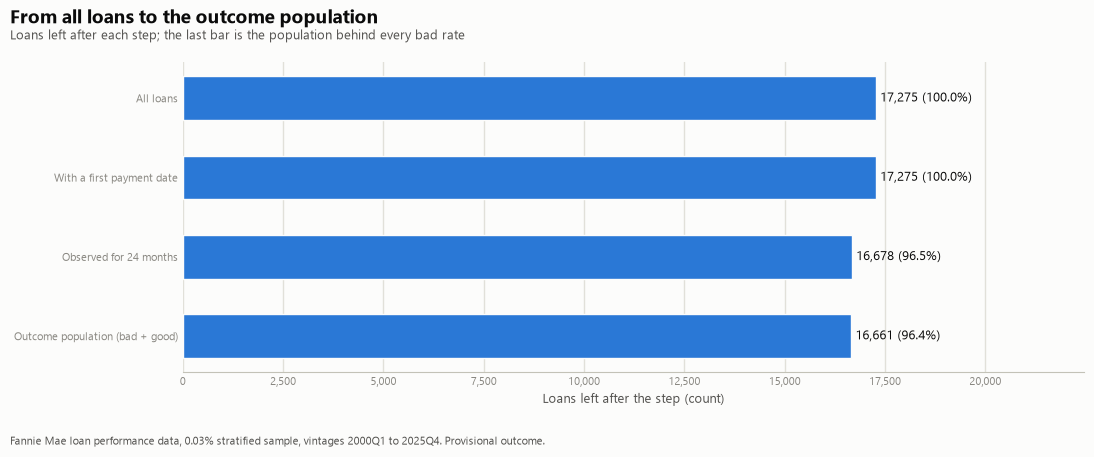

**Result.** Of 17,275 loans, 0 have no first payment date, 597 are not yet observed for 24 months and 17 are excluded, leaving 16,661 (96.4%). Median credit score, LTV and DTI of the kept loans: 759, 75, 34; of the loans left out: 773, 80, 39.

In [62]:
# Waterfall and the kept-against-left-out comparison.
med_sql = "median(credit_score) AS median_credit_score, median(orig_ltv) AS median_ltv, median(dti) AS median_dti"
step_sql = ("CASE WHEN first_payment_date IS NULL THEN 1 WHEN outcome = 'not yet observed' THEN 2 WHEN outcome = 'excluded' THEN 3 ELSE 4 END")
g = q(f"SELECT {step_sql} AS step, count(*) AS loans, {med_sql} FROM {LOANS_OUT} GROUP BY 1 ORDER BY 1").set_index("step")
left_out = q(f"SELECT count(*) AS loans, {med_sql} FROM {LOANS_OUT} WHERE {step_sql} < 4").iloc[0]
c = {k: int(g.loc[k, "loans"]) if k in g.index else 0 for k in (1, 2, 3, 4)}
WF_START, WF_STEPS, WF_END = LOANS_N, c[1] + c[2] + c[3], bad_n + good_n
labels = ["All loans", "With a first payment date", "Observed for 24 months", "Outcome population (bad + good)"]
left = [WF_START, WF_START - c[1], WF_START - c[1] - c[2], WF_START - c[1] - c[2] - c[3]]
medcols = ["median_credit_score", "median_ltv", "median_dti"]
wf = pd.DataFrame({"step": labels, "loans_left": left, "loans_removed": [0, c[1], c[2], c[3]]})
wf["pct_of_all_loans"] = 100.0 * wf["loans_left"] / WF_START
for mc in medcols:
    wf[mc + "_of_removed"] = [np.nan] + [g.loc[k, mc] if k in g.index else np.nan for k in (1, 2, 3)]
save_table(wf, "eda_11_waterfall")
kept = g.loc[4] if 4 in g.index else pd.Series({mc: np.nan for mc in medcols})
kl = pd.DataFrame([{"group": "kept (outcome population)", "loans": c[4], **{mc: kept[mc] for mc in medcols}},
                   {"group": "left out (all steps)", "loans": int(left_out["loans"]), **{mc: left_out[mc] for mc in medcols}}])
save_table(kl, "eda_11_kept_vs_left_out")
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(left))
ax.barh(y, left, height=0.55, color=BLUE, edgecolor=BG, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
for yi, v in zip(y, left):
    ax.text(v, yi, f" {v:,} ({100.0 * v / WF_START:.1f}%)", va="center", ha="left", fontsize=9)
ax.set_xlim(0, WF_START * 1.3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel("Loans left after the step (count)")
style_axes(ax, grid="x")
save_chart(fig, "eda_11a_waterfall", "From all loans to the outcome population", "Loans left after each step; the last bar is the population behind every bad rate", provisional=True)
headline.update({"outcome_population": WF_END, "outcome_population_pct": round(100.0 * WF_END / WF_START, 1)})
say(f"**Result.** Of {n(WF_START)} loans, {n(c[1])} have no first payment date, {n(c[2])} are not yet observed for 24 months and {n(c[3])} are excluded, leaving {n(WF_END)} ({pct(100.0 * WF_END / WF_START)}). "
    f"Median credit score, LTV and DTI of the kept loans: {kept['median_credit_score']:.0f}, {kept['median_ltv']:.0f}, {kept['median_dti']:.0f}; of the loans left out: "
    f"{left_out['median_credit_score']:.0f}, {left_out['median_ltv']:.0f}, {left_out['median_dti']:.0f}.")

### 11.2 Is the 10% deterministic subset representative? (full run only)

**Why:** Cure rates, exit curves and indexed LTV run on the 10% subset. They are only useful if the subset looks like the full data.

**How:** Compare the subset with the other 90% of loans: bad rate (Wilson 95% interval) and medians of credit score, LTV and DTI. The gap is in percentage points with a Newcombe interval, plus the ratio. The full data figures are shown for reference. On a sample run this step is not run.

**Answers:** Does the 10% subset have the same bad rate and the same typical loan as the rest?

In [63]:
# Subset representativeness check: in sample mode the whole DB is already the stratified sample.
# In full mode, compare the 10% deterministic slice (full_run_subset_loans) against the remaining ~90%.
if USE_SAMPLE:
    SUBSET_GAP = None
    say("**Result.** Not run in sample mode because the entire database is already the stratified sample.")
else:
    sub_cmp = q(f"""
        SELECT
            CASE WHEN s.loan_id IS NOT NULL THEN '10% deterministic subset' ELSE 'Remaining ~90%' END AS grp,
            count(*) AS loans,
            median(CAST(l.credit_score AS DOUBLE)) AS median_credit_score,
            median(CAST(l.orig_ltv AS DOUBLE)) AS median_orig_ltv,
            median(CAST(l.dti AS DOUBLE)) AS median_dti,
            {OUT_AGG.replace('outcome', 'o.outcome').replace('orig_upb', 'l.orig_upb')}
        FROM loans_table l
        JOIN loan_outcome o ON o.loan_id = l.loan_id
        LEFT JOIN {SUBSET_LOANS} s ON s.loan_id = l.loan_id
        GROUP BY 1
    """)
    sub_cmp = rate_by_count_and_balance(sub_cmp).set_index('grp')
    save_table(sub_cmp.reset_index(), 'eda_11_subset_vs_rest')
    a_, b_ = sub_cmp.loc['10% deterministic subset'], sub_cmp.loc['Remaining ~90%']
    SUBSET_GAP = diff_pp(int(a_['bad']), int(a_['outcome_loans']), int(b_['bad']), int(b_['outcome_loans']))
    say(f"**Result.** Subset bad rate {fmt_ci(int(a_['bad']), int(a_['outcome_loans']))} vs rest {fmt_ci(int(b_['bad']), int(b_['outcome_loans']))} "
        f"(gap {SUBSET_GAP[0]:+.3f} pp, 95% CI {SUBSET_GAP[1]:+.3f} to {SUBSET_GAP[2]:+.3f} pp).")


**Result.** Not run in sample mode because the entire database is already the stratified sample.

In [64]:
say("## Section 11 - What this shows, and which later module uses it")
say(f"{pct(100.0 * WF_END / WF_START)} of loans reach the outcome population. "
    f"The loans left out have median credit score {left_out['median_credit_score']:.0f} against {kept['median_credit_score']:.0f} for the kept loans, so "
    + ("the narrowing is not strongly biased on credit score. " if abs(left_out['median_credit_score'] - kept['median_credit_score']) <= 10 else "the narrowing is biased on credit score and Module 3 must say so in its representativeness note. ")
    + ("The subset check was not run on a sample run. " if USE_SAMPLE else ("The 10% deterministic subset matches the rest on the bad rate (gap interval includes zero), so month-by-month results from the subset can be trusted. " if SUBSET_GAP and SUBSET_GAP[1] <= 0 <= SUBSET_GAP[2] else "The 10% subset differs from the rest on the bad rate, so month-by-month results from it need care. "))
    + "Module 3 (`03_rating_and_pd`) uses the outcome population as its development base.")

## Section 11 - What this shows, and which later module uses it

96.4% of loans reach the outcome population. The loans left out have median credit score 773 against 759 for the kept loans, so the narrowing is biased on credit score and Module 3 must say so in its representativeness note. The subset check was not run on a sample run. Module 3 (`03_rating_and_pd`) uses the outcome population as its development base.

# Section 12 - Fields with many values

**Answers:** How concentrated are sellers and servicers, and how sparse are the MSA and ZIP3 groups?

### 12.1 Seller and servicer concentration

**Why:** A few sellers or servicers holding most of the book is a concentration risk, and the names cannot go into a scorecard as they are.

**How:** Count loans per seller (`loans_table`) and loan-months per servicer (scan 4, the monthly view grouped by servicer name). Show the share held by the top 5, 10 and 20, and the concentration index (Herfindahl: the sum of squared shares; one divided by it is the number of equal-sized firms that would give the same concentration). Blank names are left out.

**Answers:** How concentrated are sellers and servicers?

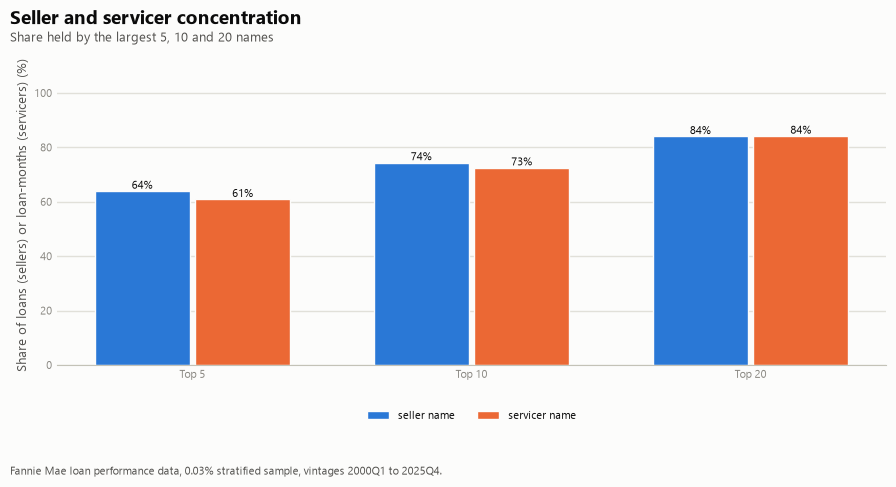

**Result.** seller_name: 130 names, top 5 hold 63.9%, top 10 74.4%, top 20 84.0%, concentration index 0.1616 (like 6 equal-sized firms); servicer_name: 126 names, top 5 hold 60.9%, top 10 72.5%, top 20 84.1%, concentration index 0.1382 (like 7 equal-sized firms).

In [65]:
# Top 5, 10, 20 shares and Herfindahl index for sellers and servicers.
def concentration(name, obj, d):
    d = d.sort_values("n", ascending=False)
    tot = d["n"].sum()
    sh = d["n"] / tot
    return {"field": name, "measured_on": obj, "distinct_values": len(d), "top_1_pct": 100 * sh.iloc[:1].sum(), "top_5_pct": 100 * sh.iloc[:5].sum(), "top_10_pct": 100 * sh.iloc[:10].sum(),
            "top_20_pct": 100 * sh.iloc[:20].sum(), "herfindahl_index": float((sh ** 2).sum()), "equal_sized_firms": float(1 / (sh ** 2).sum())}


sellers = q(f"SELECT seller_name AS v, count(*) AS n FROM {LOANS} WHERE seller_name IS NOT NULL AND trim(seller_name) <> '' GROUP BY 1")
servicers = q(f"SELECT servicer_name AS v, count(*) AS n FROM {MONTHLY} WHERE servicer_name IS NOT NULL AND trim(servicer_name) <> '' GROUP BY 1")
conc = pd.DataFrame([concentration("seller_name", "loans", sellers), concentration("servicer_name", "loan-months", servicers)])
save_table(conc, "eda_12_concentration")
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(3)
for i_, (_, r) in enumerate(conc.iterrows()):
    vals = [r["top_5_pct"], r["top_10_pct"], r["top_20_pct"]]
    ax.bar(x + (i_ - 0.5) * 0.36, vals, width=0.34, color=PALETTE[i_], label=r["field"].replace("_", " "), edgecolor=BG)
    for xx, v in zip(x + (i_ - 0.5) * 0.36, vals):
        ax.text(xx, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(["Top 5", "Top 10", "Top 20"])
ax.set_ylim(0, 110)
ax.set_ylabel("Share of loans (sellers) or loan-months (servicers) (%)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
style_axes(ax, grid="y")
save_chart(fig, "eda_12a_concentration", "Seller and servicer concentration", "Share held by the largest 5, 10 and 20 names")
say("**Result.** " + "; ".join(f"{r['field']}: {n(r['distinct_values'])} names, top 5 hold {pct(r['top_5_pct'])}, top 10 {pct(r['top_10_pct'])}, top 20 {pct(r['top_20_pct'])}, concentration index {r['herfindahl_index']:.4f} (like {r['equal_sized_firms']:.0f} equal-sized firms)" for _, r in conc.iterrows()) + ".")

### 12.2 Sparse MSA and ZIP3 groups

**Why:** Small geographic groups give unstable rates. They should be pooled before they are used.

**How:** Count loans per MSA and per ZIP3. Report how many groups have fewer than `MIN_CELL` loans and what share of all loans they hold. The suggested treatment is to pool such groups into 'other in the same state'.

**Answers:** How many geographic groups are too small to stand alone?

In [66]:
# Groups below MIN_CELL loans, for MSA and ZIP3.
rows = []
for f in ["msa", "zip3"]:
    d = q(f"SELECT {f} AS v, count(*) AS n FROM {LOANS} WHERE {f} IS NOT NULL GROUP BY 1")
    small = d["n"] < MIN_CELL
    blank_n = int(con.execute(f"SELECT count(*) FROM {LOANS} WHERE {f} IS NULL").fetchone()[0])
    rows.append({"field": f, "groups": len(d), "groups_below_min_cell": int(small.sum()), "pct_of_groups": 100.0 * small.mean() if len(d) else np.nan,
                 "loans_in_small_groups": int(d.loc[small, "n"].sum()), "pct_of_loans": 100.0 * d.loc[small, "n"].sum() / LOANS_N, "loans_blank": blank_n})
sparse = pd.DataFrame(rows)
save_table(sparse, "eda_12_sparse_groups")
say("**Result.** " + "; ".join(f"`{r['field']}`: {n(r['groups'])} groups, {n(r['groups_below_min_cell'])} ({pct(r['pct_of_groups'])}) with fewer than {MIN_CELL:,} loans, holding {pct(r['pct_of_loans'], 2)} of loans" for _, r in sparse.iterrows())
    + ". Such groups should be pooled into 'other in the same state' before any rate is read from them.")

**Result.** `msa`: 411 groups, 310 (75.4%) with fewer than 30 loans, holding 17.05% of loans; `zip3`: 824 groups, 636 (77.2%) with fewer than 30 loans, holding 35.78% of loans. Such groups should be pooled into 'other in the same state' before any rate is read from them.

In [67]:
say("## Section 12 - What this shows, and which later module uses it")
say(f"The top 10 sellers hold {pct(conc.loc[0, 'top_10_pct'])} of loans and the top 10 servicers {pct(conc.loc[1, 'top_10_pct'])} of loan-months, so names can be grouped as top names plus other. "
    f"{pct(sparse.loc[sparse['field'] == 'msa', 'pct_of_loans'].iloc[0], 2)} of loans are in MSAs with fewer than {MIN_CELL:,} loans and {pct(sparse.loc[sparse['field'] == 'zip3', 'pct_of_loans'].iloc[0], 2)} in such ZIP3 groups. "
    "Module 2 (`05_concentrations.py`) reports the concentration view for the committee; Module 3 (`03_rating_and_pd`) decides the grouping.")

## Section 12 - What this shows, and which later module uses it

The top 10 sellers hold 74.4% of loans and the top 10 servicers 72.5% of loan-months, so names can be grouped as top names plus other. 17.05% of loans are in MSAs with fewer than 30 loans and 35.78% in such ZIP3 groups. Module 2 (`05_concentrations.py`) reports the concentration view for the committee; Module 3 (`03_rating_and_pd`) decides the grouping.

# Section 13 - Checking the story

**Answers:** Do the main risk gaps hold within credit score and LTV bands, or are they only a mix effect?

### 13.1 Loan purpose within credit score bands, occupancy within LTV bands

**Why:** Refinances may look riskier than purchases only because they have lower credit scores. If the gap holds inside each credit score band it is a real effect, not a mix effect. The same test applies to occupancy within LTV bands.

**How:** Bad rate (Wilson 95% interval) by loan purpose within 6 credit score bands, and by occupancy within 6 LTV bands. The gap to the reference group (purchase; owner-occupied) in the same band is given in percentage points with a Newcombe interval, and as a ratio. Cells with fewer than `MIN_CELL` outcome loans are folded into 'other' in their band and have no gap. The text says whether each gap keeps its sign in every band.

**Answers:** Does the gap hold in every band?

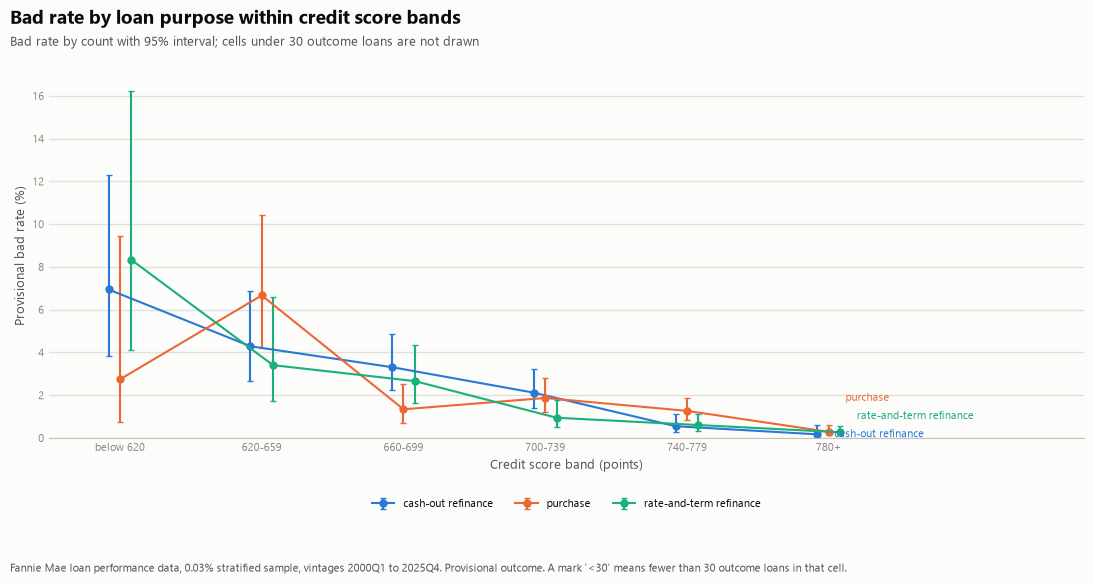

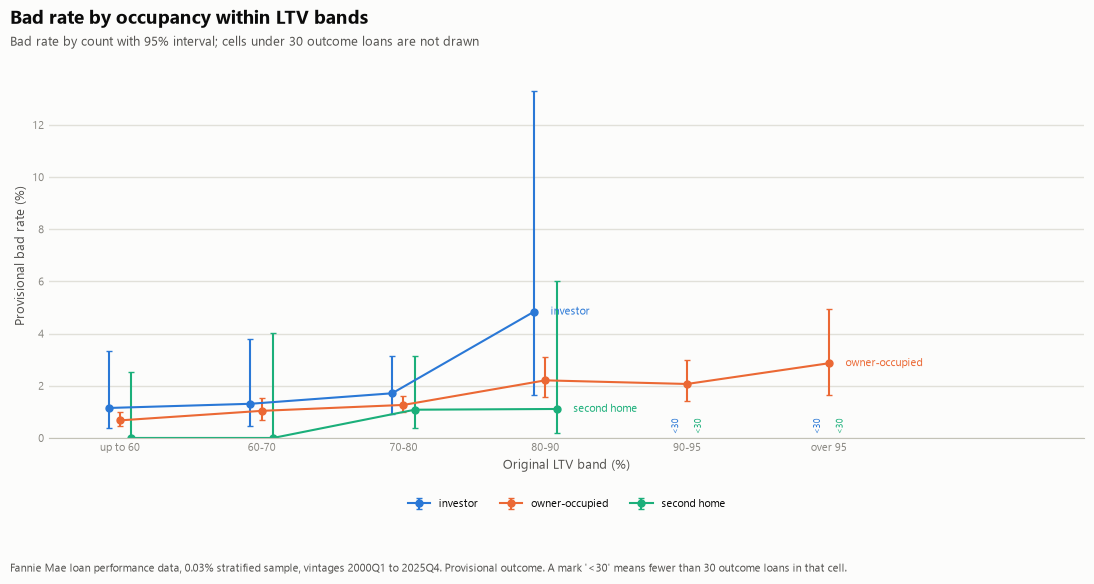

**Result.** Loan purpose within credit score bands (reference: purchase): cash-out refinance does not keep the same sign in every band (3 higher, 3 lower of 6); the interval excludes 0 in 2 of 6 bands; rate-and-term refinance does not keep the same sign in every band (2 higher, 4 lower of 6); the interval excludes 0 in 1 of 6 bands. Occupancy within LTV bands (reference: owner-occupied): investor is higher than the reference in all 4 bands; the interval excludes 0 in 0 of 4 bands; second home is lower than the reference in all 4 bands; the interval excludes 0 in 0 of 4 bands.

In [68]:
# Bad rate by group within bands, and the gap to the reference group in the same band.
FIELDS_USED["13"] |= {"credit_score", "loan_purpose", "orig_ltv", "occupancy"}


def within_bands(group_col, band_sql, band_names, ref, names, nulls):
    d = q(f"SELECT {band_sql} AS b, coalesce(CAST({group_col} AS VARCHAR), 'blank') AS grp, {OUT_AGG} FROM {LOANS_OUT} WHERE outcome IN ('bad', 'good') AND {nulls} GROUP BY 1, 2")
    out = []
    for b_ in range(len(band_names)):
        s = d[d["b"] == b_].copy()
        if s.empty:
            continue
        s["outcome_loans"] = s["bad"] + s["good"]
        small = s["outcome_loans"] < MIN_CELL
        keep = s[~small]
        if small.any():
            keep = pd.concat([keep, pd.DataFrame([{"b": b_, "grp": "other", **{c: s.loc[small, c].sum() for c in ["bad", "good", "bad_upb", "good_upb"]}}])], ignore_index=True)
        keep = rate_by_count_and_balance(keep)
        refrow = keep[keep["grp"] == ref]
        for _, r in keep.iterrows():
            gap = diff_pp(r["bad"], r["outcome_loans"], refrow["bad"].iloc[0], refrow["outcome_loans"].iloc[0]) if (len(refrow) and r["grp"] not in (ref, "other")) else (np.nan,) * 4
            out.append({"band": band_names[b_], "group": r["grp"], "group_name": names.get(r["grp"], r["grp"]), "outcome_loans": int(r["outcome_loans"]), "bad": int(r["bad"]),
                        "bad_rate_count_pct": r["bad_rate_count_pct"], "ci_low_pct": r["ci_low_pct"], "ci_high_pct": r["ci_high_pct"], "bad_rate_balance_pct": r["bad_rate_balance_pct"],
                        "gap_to_reference_pp": gap[0], "gap_low_pp": gap[1], "gap_high_pp": gap[2], "ratio_to_reference": gap[3]})
    return pd.DataFrame(out)


def sign_text(df, ref, label):
    parts = []
    for gname in [g_ for g_ in df["group"].unique() if g_ not in (ref, "other")]:
        s = df[(df["group"] == gname) & df["gap_to_reference_pp"].notna()]
        if len(s) < 3:
            parts.append(f"{label[gname]}: only {len(s)} band(s) with enough loans, too few to judge")
            continue
        excl = int(((s["gap_low_pp"] > 0) | (s["gap_high_pp"] < 0)).sum())
        tail = f"; the interval excludes 0 in {excl} of {len(s)} bands"
        if (s["gap_to_reference_pp"] > 0).all():
            parts.append(f"{label[gname]} is higher than the reference in all {len(s)} bands{tail}")
        elif (s["gap_to_reference_pp"] < 0).all():
            parts.append(f"{label[gname]} is lower than the reference in all {len(s)} bands{tail}")
        else:
            parts.append(f"{label[gname]} does not keep the same sign in every band ({int((s['gap_to_reference_pp'] > 0).sum())} higher, {int((s['gap_to_reference_pp'] < 0).sum())} lower of {len(s)}){tail}")
    return "; ".join(parts)


def draw_within(df, name, title, sub, ref, label_map, xlabel):
    groups = [g_ for g_ in df["group"].unique() if g_ != "other"]   # folded cells stay in the table, not on the chart
    bands_ = list(dict.fromkeys(df["band"]))
    fig, ax = plt.subplots(figsize=(11, 5.8))
    ends = []
    for i_, g_ in enumerate(groups):
        s = df[df["group"] == g_].set_index("band").reindex(bands_)
        x = np.arange(len(bands_)) + (i_ - (len(groups) - 1) / 2) * 0.08
        colr = PALETTE[i_ % len(PALETTE)]
        ax.errorbar(x, s["bad_rate_count_pct"], yerr=[(s["bad_rate_count_pct"] - s["ci_low_pct"]).fillna(0), (s["ci_high_pct"] - s["bad_rate_count_pct"]).fillna(0)],
                    fmt="-o", color=colr, ecolor=colr, capsize=2, markersize=5, linewidth=1.5, label=label_map.get(g_, g_))
        ok = s["bad_rate_count_pct"].dropna()
        if len(ok):
            ends.append((x[bands_.index(ok.index[-1])], ok.iloc[-1], label_map.get(g_, g_), colr))
    ax.set_xticks(range(len(bands_)))
    ax.set_xticklabels(bands_)
    ax.set_xlim(-0.5, len(bands_) + 0.8)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Provisional bad rate (%)")
    style_axes(ax, grid="y")
    label_ends(ax, ends)
    ymax = ax.get_ylim()[1]
    for i_, g_ in enumerate(groups):
        s = df[df["group"] == g_].set_index("band").reindex(bands_)
        for j_, b_ in enumerate(bands_):
            if pd.isna(s["bad_rate_count_pct"].iloc[j_]):
                ax.text(j_ + (i_ - (len(groups) - 1) / 2) * 0.08, 0.01 * ymax, f"<{MIN_CELL:,}", rotation=90, fontsize=6.5, color=PALETTE[i_ % len(PALETTE)], ha="center", va="bottom")
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=max(len(groups), 1))
    save_chart(fig, name, title, sub, provisional=True, note=f"A mark '<{MIN_CELL:,}' means fewer than {MIN_CELL:,} outcome loans in that cell.")


P_NAMES = CODE_LABELS["loan_purpose"]
O_NAMES = CODE_LABELS["occupancy"]
purpose_fico = within_bands("loan_purpose", score_case, SCORE_BANDS, "P", P_NAMES, "credit_score IS NOT NULL")
occ_ltv = within_bands("occupancy", ltv_case, LTV_BANDS, "P", O_NAMES, "orig_ltv IS NOT NULL")
save_table(purpose_fico, "eda_13_purpose_within_fico")
save_table(occ_ltv, "eda_13_occupancy_within_ltv")
draw_within(purpose_fico, "eda_13a_purpose_within_fico", "Bad rate by loan purpose within credit score bands", f"Bad rate by count with 95% interval; cells under {MIN_CELL:,} outcome loans are not drawn", "P", P_NAMES, "Credit score band (points)")
draw_within(occ_ltv, "eda_13b_occupancy_within_ltv", "Bad rate by occupancy within LTV bands", f"Bad rate by count with 95% interval; cells under {MIN_CELL:,} outcome loans are not drawn", "P", O_NAMES, "Original LTV band (%)")
t1, t2 = sign_text(purpose_fico, "P", P_NAMES), sign_text(occ_ltv, "P", O_NAMES)
say("**Result.** Loan purpose within credit score bands (reference: purchase): " + (t1 or "no group has enough loans") + ". Occupancy within LTV bands (reference: owner-occupied): " + (t2 or "no group has enough loans") + ".")

In [69]:
say("## Section 13 - What this shows, and which later module uses it")
say(f"Within credit score bands: {t1 or 'no comparison possible'}. Within LTV bands: {t2 or 'no comparison possible'}. "
    "A gap that keeps its sign in every band is a real effect and not only a mix effect, and Module 3 (`03_rating_and_pd`) should keep the field; "
    "a gap that changes sign is mostly a mix effect of credit score or LTV. Occupancy and purpose also feed the exposure grouping in Module 6 (`06_basel_capital`).")

## Section 13 - What this shows, and which later module uses it

Within credit score bands: cash-out refinance does not keep the same sign in every band (3 higher, 3 lower of 6); the interval excludes 0 in 2 of 6 bands; rate-and-term refinance does not keep the same sign in every band (2 higher, 4 lower of 6); the interval excludes 0 in 1 of 6 bands. Within LTV bands: investor is higher than the reference in all 4 bands; the interval excludes 0 in 0 of 4 bands; second home is lower than the reference in all 4 bands; the interval excludes 0 in 0 of 4 bands. A gap that keeps its sign in every band is a real effect and not only a mix effect, and Module 3 (`03_rating_and_pd`) should keep the field; a gap that changes sign is mostly a mix effect of credit score or LTV. Occupancy and purpose also feed the exposure grouping in Module 6 (`06_basel_capital`).

# Section 14 - Summary and hand-off

**Answers:** What are the headline numbers, what did the EDA find for each field, and what is left open for later modules?

### 14.1 Headline numbers

**Why:** The numbers that matter most should be in one place, and on file.

**How:** Collect the headline numbers worked out in the sections above, from the variables the code holds, and save them.

**Answers:** What are the headline numbers of this run?

In [70]:
# Headline numbers, collected from the computed values.
hl = {
    "run scope": SCOPE_LABEL, "min cell threshold": MIN_CELL, "loans in scope": LOANS_N, "monthly rows": MONTHLY_ROWS_BY_MONTH, "original balance": f"{ORIG_UPB:,.2f}",
    "vintages": VINTAGE_N, "first and last reporting month": f"{FIRST_MONTH:%Y-%m} to {LAST_MONTH:%Y-%m}",
    "bad": bad_n, "good": good_n, "excluded": OUTCOME_N["excluded"], "not yet observed": OUTCOME_N["not yet observed"],
    "bad rate by count (%)": round(BAD_RATE, 2), "bad rate by balance (%)": round(bal_rate, 2),
    "outcome population": WF_END, "values failing conversion": CONV_FAILS,
    "impossible-value rules with findings": len(found), "strongest origination field by IV": f"{iv_df['field'].iloc[0]} ({iv_df['information_value'].iloc[0]:.3f})",
    "numeric pairs above 0.7": len(HIGH_PAIRS), "fields with VIF above 10": int(vif["above_10"].sum()),
    "fields with PSI above 0.25 in some era": int((PSI_MAX > 0.25).sum()) if len(PSI_MAX) else "not worked out",
    "peak active loans": f"{headline['active_peak']:,} ({headline['active_peak_month']})",
    "loan-months under plan or deferral": headline.get("relief_loan_months", 0), "bad loans that relief months explain": moved,
    "credit exits used for severity": USED, "severity weighted by balance (%)": round(SEV_ALL, 1) if USED else "n/a",
    "median months from default to sale": round(MONTHS_MED, 1) if USED and not np.isnan(MONTHS_MED) else "n/a",
    "subset bad rate gap (percentage points)": round(SUBSET_GAP[0], 3) if SUBSET_GAP else "not run (sample)",
}
headline_df = pd.DataFrame({"metric": list(hl.keys()), "value": [str(v) for v in hl.values()]})
save_table(headline_df, "eda_14_headline_numbers")
say("**Headline numbers**\n\n" + md_table(headline_df))

**Headline numbers**

| metric | value |
|---|---|
| run scope | 0.03% stratified sample |
| min cell threshold | 30 |
| loans in scope | 17275 |
| monthly rows | 994063 |
| original balance | 3,783,343,000.00 |
| vintages | 104 |
| first and last reporting month | 2000-01 to 2025-12 |
| bad | 215 |
| good | 16446 |
| excluded | 17 |
| not yet observed | 597 |
| bad rate by count (%) | 1.29 |
| bad rate by balance (%) | 1.45 |
| outcome population | 16661 |
| values failing conversion | 0 |
| impossible-value rules with findings | 1 |
| strongest origination field by IV | credit_score (0.913) |
| numeric pairs above 0.7 | 4 |
| fields with VIF above 10 | 2 |
| fields with PSI above 0.25 in some era | 7 |
| peak active loans | 4,746 (2024-09) |
| loan-months under plan or deferral | 8681 |
| bad loans that relief months explain | 57 |
| credit exits used for severity | 228 |
| severity weighted by balance (%) | 26.2 |
| median months from default to sale | 16.0 |
| subset bad rate gap (percentage points) | not run (sample) |

### 14.2 Findings per field

**Why:** One table with the catalogue columns and the EDA findings side by side is what the later modules read. It is joined to `feature_catalogue_table` and is not a second register.

**How:** Start from every row of `feature_catalogue_table` and add, by field name and source object: information value, largest PSI against recovery, VIF, the blank-against-filled gap, and the impossible-value count. Fields the EDA did not test stay blank. Saved as a CSV.

**Answers:** What did the EDA find for each field?

In [71]:
# Findings joined to the feature catalogue (left join on field_name and source_object).
cat = q("SELECT * FROM feature_catalogue_table ORDER BY source_object, layout_position")
f_rows = {}
for f, v in IV.items():
    f_rows.setdefault(("loans_table", f), {})["information_value"] = v
for f, v in PSI_MAX.items():
    f_rows.setdefault(("loans_table", f), {})["largest_psi_vs_recovery"] = v
for f, v in VIF.items():
    f_rows.setdefault(("loans_table", f), {})["vif"] = v
for _, r in blank_vs_filled.iterrows():
    f_rows.setdefault(("loans_table", r["field"]), {})["blank_vs_filled_gap_pp"] = r["gap_pp"]
imp_ = impossible.groupby(["object", "field"])["rows_found"].sum()
for (o_, f), v in imp_.items():
    f_rows.setdefault((OBJECT_NAME[o_], f), {})["impossible_values"] = int(v)
findings = pd.DataFrame([{"field_name": f, "source_object": o_, **d_} for (o_, f), d_ in f_rows.items()])
for col in ["information_value", "largest_psi_vs_recovery", "vif", "blank_vs_filled_gap_pp", "impossible_values"]:
    if col not in findings.columns:
        findings[col] = np.nan
field_findings = cat.merge(findings, on=["field_name", "source_object"], how="left")
save_table(field_findings, "eda_14_field_findings")
tested = field_findings[field_findings[["information_value", "largest_psi_vs_recovery", "vif", "blank_vs_filled_gap_pp", "impossible_values"]].notna().any(axis=1)]
say(f"**Result.** `eda_14_field_findings.csv` has {n(len(field_findings))} rows (one per catalogue field, joined to `feature_catalogue_table`). {n(len(tested))} fields carry at least one EDA finding: "
    f"{int(field_findings['information_value'].notna().sum())} with an information value, {int(field_findings['largest_psi_vs_recovery'].notna().sum())} with a PSI, "
    f"{int(field_findings['vif'].notna().sum())} with a VIF, {int(field_findings['blank_vs_filled_gap_pp'].notna().sum())} with a blank-against-filled gap and {int(field_findings['impossible_values'].notna().sum())} with an impossible-value count.")

**Result.** `eda_14_field_findings.csv` has 78 rows (one per catalogue field, joined to `feature_catalogue_table`). 26 fields carry at least one EDA finding: 17 with an information value, 17 with a PSI, 8 with a VIF, 9 with a blank-against-filled gap and 17 with an impossible-value count.

### 14.3 Open items for later modules

Each item names the module and script that takes it. These are fixed notes, not results.

- **Default definition and outcome window** - Module 2, `02_default_engine.py`. Replace `build_loan_outcome()` with a read of the signed-off default definition and rerun this notebook. Decide how payment deferrals and forbearance count (section 09 gives the size of the question). The cure rates in section 07 are support for the 90-day line, not the decision. Any UK rule is cited only after the source-checker has confirmed its wording.
- **Roll rates and cure behaviour** - Module 2, `03_roll_rates.py`.
- **Vintage curves, prepayment and competing risks** - Module 2, `04_vintage_curves.py`. Start curves from the origination date and allow for loans that enter the data late (section 03).
- **Concentrations** - Module 2, `05_concentrations.py`. Pool small MSA and ZIP3 groups into "other in the same state" (section 12).
- **Field choice, blanks, spikes, repeating pairs and transformations** - Module 3, `03_rating_and_pd`. Fields above 0.5 information value are checked for leakage in `03_leakage_audit.py` first.
- **Severity, indexed LTV, months to sale** - Module 4, `04_lgd_ead`. Unpaid interest is not in the data, so severity here is understated and is not an LGD.
- **Prepayment speed and economic lags** - Module 5 (`05_ifrs9_ecl`) and Module 7 (`07_stress_testing`). Economic series must be lagged by at least their publication delay (section 02).
- **Risk weights by occupancy and LTV** - Module 6, `06_basel_capital`. Section 07 only describes the spread.
- **Reruns after the full build** - run the post-load checks, rerun the fixed macro script, then the leakage audit and the feature catalogue, then this notebook on the default sample (`EDA_FULL=0`) and with `EDA_FULL=1`.
- **UK rules** - where the US data departs from UK rules, see `docs\departures_from_uk_rules.md` (D-025).

In [72]:
say("## Section 14 - What this shows, and which later module uses it")
say(f"This run covers {n(LOANS_N)} loans; the provisional bad rate is {fmt_ci(bad_n, bad_n + good_n)} on {n(WF_END)} outcome loans. "
    f"{n(len(tested))} of {n(len(field_findings))} catalogue fields carry an EDA finding in `eda_14_field_findings.csv`. "
    "The open items above go to Modules 2, 3, 4, 5, 6 and 7 as named; nothing here sets the default definition.")

## Section 14 - What this shows, and which later module uses it

This run covers 17,275 loans; the provisional bad rate is 1.29% (1.13% to 1.47%) on 16,661 outcome loans. 26 of 78 catalogue fields carry an EDA finding in `eda_14_field_findings.csv`. The open items above go to Modules 2, 3, 4, 5, 6 and 7 as named; nothing here sets the default definition.

# Section 15 - Automatic checks

**Answers:** Did every total add up? The run stops with an error if any check fails.

### 15.1 Checks C1 to C8

**Why:** A run that does not reconcile must not be trusted. This cell runs eight checks, prints a short summary and stops with an error if any check fails.

**How:** C1 loans in scope = loans in `loans_table` (or in the subset on a sample run). C2 monthly rows by vintage = by month = the ledger total (ledger not run on a sample). C3 vintages = rows in `loaded_quarters_table`. C4 histogram bins + blanks = loans. C5 bad + good + excluded + not yet observed = loans. C6 waterfall start minus steps = end. C7 every output in the list exists and is not empty. C8 no quarantined field is used in sections 05, 06 or 13.

**Answers:** Does the run reconcile?

In [73]:
# Checks C1 to C8, the printed summary and the final pass or fail.
expected_loans = con.execute("SELECT count(*) FROM loans_table").fetchone()[0]
checks = []
checks.append(("C1", LOANS_N == expected_loans, f"Loans in scope {LOANS_N:,} = {'subset' if USE_SAMPLE else 'loans_table'} {expected_loans:,}"))
c2 = MONTHLY_ROWS_BY_VINTAGE == MONTHLY_ROWS_BY_MONTH
c2_text = f"Monthly rows by vintage {MONTHLY_ROWS_BY_VINTAGE:,} = by month {MONTHLY_ROWS_BY_MONTH:,}"
if USE_SAMPLE:
    c2_text += "; ledger total not run (sample)"
else:
    c2 = c2 and MONTHLY_ROWS_BY_VINTAGE == LEDGER_MONTHLY
    c2_text += f" = ledger {LEDGER_MONTHLY:,}"
checks.append(("C2", c2, c2_text))
checks.append(("C3", VINTAGE_N == len(LOADED), f"Vintages {VINTAGE_N} = loaded_quarters_table rows {len(LOADED)}"))
checks.append(("C4", all(v == LOANS_N for v in hist_totals.values()), f"Histogram bins + blanks = loans for {len(hist_totals)} fields"))
oc_check = con.execute("SELECT count(*), count(DISTINCT loan_id) FROM loan_outcome").fetchone()
c5 = sum(OUTCOME_N.values()) == LOANS_N and oc_check[0] == LOANS_N and oc_check[1] == LOANS_N
checks.append(("C5", c5, f"Bad + good + excluded + not yet observed = {sum(OUTCOME_N.values()):,} = loans {LOANS_N:,}"))
checks.append(("C6", WF_START - WF_STEPS == WF_END, f"Waterfall: start {WF_START:,} - steps {WF_STEPS:,} = end {WF_END:,}"))
files_ok = [p for p in OUTPUTS if p.exists() and p.stat().st_size > 0]
checks.append(("C7", len(files_ok) == len(OUTPUTS) and len(OUTPUTS) > 0 and len(set(OUTPUTS)) == len(OUTPUTS), f"Files in the list present and not empty: {len(files_ok)} of {len(OUTPUTS)}"))
used_quarantined = {s: sorted(f for f in fs if f in QUARANTINED) for s, fs in FIELDS_USED.items()}
c8 = all(len(v) == 0 for v in used_quarantined.values())
checks.append(("C8", c8, "No quarantined field used in sections 05, 06 or 13 (" + ", ".join(f"{s}: {len(f)} fields" for s, f in FIELDS_USED.items()) + ")"))
overall = all(ok for _, ok, _ in checks)
elapsed = int(time.time() - T0)

print(f"02_eda.ipynb on {DB_PATH.name} ({SCOPE_LABEL}); files to {OUT_DIR}")
print(f"Loans {LOANS_N:,}; monthly rows {MONTHLY_ROWS_BY_MONTH:,}; original balance {ORIG_UPB:,.2f}; vintages {VINTAGE_N}")
print(f"Outcome: bad {bad_n:,}, good {good_n:,}, excluded {OUTCOME_N['excluded']:,}, not yet observed {OUTCOME_N['not yet observed']:,}; bad rate {BAD_RATE:.2f}%")
print(f"Charts {sum(p.suffix == '.png' for p in OUTPUTS)}, tables {sum(p.suffix == '.csv' for p in OUTPUTS)}; conversion failures {CONV_FAILS:,}")
for cid, ok, text in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {cid} {text}")
print(f"Run time: {elapsed // 60}m {elapsed % 60}s")
print("OVERALL: " + ("PASS" if overall else "FAIL"))

# Remove the spill folder if it is empty.
try:
    con.close()
    SPILL_DIR.rmdir()
except OSError:
    pass
if not overall:
    raise RuntimeError("OVERALL: FAIL - see the FAIL lines above")

02_eda.ipynb on mortgages_sample.duckdb (0.03% stratified sample); files to E:\Repos\V4_bank-credit-risk-platform\residential_mortgage\00_data\processed\module_outputs\01_data_foundation\sample\02_eda
Loans 17,275; monthly rows 994,063; original balance 3,783,343,000.00; vintages 104
Outcome: bad 215, good 16,446, excluded 17, not yet observed 597; bad rate 1.29%
Charts 34, tables 56; conversion failures 0
PASS  C1 Loans in scope 17,275 = subset 17,275
PASS  C2 Monthly rows by vintage 994,063 = by month 994,063; ledger total not run (sample)
PASS  C3 Vintages 104 = loaded_quarters_table rows 104
PASS  C4 Histogram bins + blanks = loans for 7 fields
PASS  C5 Bad + good + excluded + not yet observed = 17,275 = loans 17,275
PASS  C6 Waterfall: start 17,275 - steps 614 = end 16,661
PASS  C7 Files in the list present and not empty: 90 of 90
PASS  C8 No quarantined field used in sections 05, 06 or 13 (05: 17 fields, 06: 20 fields, 13: 4 fields)
Run time: 0m 43s
OVERALL: PASS
